In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Contrastive SSL for histopathologic cancer detection using Pcam dataset
- dataset: PatchCamelyon
- Model: SSL [ SimCLR ] + linear layer on top
- Optimizer: AdamW
- Training Set: 58k test_file images + 80k train_file images
- Linear Eval Set: 70k train_file images
- Eval Set: 70k train_file images

### Data Augmentations
- color jitter : will make up for staining variations of cells
- inversions: they are biologically invariant
- rotations: biologically invariant
- blurr: mild; just for focus differences
- no cropping: its already 96x96, cropping and resizing will make it lose info

## Imports

In [3]:
!pip install kagglehub
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 14.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [4]:
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
from torch.utils.data import Dataset,DataLoader
from PIL import Image
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms.functional as TF
import torchvision.transforms.v2 as T
import torchmetrics.functional as TMF
import itertools
import kagglehub
from sklearn.manifold import TSNE
import gc

In [98]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)
torch.backends.cudnn.deterministic=True

## Data Augmentations
- Color Jitter
- Inversions
- blurr

In [6]:
CJ=T.RandomApply([T.ColorJitter(0.4,0.4,0.2,0.1)],p=0.8)
HINV=T.RandomHorizontalFlip(p=0.5)
VINV=T.RandomVerticalFlip(p=0.5)
BL=T.RandomApply([T.GaussianBlur(9,(0.1,1.0))],p=0.5)
norm=T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
def denorm(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)
transformation_pipeline=torchvision.transforms.Compose([
    CJ,
    HINV,
    VINV,
    BL,
])

In [7]:
def data_augmentation(z):
    z=transformation_pipeline(z)

    z=norm(z)
    return z

## Dataset Loader

In [8]:
kagglehub.login()
# KGAT_acfbbf89388585d8871087cc0855d3c5

Kaggle credentials set.
Kaggle credentials successfully validated.


In [9]:
path = kagglehub.competition_download('histopathologic-cancer-detection')

print("Path to competition files:", path)

100%|██████████| 6.31G/6.31G [01:50<00:00, 61.5MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/histopathologic-cancer-detection


In [10]:
train_list=[]
layer_list=[]
test_list=[]
labels={}
labels_df=pd.read_csv("/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/train_labels.csv")
labels=pd.Series(labels_df.label.values,index=labels_df.id)
input_dir="/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/test"
for file in sorted(os.listdir(input_dir)):
            if file.endswith(".tif"):
                train_list.append(f"{input_dir}/{file}")
i=0
input_dir="/root/.cache/kagglehub/competitions/histopathologic-cancer-detection/train"
for file in sorted(os.listdir(input_dir)):
            if file.endswith(".tif"):
                i+=1
                if(i<=80000):
                    train_list.append(f"{input_dir}/{file}")
                elif(i<150000):
                    layer_list.append(f"{input_dir}/{file}")
                else:
                    test_list.append(f"{input_dir}/{file}")

print("Train List Size: ",len(train_list))
print("Layer List Size: ",len(layer_list))
print("Test List Size: ",len(test_list))

Train List Size:  137458
Layer List Size:  69999
Test List Size:  70026


In [11]:
labels_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220025 entries, 0 to 220024
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   id      220025 non-null  object
 1   label   220025 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 3.4+ MB


In [12]:
class DT(Dataset):
    def __init__(self,train,label_present,labels=None,p=100):
        if label_present and p<100:
            self.indexes=random.sample(range(0,len(train)),(len(train)//100)*p)
        self.input_dir=input_dir
        if label_present:
            if p==100:
                self.img_address=train
            else:
                self.img_address=[train[i] for i in self.indexes]
        else:
            self.img_address=train

        self.labels_present=label_present
        self.labels=labels
        print(f"{len(self.img_address)} images loaded successfully")
    def __len__(self):
        return len(self.img_address)
    def __getitem__(self,idx):
        img_add=self.img_address[idx]
        img=Image.open(img_add).convert("RGB")
        # img=Image.open(img_add)
        if self.labels_present:
            y=self.labels[img_add[-44:-4:1]]
            return norm(TF.to_tensor(img)),y

        return norm(TF.to_tensor(img)),data_augmentation(TF.to_tensor(img))

In [13]:
train_DS=DT(train_list,False)
linear_DS=DT(layer_list,True,labels,p=100)
eval_DS=DT(test_list,True,labels,p=100)

137458 images loaded successfully
69999 images loaded successfully
70026 images loaded successfully


In [14]:
my_dataloader = DataLoader(
    dataset=train_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## Image visualisation

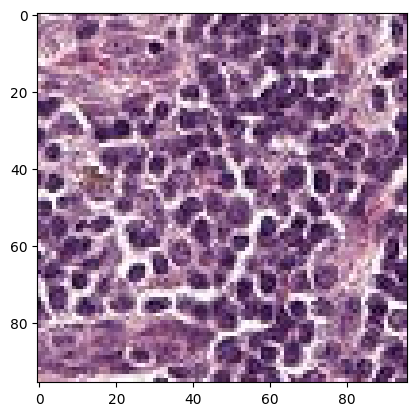

In [15]:
image1,_=train_DS.__getitem__(2000)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

label =  0


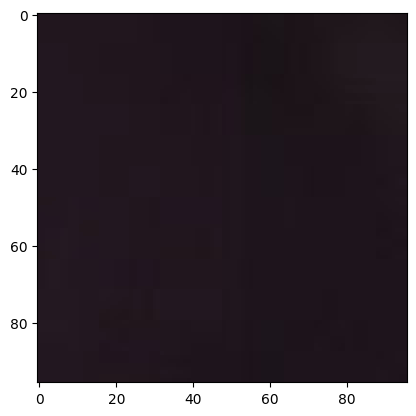

In [16]:
image1,y1=linear_DS.__getitem__(4)
print("label = ",y1)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

label =  0


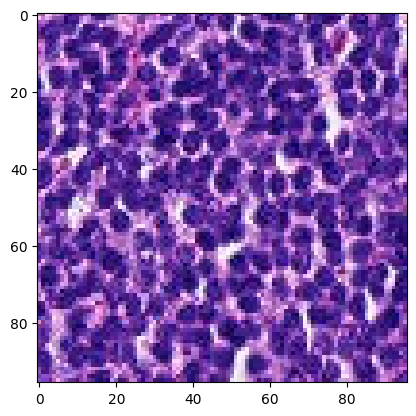

In [17]:
image1,y1=linear_DS.__getitem__(9)
print("label = ",y1)
plt.imshow(denorm(image1).permute(1,2,0).numpy())

## Metrics

In [18]:
def ece(y_real,y_result,bins=10):
    bin_boundaries = np.linspace(0, 1, bins + 1)
    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]
    y_res_copy=y_result.clone().detach().cpu().numpy()
    y_res_copy_labels=np.where(y_res_copy>=0.5,1,0)
    y_real_copy=y_real.clone().cpu().numpy()

    ece = 0
    for bin_lower, bin_upper in zip(bin_lowers, bin_uppers):
      if bin_upper==1:
        in_bin=(y_res_copy>=bin_lower)
      else:
        in_bin=(y_res_copy>=bin_lower) & (y_res_copy<bin_upper)

      y_res_bin=y_res_copy[in_bin]
      y_real_bin=y_real_copy[in_bin]
      y_res_labels_bin=y_res_copy_labels[in_bin]
      if len(y_res_bin)==0:continue
      acc=np.mean(y_real_bin)
      conf=y_res_bin.mean()
      ece += np.abs(acc - conf)* len(y_res_bin)
    return ece/len(y_real)

def reliability_plot(y_real,y_result,bins=10,save_img=False,title="Reliability-curve"):
    bin_boundaries = np.linspace(0, 1, bins + 1)
    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]
    y_res_copy=y_result.clone().detach().cpu().numpy()
    y_res_copy_labels=np.where(y_res_copy>=0.5,1,0)
    y_real_copy=y_real.clone().cpu().numpy()
    reliability_dict={}
    for bin_lower, bin_upper in zip(bin_lowers, bin_uppers):
      if bin_upper==1:
        in_bin=(y_res_copy>=bin_lower)
      else:
        in_bin=(y_res_copy>=bin_lower) & (y_res_copy<bin_upper)

      y_res_bin=y_res_copy[in_bin]
      y_real_bin=y_real_copy[in_bin]
      y_res_labels_bin=y_res_copy_labels[in_bin]
      if len(y_res_bin)==0:continue
      acc=np.mean(y_real_bin)
      conf=y_res_bin.mean()
      reliability_dict[conf]=acc
    reliability_array=np.array(list(reliability_dict.items()))
    plt.figure(figsize=(5,5))
    plt.plot(reliability_array[:,0],reliability_array[:,1],"o--")
    plt.plot([0,1],[0,1],"k--")
    plt.xlabel("Average Predicted Probability")
    plt.ylabel("Fraction of positives")
    plt.xlim(0,1)
    plt.ylim(0,1)
    plt.title(title)
    if save_img:
        addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/{title}.png"
        plt.savefig(addr)
    plt.show()
    plt.close()

In [19]:
def metrics_display(y_real,y_result):
    acc=TMF.accuracy(y_result, y_real, task='binary')
    f1=TMF.f1_score(y_result, y_real, task='binary')
    roc=TMF.auroc(y_result, y_real,task='binary')
    spec=TMF.specificity(y_result, y_real,task='binary')
    recall=TMF.recall(y_result, y_real,task='binary')
    ece_score=ece(y_real,y_result)
    print(f"Accuracy : {acc}")
    print(f"F1 Score : {f1}")
    print(f"AUC-ROC : {roc}")
    print(f"Specificity : {spec}")
    print(f"Recall : {recall}")
    print(f"ECE : {ece_score}")

def metrics_dict_creator(y_real,y_result):
    acc=TMF.accuracy(y_result, y_real, task='binary')
    f1=TMF.f1_score(y_result, y_real, task='binary')
    roc=TMF.auroc(y_result, y_real,task='binary')
    spec=TMF.specificity(y_result, y_real,task='binary')
    recall=TMF.recall(y_result, y_real,task='binary')
    ece_score=ece(y_real,y_result)
    return {
        "Accuracy" : acc,
        "F1 Score" : f1,
        "AUC-ROC" : roc,
        "Specificity" : spec,
        "Recall" : recall,
        "ECE" : ece_score
    }

## Loss Functions

In [20]:
def NTXent_Loss(z,tau):
    n2=z.shape[0]
    n=n2//2

    z=F.normalize(z,dim=-1)
    sim=z @ z.T /tau

    pos=torch.arange(n2,device=z.device)

    positive_pos=pos^1

    mask=torch.eye(n2, dtype=torch.bool,device=z.device)
    sim.masked_fill_(mask, float('-inf'))

    log_soft=F.log_softmax(sim,dim=-1)
    loss=-log_soft[pos,positive_pos].mean()

    return loss

## Model

In [21]:
class Encoder(nn.Module):
    def __init__(self,proj_dim=128):
        super().__init__()
        self.encoder=torchvision.models.resnet18(weights=None)
        self.encoder.conv1=nn.Conv2d(3,64,kernel_size=3,stride=1,padding=1,bias=False)
        self.encoder.maxpool=nn.Identity()
        self.encoder.fc=nn.Identity()

        self.projector=nn.Sequential(
            nn.Linear(512,512),
            nn.ReLU(),
            nn.Linear(512,proj_dim)
        )
    def forward(self,x):
        h=self.encoder(x)
        z=self.projector(h)
        return h,z

In [22]:
SSLEncoder=Encoder().to(device)
optim=torch.optim.AdamW(SSLEncoder.parameters(),lr=5e-5,weight_decay=1e-5)
fullpath=os.path.join("/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/","SSLEncoder.pth")
if os.path.exists(fullpath):
    SSLEncoder.load_state_dict(torch.load(fullpath,weights_only=True))
    print("Loaded last saved weights of encoder")
else:
    print("Loaded random weights of encoder: saved weights not found")

Loaded last saved weights of encoder


## Model training loop

In [ ]:
loss_dict={}

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | 

Epoch : 0 # 10
Loss: 4.11000394821167
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 3.8435165882110596
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 3.702148199081421
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 3.6743152141571045
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 50
Loss: 3.6134531497955322
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 60
Loss: 3.600541591644287
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 70
Loss: 3.422544002532959
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 80
Loss: 3.472245693206787
--------------------
| | | | | | | | | | 

Epoch : 0 # 90
Loss: 3.494

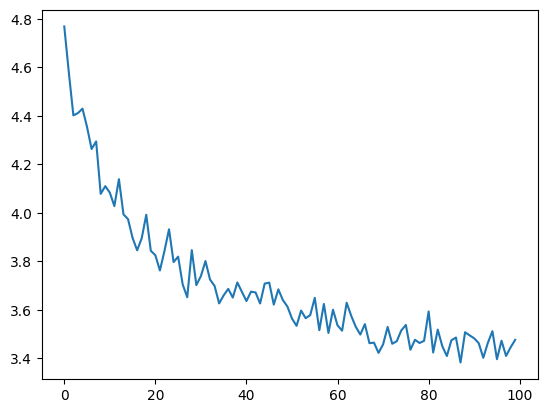

| | | | | | | | | | 

Epoch : 0 # 110
Loss: 3.3833041191101074
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 120
Loss: 3.3832554817199707
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 130
Loss: 3.2991082668304443
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 140
Loss: 3.3432021141052246
--------------------
| | | | | | | | | | 

Epoch : 0 # 150
Loss: 3.3477110862731934
--------------------
| | | | | | | | | | 

Epoch : 0 # 160
Loss: 3.304757595062256
--------------------
| | | | | | | | | | 

Epoch : 0 # 170
Loss: 3.2966647148132324
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 180
Loss: 3.2907276153564453
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 190
Loss: 3.3102729320526123
--------------------
| | | | | | | | | | 

Epoch : 0 # 2

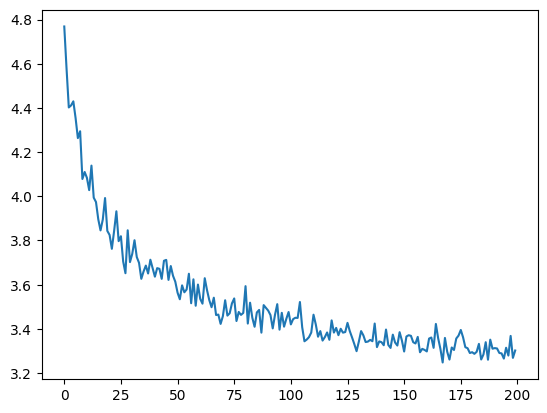

| | | | | | | | | | 

Epoch : 0 # 210
Loss: 3.2795231342315674
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 220
Loss: 3.3302457332611084
--------------------
| | | | | | | | | | 

Epoch : 0 # 230
Loss: 3.3182787895202637
--------------------
| | | | | | | | | | 

Epoch : 0 # 240
Loss: 3.260891914367676
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 250
Loss: 3.267915725708008
--------------------
| | | | | | | | | | 

Epoch : 0 # 260
Loss: 3.2584242820739746
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 270
Loss: 3.2422804832458496
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 280
Loss: 3.231503486633301
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 290
Loss: 3.2396090030670166
--------------------
| | | | | | | | | | 

Epoch : 0 # 300

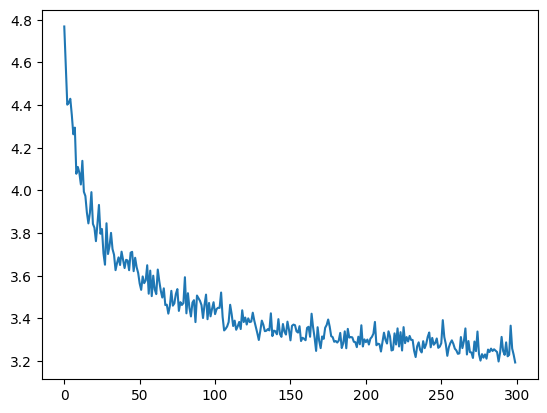

| | | | | | | | | | 

Epoch : 0 # 310
Loss: 3.225717067718506
--------------------
| | | | | | | | | | 

Epoch : 0 # 320
Loss: 3.2325196266174316
--------------------
| | | | | | | | | | 

Epoch : 0 # 330
Loss: 3.221038818359375
--------------------
| | | | | | | | | | 

Epoch : 0 # 340
Loss: 3.241018772125244
--------------------
| | | | | | | | | | 

Epoch : 0 # 350
Loss: 3.195955753326416
--------------------
| | | | | | | | | | 

Epoch : 0 # 360
Loss: 3.266462564468384
--------------------
| | | | | | | | | | 

Epoch : 0 # 370
Loss: 3.191906690597534
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 380
Loss: 3.2080142498016357
--------------------
| | | | | | | | | | 

Epoch : 0 # 390
Loss: 3.2000410556793213
--------------------
| | | | | | | | | | 

Epoch : 0 # 400
Loss: 3.223632335662842
--------------------


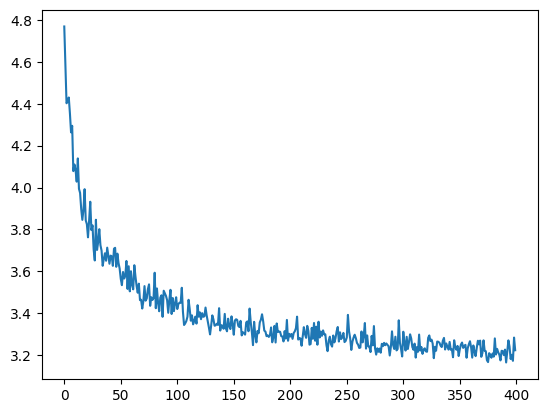

| | | | | | | | | | 

Epoch : 0 # 410
Loss: 3.1923367977142334
--------------------
| | | | | | | | | | 

Epoch : 0 # 420
Loss: 3.2141003608703613
--------------------
| | | | | | | | | | 

Epoch : 0 # 430
Loss: 3.1834375858306885
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 440
Loss: 3.2166690826416016
--------------------
| | | | | | | | | | 

Epoch : 0 # 450
Loss: 3.2221627235412598
--------------------
| | | | | | | | | | 

Epoch : 0 # 460
Loss: 3.2140321731567383
--------------------
| | | | | | | | | | 

Epoch : 0 # 470
Loss: 3.2144837379455566
--------------------
| | | | | | | | | | 

Epoch : 0 # 480
Loss: 3.2432851791381836
--------------------
| | | | | | | | | | 

Epoch : 0 # 490
Loss: 3.1680455207824707
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 500
Loss: 3.1735174655914307
--------------------


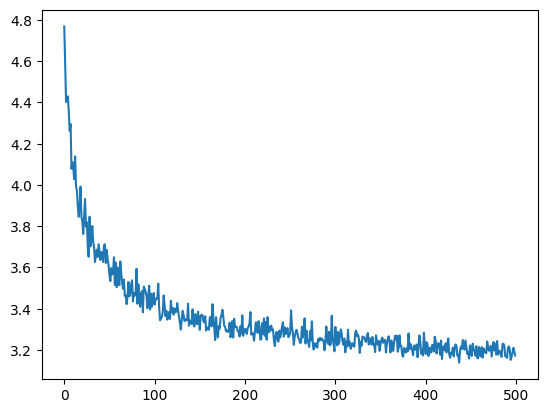

| | | | | | | | | | 

Epoch : 0 # 510
Loss: 3.183579444885254
--------------------
| | | | | | | | | | 

Epoch : 0 # 520
Loss: 3.159266233444214
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 530
Loss: 3.1723663806915283
--------------------
| | | | | | | | | | 

Epoch : 0 # 540
Loss: 3.245147943496704
--------------------
| | | | | | | | | | 

Epoch : 0 # 550
Loss: 3.1605076789855957
--------------------
| | | | | | | | | | 

Epoch : 0 # 560
Loss: 3.2044920921325684
--------------------
| | | | | | | | | | 

Epoch : 0 # 570
Loss: 3.2048439979553223
--------------------
| | | | | | | | | | 

Epoch : 0 # 580
Loss: 3.1507411003112793
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 590
Loss: 3.1944143772125244
--------------------
| | | | | | | | | | 

Epoch : 0 # 600
Loss: 3.126654863357544
--------------------
saved SSLEncoder.pth
--------------------


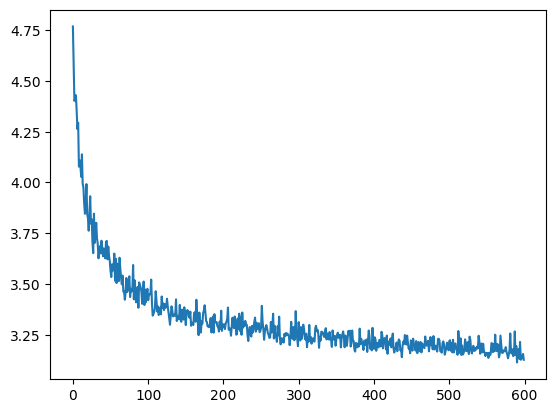

| | | | | | | | | | 

Epoch : 0 # 610
Loss: 3.1889841556549072
--------------------
| | | | | | | | | | 

Epoch : 0 # 620
Loss: 3.167478322982788
--------------------
| | | | | | | | | | 

Epoch : 0 # 630
Loss: 3.160672903060913
--------------------
| | | | | | | | | | 

Epoch : 0 # 640
Loss: 3.149843215942383
--------------------
| | | | | | | | | | 

Epoch : 0 # 650
Loss: 3.1944262981414795
--------------------
| | | | | | | | | | 

Epoch : 0 # 660
Loss: 3.157026529312134
--------------------
| | | | | | | | | | 

Epoch : 0 # 670
Loss: 3.1215062141418457
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 680
Loss: 3.1882753372192383
--------------------
| | | | | | | | | | 

Epoch : 0 # 690
Loss: 3.1175737380981445
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 700
Loss: 3.1620736122131348
--------------------


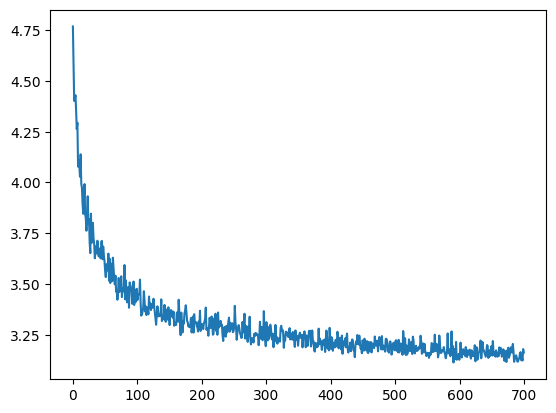

| | | | | | | | | | 

Epoch : 0 # 710
Loss: 3.147387981414795
--------------------
| | | | | | | | | | 

Epoch : 0 # 720
Loss: 3.1591711044311523
--------------------
| | | | | | | | | | 

Epoch : 0 # 730
Loss: 3.132990598678589
--------------------
| | | | | | | | | | 

Epoch : 0 # 740
Loss: 3.2006516456604004
--------------------
| | | | | | | | | | 

Epoch : 0 # 750
Loss: 3.136979103088379
--------------------
| | | | | | | | | | 

Epoch : 0 # 760
Loss: 3.106853485107422
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 770
Loss: 3.1354000568389893
--------------------
| | | | | | | | | | 

Epoch : 0 # 780
Loss: 3.166177272796631
--------------------
| | | | | | | | | | 

Epoch : 0 # 790
Loss: 3.119338035583496
--------------------
| | | | | | | | | | 

Epoch : 0 # 800
Loss: 3.1272380352020264
--------------------


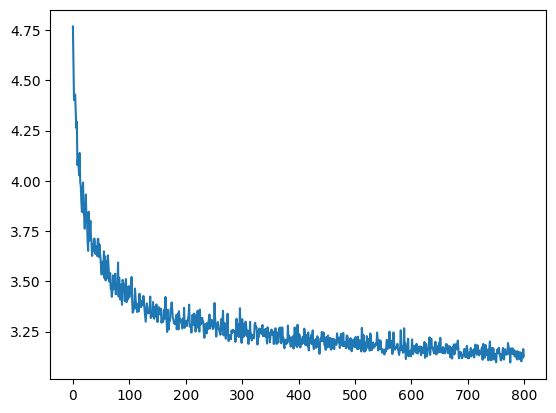

| | | | | | | | | | 

Epoch : 0 # 810
Loss: 3.1141648292541504
--------------------
| | | | | | | | | | 

Epoch : 0 # 820
Loss: 3.1585144996643066
--------------------
| | | | | | | | | | 

Epoch : 0 # 830
Loss: 3.1297526359558105
--------------------
| | | | | | | | | | 

Epoch : 0 # 840
Loss: 3.123983860015869
--------------------
| | | | | | | | | | 

Epoch : 0 # 850
Loss: 3.152249813079834
--------------------
| | | | | | | | | | 

Epoch : 0 # 860
Loss: 3.117640495300293
--------------------
| | | | | | | | | | 

Epoch : 0 # 870
Loss: 3.09613299369812
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 880
Loss: 3.1160495281219482
--------------------
| | | | | | | | | | 

Epoch : 0 # 890
Loss: 3.1158816814422607
--------------------
| | | | | | | | | | 

Epoch : 0 # 900
Loss: 3.1385445594787598
--------------------


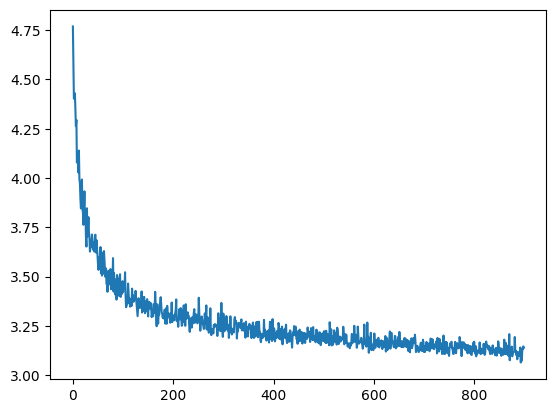

| | | | | | | | | | 

Epoch : 0 # 910
Loss: 3.107689142227173
--------------------
| | | | | | | | | | 

Epoch : 0 # 920
Loss: 3.0865116119384766
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 930
Loss: 3.1339879035949707
--------------------
| | | | | | | | | | 

Epoch : 0 # 940
Loss: 3.083517551422119
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 950
Loss: 3.0836198329925537
--------------------
| | | | | | | | | | 

Epoch : 0 # 960
Loss: 3.1180496215820312
--------------------
| | | | | | | | | | 

Epoch : 0 # 970
Loss: 3.135533332824707
--------------------
| | | | | | | | | | 

Epoch : 0 # 980
Loss: 3.0781912803649902
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 990
Loss: 3.09761381149292
--------------------
| | | | | | | | | | 

Epoch : 0 # 1000
Loss: 3.098371982574463
--------------------


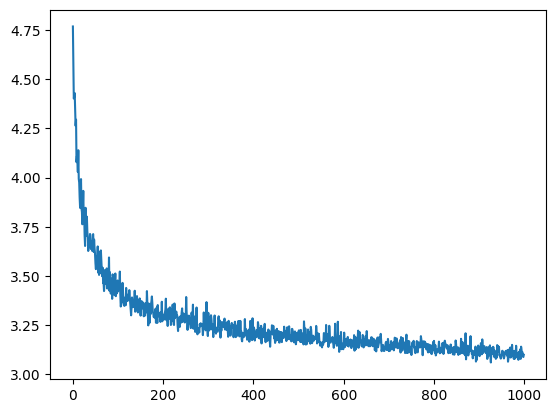

| | | | | | | | | | 

Epoch : 0 # 1010
Loss: 3.100848913192749
--------------------
| | | | | | | | | | 

Epoch : 0 # 1020
Loss: 3.1292502880096436
--------------------
| | | | | | | | | | 

Epoch : 0 # 1030
Loss: 3.1099131107330322
--------------------
| | | | | | | | | | 

Epoch : 0 # 1040
Loss: 3.089198589324951
--------------------
| | | | | | | | | | 

Epoch : 0 # 1050
Loss: 3.050123453140259
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1060
Loss: 3.0809431076049805
--------------------
| | | | | | | | | | 

Epoch : 0 # 1070
Loss: 3.068605899810791
--------------------
| | | | | | | | | | 

Epoch : 0 # 1080
Loss: 3.1166558265686035
--------------------
| | | | | | | | | | 

Epoch : 0 # 1090
Loss: 3.0767083168029785
--------------------
| | | | | | | | | | 

Epoch : 0 # 1100
Loss: 3.074209690093994
--------------------


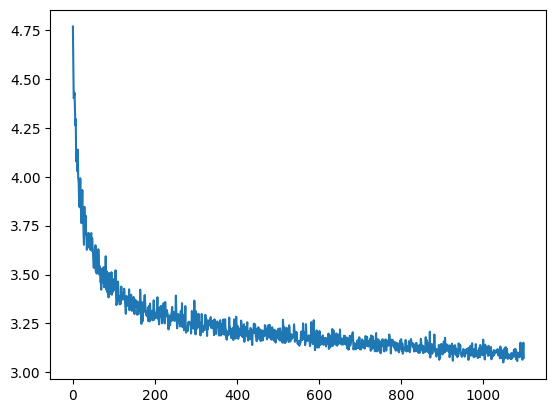

| | | | | | | | | | 

Epoch : 0 # 1110
Loss: 3.090580940246582
--------------------
| | | | | | | | | | 

Epoch : 0 # 1120
Loss: 3.10087513923645
--------------------
| | | | | | | | | | 

Epoch : 0 # 1130
Loss: 3.060915470123291
--------------------
| | | | | | | | | | 

Epoch : 0 # 1140
Loss: 3.0842764377593994
--------------------
| | | | | | | | | | 

Epoch : 0 # 1150
Loss: 3.1252801418304443
--------------------
| | | | | | | | | | 

Epoch : 0 # 1160
Loss: 3.110816478729248
--------------------
| | | | | | | | | | 

Epoch : 0 # 1170
Loss: 3.085298538208008
--------------------
| | | | | | | | | | 

Epoch : 0 # 1180
Loss: 3.097142457962036
--------------------
| | | | | | | | | | 

Epoch : 0 # 1190
Loss: 3.122884750366211
--------------------
| | | | | | | | | | 

Epoch : 0 # 1200
Loss: 3.0734128952026367
--------------------


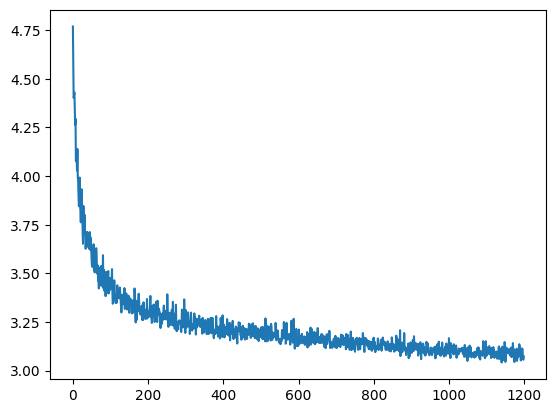

| | | | | | | | | | 

Epoch : 0 # 1210
Loss: 3.0765159130096436
--------------------
| | | | | | | | | | 

Epoch : 0 # 1220
Loss: 3.0691919326782227
--------------------
| | | | | | | | | | 

Epoch : 0 # 1230
Loss: 3.123901844024658
--------------------
| | | | | | | | | | 

Epoch : 0 # 1240
Loss: 3.0706517696380615
--------------------
| | | | | | | | | | 

Epoch : 0 # 1250
Loss: 3.0812318325042725
--------------------
| | | | | | | | | | 

Epoch : 0 # 1260
Loss: 3.0793466567993164
--------------------
| | | | | | | | | | 

Epoch : 0 # 1270
Loss: 3.0674285888671875
--------------------
| | | | | | | | | | 

Epoch : 0 # 1280
Loss: 3.053199052810669
--------------------
| | | | | | | | | | 

Epoch : 0 # 1290
Loss: 3.0621981620788574
--------------------
| | | | | | | | | | 

Epoch : 0 # 1300
Loss: 3.0862717628479004
--------------------


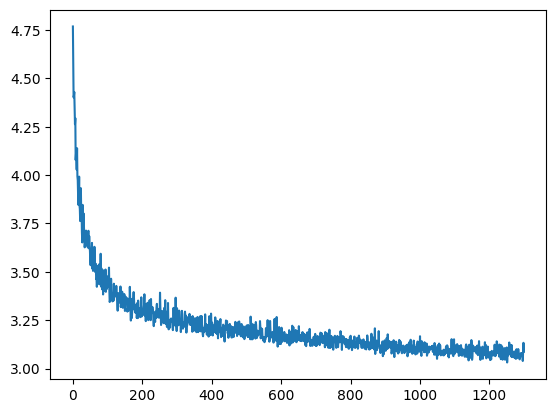

| | | | | | | | | | 

Epoch : 0 # 1310
Loss: 3.071039915084839
--------------------
| | | | | | | | | | 

Epoch : 0 # 1320
Loss: 3.0711019039154053
--------------------
| | | | | | | | | | 

Epoch : 0 # 1330
Loss: 3.0390586853027344
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1340
Loss: 3.0356273651123047
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1350
Loss: 3.055833578109741
--------------------
| | | | | | | | | | 

Epoch : 0 # 1360
Loss: 3.082521915435791
--------------------
| | | | | | | | | | 

Epoch : 0 # 1370
Loss: 3.051487445831299
--------------------
| | | | | | | | | | 

Epoch : 0 # 1380
Loss: 3.075073003768921
--------------------
| | | | | | | | | | 

Epoch : 0 # 1390
Loss: 3.0394742488861084
--------------------
| | | | | | | | | | 

Epoch : 0 # 1400
Loss: 3.0704264640808105
--------------------


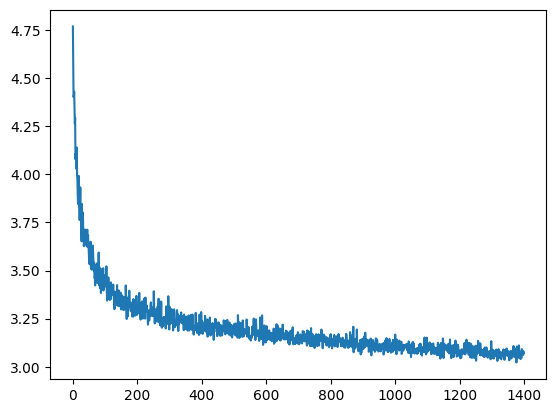

| | | | | | | | | | 

Epoch : 0 # 1410
Loss: 3.073896646499634
--------------------
| | | | | | | | | | 

Epoch : 0 # 1420
Loss: 3.058748722076416
--------------------
| | | | | | | | | | 

Epoch : 0 # 1430
Loss: 3.1055264472961426
--------------------
| | | | | | | | | | 

Epoch : 0 # 1440
Loss: 3.031214714050293
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1450
Loss: 3.0503082275390625
--------------------
| | | | | | | | | | 

Epoch : 0 # 1460
Loss: 3.0562119483947754
--------------------
| | | | | | | | | | 

Epoch : 0 # 1470
Loss: 3.102485179901123
--------------------
| | | | | | | | | | 

Epoch : 0 # 1480
Loss: 3.051933765411377
--------------------
| | | | | | | | | | 

Epoch : 0 # 1490
Loss: 3.05501127243042
--------------------
| | | | | | | | | | 

Epoch : 0 # 1500
Loss: 3.071826934814453
--------------------


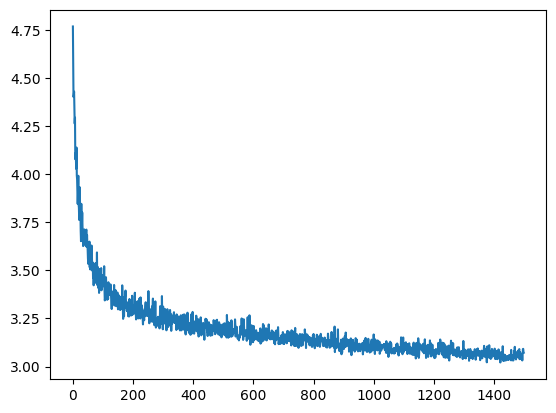

| | | | | | | | | | 

Epoch : 0 # 1510
Loss: 3.0458033084869385
--------------------
| | | | | | | | | | 

Epoch : 0 # 1520
Loss: 3.0364959239959717
--------------------
| | | | | | | | | | 

Epoch : 0 # 1530
Loss: 3.038412570953369
--------------------
| | | | | | | | | | 

Epoch : 0 # 1540
Loss: 3.031785488128662
--------------------
| | | | | | | | | | 

Epoch : 0 # 1550
Loss: 3.027000665664673
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1560
Loss: 3.052400827407837
--------------------
| | | | | | | | | | 

Epoch : 0 # 1570
Loss: 3.034059524536133
--------------------
| | | | | | | | | | 

Epoch : 0 # 1580
Loss: 3.0287322998046875
--------------------
| | | | | | | | | | 

Epoch : 0 # 1590
Loss: 3.069528102874756
--------------------
| | | | | | | | | | 

Epoch : 0 # 1600
Loss: 3.036550998687744
--------------------


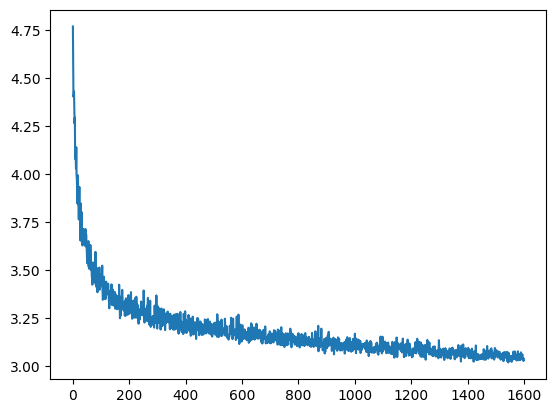

| | | | | | | | | | 

Epoch : 0 # 1610
Loss: 3.0493335723876953
--------------------
| | | | | | | | | | 

Epoch : 0 # 1620
Loss: 3.0203795433044434
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1630
Loss: 3.0274059772491455
--------------------
| | | | | | | | | | 

Epoch : 0 # 1640
Loss: 3.063173294067383
--------------------
| | | | | | | | | | 

Epoch : 0 # 1650
Loss: 3.0415287017822266
--------------------
| | | | | | | | | | 

Epoch : 0 # 1660
Loss: 3.0892672538757324
--------------------
| | | | | | | | | | 

Epoch : 0 # 1670
Loss: 3.0619826316833496
--------------------
| | | | | | | | | | 

Epoch : 0 # 1680
Loss: 3.031324625015259
--------------------
| | | | | | | | | | 

Epoch : 0 # 1690
Loss: 3.0835883617401123
--------------------
| | | | | | | | | | 

Epoch : 0 # 1700
Loss: 3.020357131958008
--------------------
saved SSLEncoder.pth
--------------------


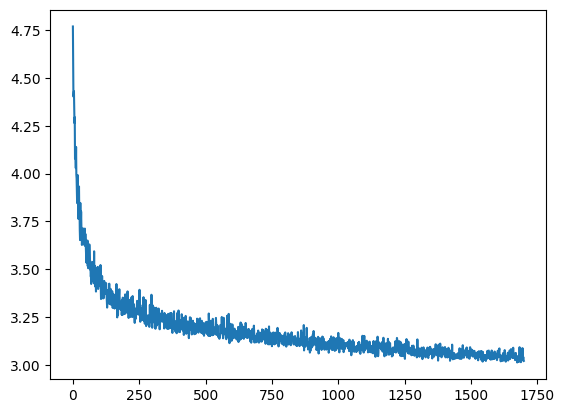

| | | | | | | | | | 

Epoch : 0 # 1710
Loss: 3.0315256118774414
--------------------
| | | | | | | | | | 

Epoch : 0 # 1720
Loss: 3.030467987060547
--------------------
| | | | | | | | | | 

Epoch : 0 # 1730
Loss: 3.0122873783111572
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1740
Loss: 3.0516064167022705
--------------------
| | | | | | | | | | 

Epoch : 0 # 1750
Loss: 3.050568103790283
--------------------
| | | | | | | | | | 

Epoch : 0 # 1760
Loss: 3.0520644187927246
--------------------
| | | | | | | | | | 

Epoch : 0 # 1770
Loss: 3.031662940979004
--------------------
| | | | | | | | | | 

Epoch : 0 # 1780
Loss: 3.030862331390381
--------------------
| | | | | | | | | | 

Epoch : 0 # 1790
Loss: 3.0262510776519775
--------------------
| | | | | | | | | | 

Epoch : 0 # 1800
Loss: 3.048797130584717
--------------------


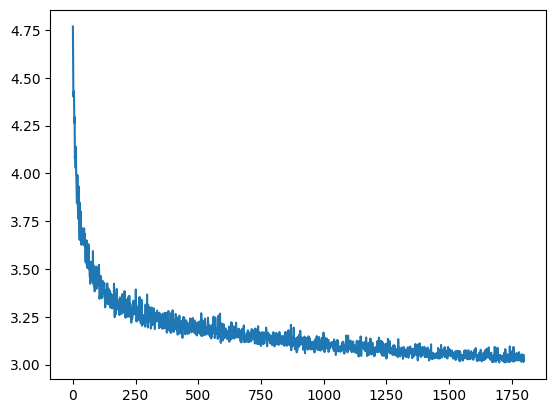

| | | | | | | | | | 

Epoch : 0 # 1810
Loss: 3.0273876190185547
--------------------
| | | | | | | | | | 

Epoch : 0 # 1820
Loss: 3.0725762844085693
--------------------
| | | | | | | | | | 

Epoch : 0 # 1830
Loss: 3.0284323692321777
--------------------
| | | | | | | | | | 

Epoch : 0 # 1840
Loss: 3.0588297843933105
--------------------
| | | | | | | | | | 

Epoch : 0 # 1850
Loss: 3.0358245372772217
--------------------
| | | | | | | | | | 

Epoch : 0 # 1860
Loss: 3.021881341934204
--------------------
| | | | | | | | | | 

Epoch : 0 # 1870
Loss: 3.046725034713745
--------------------
| | | | | | | | | | 

Epoch : 0 # 1880
Loss: 3.0277676582336426
--------------------
| | | | | | | | | | 

Epoch : 0 # 1890
Loss: 3.0498719215393066
--------------------
| | | | | | | | | | 

Epoch : 0 # 1900
Loss: 3.0560953617095947
--------------------


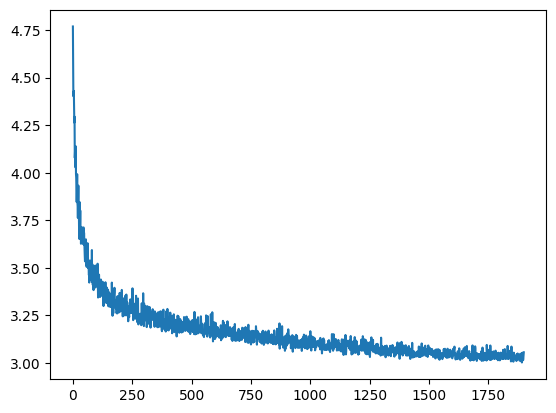

| | | | | | | | | | 

Epoch : 0 # 1910
Loss: 3.0245838165283203
--------------------
| | | | | | | | | | 

Epoch : 0 # 1920
Loss: 3.0230226516723633
--------------------
| | | | | | | | | | 

Epoch : 0 # 1930
Loss: 3.028817653656006
--------------------
| | | | | | | | | | 

Epoch : 0 # 1940
Loss: 3.0010287761688232
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 0 # 1950
Loss: 3.0218424797058105
--------------------
| | | | | | | | | | 

Epoch : 0 # 1960
Loss: 3.0033679008483887
--------------------
| | | | | | | | | | 

Epoch : 0 # 1970
Loss: 3.0184435844421387
--------------------
| | | | | | | | | | 

Epoch : 0 # 1980
Loss: 3.032743453979492
--------------------
| | | | | | | | | | 

Epoch : 0 # 1990
Loss: 3.0178656578063965
--------------------
| | | | | | | | | | 

Epoch : 0 # 2000
Loss: 3.0185515880584717
--------------------


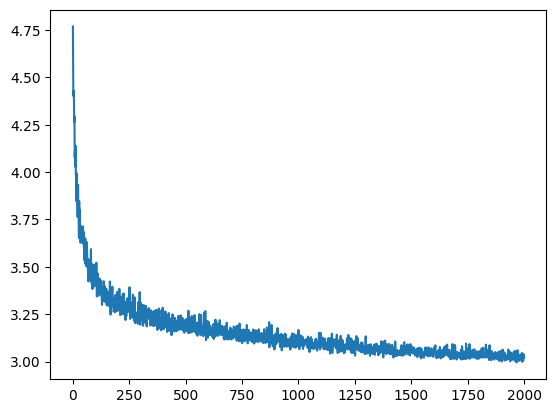

| | | | | | | | | | 

Epoch : 0 # 2010
Loss: 3.032564401626587
--------------------
| | | | | | | | | | 

Epoch : 0 # 2020
Loss: 3.0241191387176514
--------------------
| | | | | | | | | | 

Epoch : 0 # 2030
Loss: 3.018003463745117
--------------------
| | | | | | | | | | 

Epoch : 0 # 2040
Loss: 3.023317337036133
--------------------
| | | | | | | | | | 

Epoch : 0 # 2050
Loss: 3.044008731842041
--------------------
| | | | | | | | | | 

Epoch : 0 # 2060
Loss: 3.026188373565674
--------------------
| | | | | | | | | | 

Epoch : 0 # 2070
Loss: 3.004225730895996
--------------------
| | | | | | | | | | 

Epoch : 0 # 2080
Loss: 3.0298938751220703
--------------------
| | | | | | | | | | 

Epoch : 0 # 2090
Loss: 3.0243587493896484
--------------------
| | | | | | | | | | 

Epoch : 0 # 2100
Loss: 3.026884078979492
--------------------


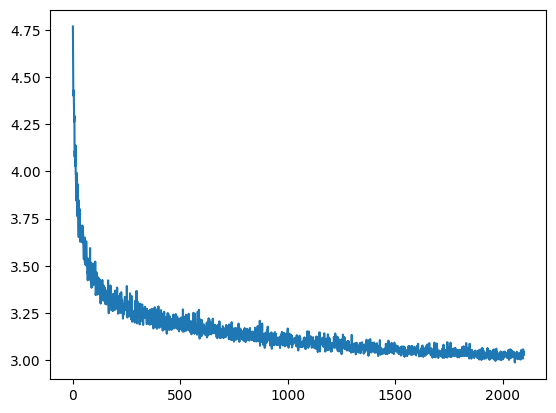

| | | | | | | | | | 

Epoch : 0 # 2110
Loss: 3.00846004486084
--------------------
| | | | | | | | | | 

Epoch : 0 # 2120
Loss: 3.0550098419189453
--------------------
| | | | | | | | | | 

Epoch : 0 # 2130
Loss: 3.040370225906372
--------------------
| | | | | | | | | | 

Epoch : 0 # 2140
Loss: 3.014019012451172
--------------------
| | | | | | | | | | | | | | | | | | 

Epoch : 1 # 10
Loss: 3.000563859939575
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 20
Loss: 3.012359857559204
--------------------
| | | | | | | | | | 

Epoch : 1 # 30
Loss: 3.0104525089263916
--------------------
| | | | | | | | | | 

Epoch : 1 # 40
Loss: 3.028158664703369
--------------------
| | | | | | | | | | 

Epoch : 1 # 50
Loss: 3.019467830657959
--------------------
| | | | | | | | | | 

Epoch : 1 # 60
Loss: 3.0063533782958984
--------------------
| | | | | | | | | | 

Epoch : 1 # 70
Loss: 3.0173757076263428
--------------------
| | | | | | | | | | 

Epoch :

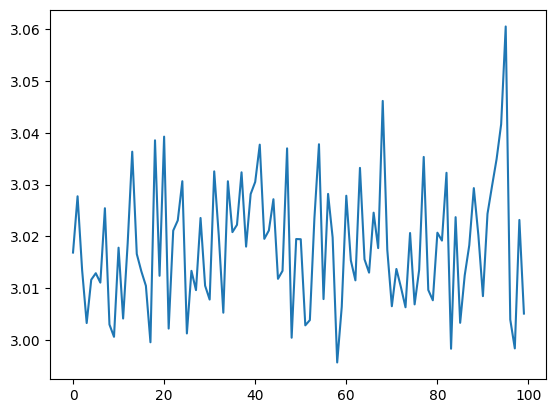

| | | | | | | | | | 

Epoch : 1 # 110
Loss: 3.0189175605773926
--------------------
| | | | | | | | | | 

Epoch : 1 # 120
Loss: 3.03879451751709
--------------------
| | | | | | | | | | 

Epoch : 1 # 130
Loss: 3.020083427429199
--------------------
| | | | | | | | | | 

Epoch : 1 # 140
Loss: 3.0058822631835938
--------------------
| | | | | | | | | | 

Epoch : 1 # 150
Loss: 2.9939136505126953
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 160
Loss: 3.0419769287109375
--------------------
| | | | | | | | | | 

Epoch : 1 # 170
Loss: 3.004228115081787
--------------------
| | | | | | | | | | 

Epoch : 1 # 180
Loss: 3.005466938018799
--------------------
| | | | | | | | | | 

Epoch : 1 # 190
Loss: 3.00722074508667
--------------------
| | | | | | | | | | 

Epoch : 1 # 200
Loss: 3.0030064582824707
--------------------


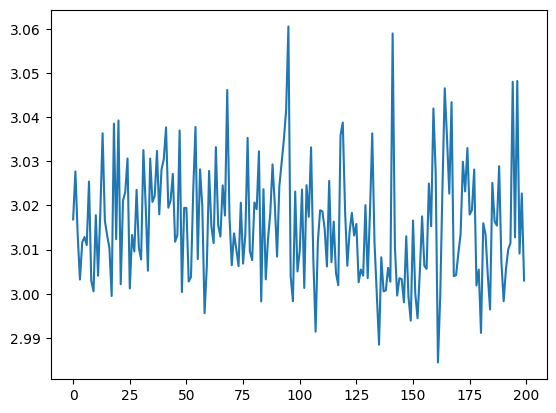

| | | | | | | | | | 

Epoch : 1 # 210
Loss: 3.015575408935547
--------------------
| | | | | | | | | | 

Epoch : 1 # 220
Loss: 2.997232437133789
--------------------
| | | | | | | | | | 

Epoch : 1 # 230
Loss: 3.0091798305511475
--------------------
| | | | | | | | | | 

Epoch : 1 # 240
Loss: 3.00142502784729
--------------------
| | | | | | | | | | 

Epoch : 1 # 250
Loss: 3.029494047164917
--------------------
| | | | | | | | | | 

Epoch : 1 # 260
Loss: 2.9987950325012207
--------------------
| | | | | | | | | | 

Epoch : 1 # 270
Loss: 3.0055036544799805
--------------------
| | | | | | | | | | 

Epoch : 1 # 280
Loss: 3.014636516571045
--------------------
| | | | | | | | | | 

Epoch : 1 # 290
Loss: 2.9871668815612793
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 300
Loss: 3.0054662227630615
--------------------


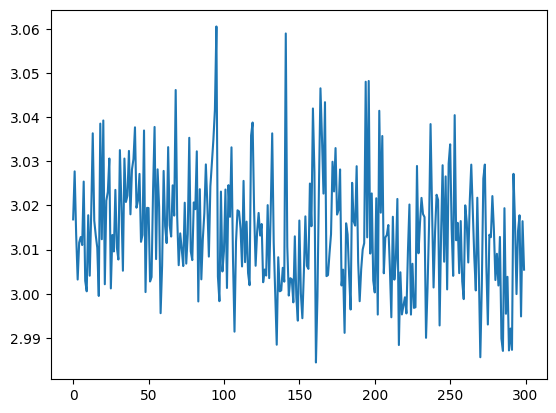

| | | | | | | | | | 

Epoch : 1 # 310
Loss: 3.0035440921783447
--------------------
| | | | | | | | | | 

Epoch : 1 # 320
Loss: 2.9887614250183105
--------------------
| | | | | | | | | | 

Epoch : 1 # 330
Loss: 3.0035860538482666
--------------------
| | | | | | | | | | 

Epoch : 1 # 340
Loss: 3.0023014545440674
--------------------
| | | | | | | | | | 

Epoch : 1 # 350
Loss: 2.999074697494507
--------------------
| | | | | | | | | | 

Epoch : 1 # 360
Loss: 3.004807949066162
--------------------
| | | | | | | | | | 

Epoch : 1 # 370
Loss: 2.99367094039917
--------------------
| | | | | | | | | | 

Epoch : 1 # 380
Loss: 2.9852499961853027
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 390
Loss: 3.0054564476013184
--------------------
| | | | | | | | | | 

Epoch : 1 # 400
Loss: 3.0071656703948975
--------------------


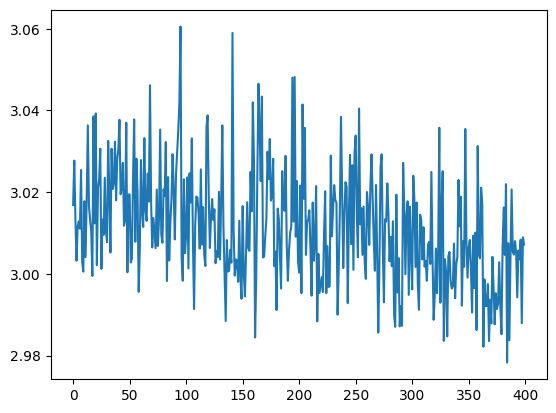

| | | | | | | | | | 

Epoch : 1 # 410
Loss: 2.9943716526031494
--------------------
| | | | | | | | | | 

Epoch : 1 # 420
Loss: 2.9840893745422363
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 430
Loss: 2.9885401725769043
--------------------
| | | | | | | | | | 

Epoch : 1 # 440
Loss: 3.0012872219085693
--------------------
| | | | | | | | | | 

Epoch : 1 # 450
Loss: 3.005873918533325
--------------------
| | | | | | | | | | 

Epoch : 1 # 460
Loss: 3.0039725303649902
--------------------
| | | | | | | | | | 

Epoch : 1 # 470
Loss: 3.006369113922119
--------------------
| | | | | | | | | | 

Epoch : 1 # 480
Loss: 3.004995346069336
--------------------
| | | | | | | | | | 

Epoch : 1 # 490
Loss: 2.9971871376037598
--------------------
| | | | | | | | | | 

Epoch : 1 # 500
Loss: 2.988436222076416
--------------------


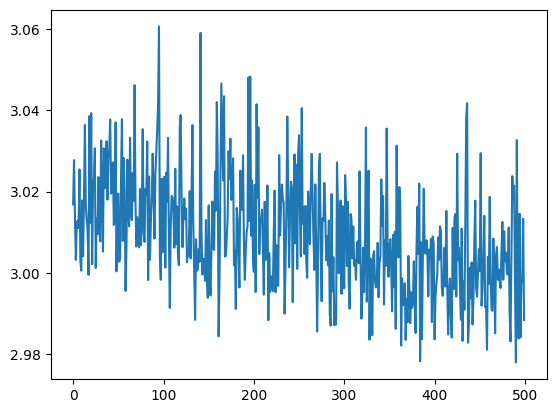

| | | | | | | | | | 

Epoch : 1 # 510
Loss: 3.0087339878082275
--------------------
| | | | | | | | | | 

Epoch : 1 # 520
Loss: 2.974998950958252
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 530
Loss: 2.980933904647827
--------------------
| | | | | | | | | | 

Epoch : 1 # 540
Loss: 2.9847817420959473
--------------------
| | | | | | | | | | 

Epoch : 1 # 550
Loss: 3.022505760192871
--------------------
| | | | | | | | | | 

Epoch : 1 # 560
Loss: 2.982487678527832
--------------------
| | | | | | | | | | 

Epoch : 1 # 570
Loss: 3.002955675125122
--------------------
| | | | | | | | | | 

Epoch : 1 # 580
Loss: 2.9895172119140625
--------------------
| | | | | | | | | | 

Epoch : 1 # 590
Loss: 3.009660482406616
--------------------
| | | | | | | | | | 

Epoch : 1 # 600
Loss: 2.9952077865600586
--------------------


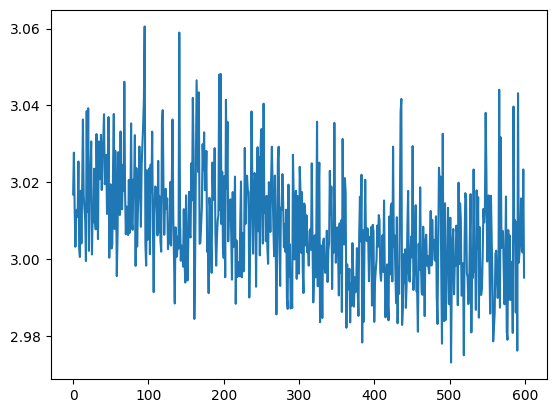

| | | | | | | | | | 

Epoch : 1 # 610
Loss: 3.0048601627349854
--------------------
| | | | | | | | | | 

Epoch : 1 # 620
Loss: 2.999129295349121
--------------------
| | | | | | | | | | 

Epoch : 1 # 630
Loss: 2.9867615699768066
--------------------
| | | | | | | | | | 

Epoch : 1 # 640
Loss: 2.9982447624206543
--------------------
| | | | | | | | | | 

Epoch : 1 # 650
Loss: 2.991084098815918
--------------------
| | | | | | | | | | 

Epoch : 1 # 660
Loss: 2.9976608753204346
--------------------
| | | | | | | | | | 

Epoch : 1 # 670
Loss: 3.0140414237976074
--------------------
| | | | | | | | | | 

Epoch : 1 # 680
Loss: 2.990321159362793
--------------------
| | | | | | | | | | 

Epoch : 1 # 690
Loss: 3.0047998428344727
--------------------
| | | | | | | | | | 

Epoch : 1 # 700
Loss: 3.0159921646118164
--------------------


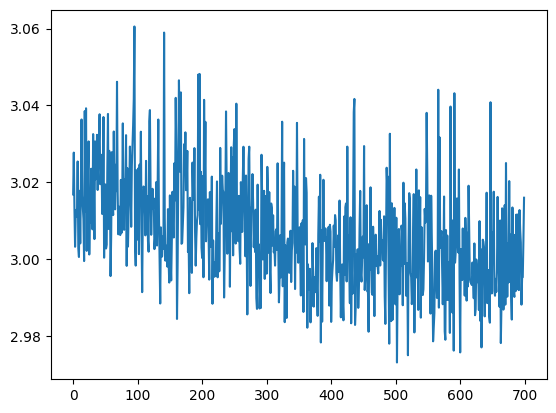

| | | | | | | | | | 

Epoch : 1 # 710
Loss: 3.0042600631713867
--------------------
| | | | | | | | | | 

Epoch : 1 # 720
Loss: 2.9856486320495605
--------------------
| | | | | | | | | | 

Epoch : 1 # 730
Loss: 3.000995397567749
--------------------
| | | | | | | | | | 

Epoch : 1 # 740
Loss: 3.012338638305664
--------------------
| | | | | | | | | | 

Epoch : 1 # 750
Loss: 3.007826328277588
--------------------
| | | | | | | | | | 

Epoch : 1 # 760
Loss: 3.000094413757324
--------------------
| | | | | | | | | | 

Epoch : 1 # 770
Loss: 2.9858176708221436
--------------------
| | | | | | | | | | 

Epoch : 1 # 780
Loss: 3.0393447875976562
--------------------
| | | | | | | | | | 

Epoch : 1 # 790
Loss: 2.9925920963287354
--------------------
| | | | | | | | | | 

Epoch : 1 # 800
Loss: 2.9972946643829346
--------------------


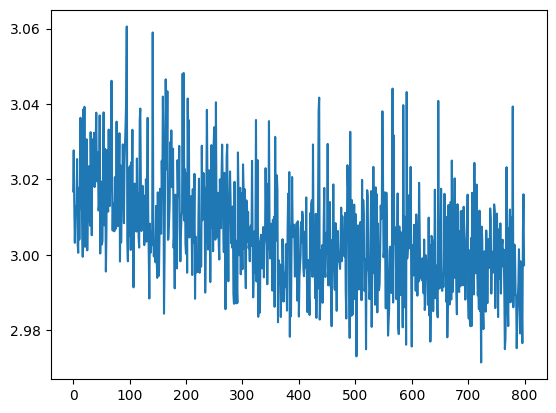

| | | | | | | | | | 

Epoch : 1 # 810
Loss: 2.9965872764587402
--------------------
| | | | | | | | | | 

Epoch : 1 # 820
Loss: 2.991823434829712
--------------------
| | | | | | | | | | 

Epoch : 1 # 830
Loss: 2.9842262268066406
--------------------
| | | | | | | | | | 

Epoch : 1 # 840
Loss: 2.98512864112854
--------------------
| | | | | | | | | | 

Epoch : 1 # 850
Loss: 2.9880964756011963
--------------------
| | | | | | | | | | 

Epoch : 1 # 860
Loss: 2.9798500537872314
--------------------
| | | | | | | | | | 

Epoch : 1 # 870
Loss: 2.990963935852051
--------------------
| | | | | | | | | | 

Epoch : 1 # 880
Loss: 3.0048341751098633
--------------------
| | | | | | | | | | 

Epoch : 1 # 890
Loss: 2.9981348514556885
--------------------
| | | | | | | | | | 

Epoch : 1 # 900
Loss: 3.015857219696045
--------------------


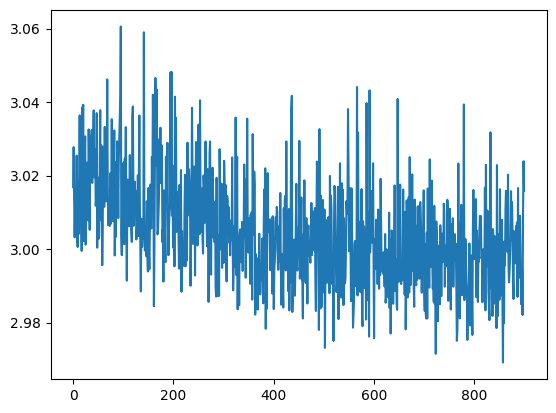

| | | | | | | | | | 

Epoch : 1 # 910
Loss: 2.9883241653442383
--------------------
| | | | | | | | | | 

Epoch : 1 # 920
Loss: 2.9916326999664307
--------------------
| | | | | | | | | | 

Epoch : 1 # 930
Loss: 2.983379602432251
--------------------
| | | | | | | | | | 

Epoch : 1 # 940
Loss: 2.99234676361084
--------------------
| | | | | | | | | | 

Epoch : 1 # 950
Loss: 2.9978086948394775
--------------------
| | | | | | | | | | 

Epoch : 1 # 960
Loss: 2.997307300567627
--------------------
| | | | | | | | | | 

Epoch : 1 # 970
Loss: 2.9805831909179688
--------------------
| | | | | | | | | | 

Epoch : 1 # 980
Loss: 2.999992609024048
--------------------
| | | | | | | | | | 

Epoch : 1 # 990
Loss: 2.9859275817871094
--------------------
| | | | | | | | | | 

Epoch : 1 # 1000
Loss: 2.9908032417297363
--------------------


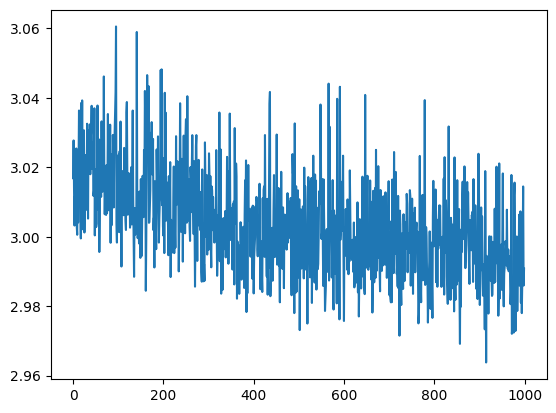

| | | | | | | | | | 

Epoch : 1 # 1010
Loss: 2.9970459938049316
--------------------
| | | | | | | | | | 

Epoch : 1 # 1020
Loss: 2.9792494773864746
--------------------
| | | | | | | | | | 

Epoch : 1 # 1030
Loss: 2.9898719787597656
--------------------
| | | | | | | | | | 

Epoch : 1 # 1040
Loss: 2.9915361404418945
--------------------
| | | | | | | | | | 

Epoch : 1 # 1050
Loss: 2.998856544494629
--------------------
| | | | | | | | | | 

Epoch : 1 # 1060
Loss: 2.985563278198242
--------------------
| | | | | | | | | | 

Epoch : 1 # 1070
Loss: 2.9837937355041504
--------------------
| | | | | | | | | | 

Epoch : 1 # 1080
Loss: 2.97157621383667
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 1090
Loss: 2.981093406677246
--------------------
| | | | | | | | | | 

Epoch : 1 # 1100
Loss: 2.983720302581787
--------------------


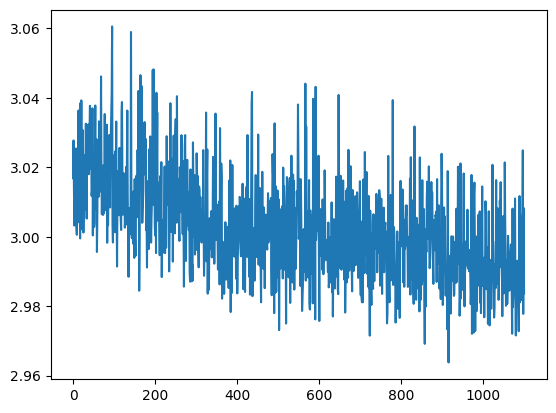

| | | | | | | | | | 

Epoch : 1 # 1110
Loss: 2.9956605434417725
--------------------
| | | | | | | | | | 

Epoch : 1 # 1120
Loss: 2.9965786933898926
--------------------
| | | | | | | | | | 

Epoch : 1 # 1130
Loss: 3.009106159210205
--------------------
| | | | | | | | | | 

Epoch : 1 # 1140
Loss: 2.994779109954834
--------------------
| | | | | | | | | | 

Epoch : 1 # 1150
Loss: 2.9961276054382324
--------------------
| | | | | | | | | | 

Epoch : 1 # 1160
Loss: 2.994626522064209
--------------------
| | | | | | | | | | 

Epoch : 1 # 1170
Loss: 2.9901316165924072
--------------------
| | | | | | | | | | 

Epoch : 1 # 1180
Loss: 2.9999966621398926
--------------------
| | | | | | | | | | 

Epoch : 1 # 1190
Loss: 2.988612174987793
--------------------
| | | | | | | | | | 

Epoch : 1 # 1200
Loss: 2.9734158515930176
--------------------


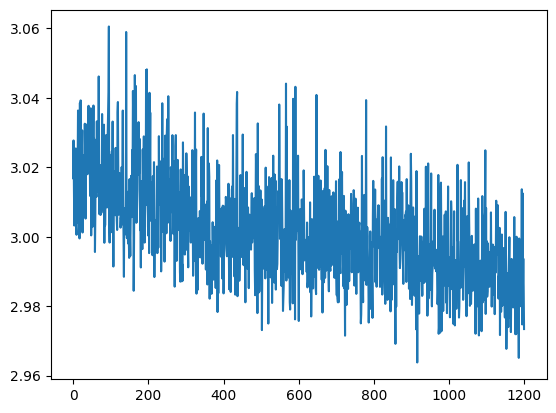

| | | | | | | | | | 

Epoch : 1 # 1210
Loss: 2.9916725158691406
--------------------
| | | | | | | | | | 

Epoch : 1 # 1220
Loss: 2.983981132507324
--------------------
| | | | | | | | | | 

Epoch : 1 # 1230
Loss: 2.997056245803833
--------------------
| | | | | | | | | | 

Epoch : 1 # 1240
Loss: 2.986420154571533
--------------------
| | | | | | | | | | 

Epoch : 1 # 1250
Loss: 2.986675262451172
--------------------
| | | | | | | | | | 

Epoch : 1 # 1260
Loss: 2.9808647632598877
--------------------
| | | | | | | | | | 

Epoch : 1 # 1270
Loss: 2.9993958473205566
--------------------
| | | | | | | | | | 

Epoch : 1 # 1280
Loss: 2.9728167057037354
--------------------
| | | | | | | | | | 

Epoch : 1 # 1290
Loss: 2.992607593536377
--------------------
| | | | | | | | | | 

Epoch : 1 # 1300
Loss: 2.9767990112304688
--------------------


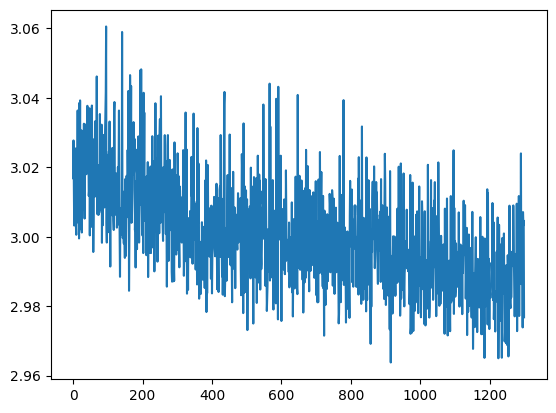

| | | | | | | | | | 

Epoch : 1 # 1310
Loss: 2.9847984313964844
--------------------
| | | | | | | | | | 

Epoch : 1 # 1320
Loss: 2.9786770343780518
--------------------
| | | | | | | | | | 

Epoch : 1 # 1330
Loss: 2.9882559776306152
--------------------
| | | | | | | | | | 

Epoch : 1 # 1340
Loss: 2.9900145530700684
--------------------
| | | | | | | | | | 

Epoch : 1 # 1350
Loss: 2.9880189895629883
--------------------
| | | | | | | | | | 

Epoch : 1 # 1360
Loss: 2.9861249923706055
--------------------
| | | | | | | | | | 

Epoch : 1 # 1370
Loss: 2.984452486038208
--------------------
| | | | | | | | | | 

Epoch : 1 # 1380
Loss: 3.0103049278259277
--------------------
| | | | | | | | | | 

Epoch : 1 # 1390
Loss: 2.986179828643799
--------------------
| | | | | | | | | | 

Epoch : 1 # 1400
Loss: 2.9839630126953125
--------------------


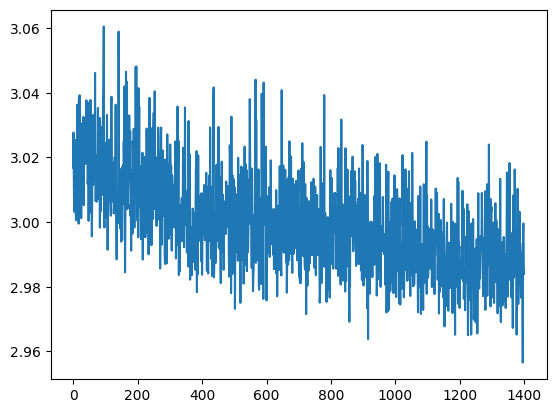

| | | | | | | | | | 

Epoch : 1 # 1410
Loss: 2.9771790504455566
--------------------
| | | | | | | | | | 

Epoch : 1 # 1420
Loss: 2.9650044441223145
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 1430
Loss: 2.9870786666870117
--------------------
| | | | | | | | | | 

Epoch : 1 # 1440
Loss: 2.978956937789917
--------------------
| | | | | | | | | | 

Epoch : 1 # 1450
Loss: 2.970606803894043
--------------------
| | | | | | | | | | 

Epoch : 1 # 1460
Loss: 2.9740219116210938
--------------------
| | | | | | | | | | 

Epoch : 1 # 1470
Loss: 2.973526954650879
--------------------
| | | | | | | | | | 

Epoch : 1 # 1480
Loss: 2.9731054306030273
--------------------
| | | | | | | | | | 

Epoch : 1 # 1490
Loss: 2.984952926635742
--------------------
| | | | | | | | | | 

Epoch : 1 # 1500
Loss: 2.9747722148895264
--------------------


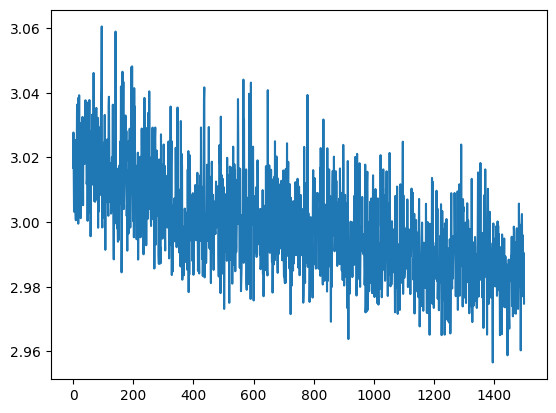

| | | | | | | | | | 

Epoch : 1 # 1510
Loss: 2.9918813705444336
--------------------
| | | | | | | | | | 

Epoch : 1 # 1520
Loss: 2.9796993732452393
--------------------
| | | | | | | | | | 

Epoch : 1 # 1530
Loss: 2.9779739379882812
--------------------
| | | | | | | | | | 

Epoch : 1 # 1540
Loss: 2.987438678741455
--------------------
| | | | | | | | | | 

Epoch : 1 # 1550
Loss: 3.0012476444244385
--------------------
| | | | | | | | | | 

Epoch : 1 # 1560
Loss: 2.987635612487793
--------------------
| | | | | | | | | | 

Epoch : 1 # 1570
Loss: 2.9700493812561035
--------------------
| | | | | | | | | | 

Epoch : 1 # 1580
Loss: 2.973264455795288
--------------------
| | | | | | | | | | 

Epoch : 1 # 1590
Loss: 2.978463649749756
--------------------
| | | | | | | | | | 

Epoch : 1 # 1600
Loss: 3.0083184242248535
--------------------


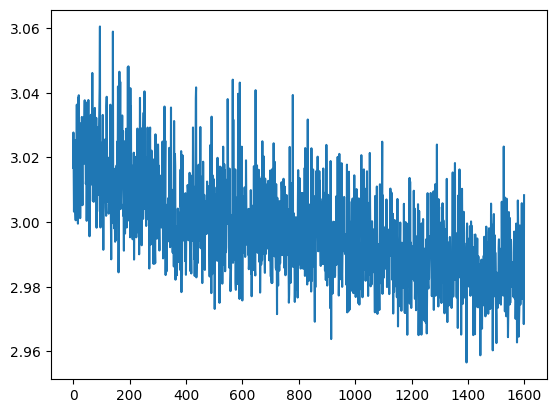

| | | | | | | | | | 

Epoch : 1 # 1610
Loss: 2.9752132892608643
--------------------
| | | | | | | | | | 

Epoch : 1 # 1620
Loss: 2.997786521911621
--------------------
| | | | | | | | | | 

Epoch : 1 # 1630
Loss: 2.9757497310638428
--------------------
| | | | | | | | | | 

Epoch : 1 # 1640
Loss: 2.9815874099731445
--------------------
| | | | | | | | | | 

Epoch : 1 # 1650
Loss: 2.9798812866210938
--------------------
| | | | | | | | | | 

Epoch : 1 # 1660
Loss: 2.9888463020324707
--------------------
| | | | | | | | | | 

Epoch : 1 # 1670
Loss: 2.97823429107666
--------------------
| | | | | | | | | | 

Epoch : 1 # 1680
Loss: 2.9753708839416504
--------------------
| | | | | | | | | | 

Epoch : 1 # 1690
Loss: 2.9846911430358887
--------------------
| | | | | | | | | | 

Epoch : 1 # 1700
Loss: 2.9770607948303223
--------------------


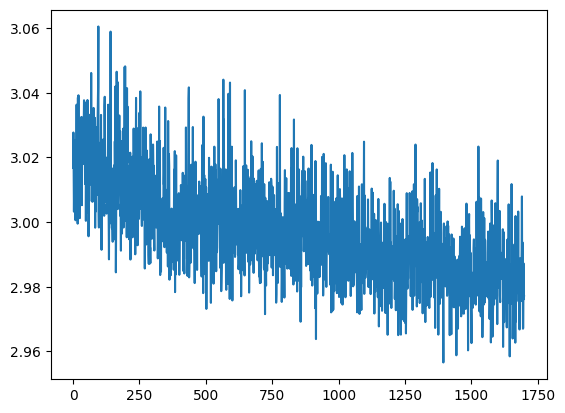

| | | | | | | | | | 

Epoch : 1 # 1710
Loss: 2.9864954948425293
--------------------
| | | | | | | | | | 

Epoch : 1 # 1720
Loss: 2.9830570220947266
--------------------
| | | | | | | | | | 

Epoch : 1 # 1730
Loss: 2.969482898712158
--------------------
| | | | | | | | | | 

Epoch : 1 # 1740
Loss: 2.9774885177612305
--------------------
| | | | | | | | | | 

Epoch : 1 # 1750
Loss: 2.9929115772247314
--------------------
| | | | | | | | | | 

Epoch : 1 # 1760
Loss: 2.9733152389526367
--------------------
| | | | | | | | | | 

Epoch : 1 # 1770
Loss: 2.9955265522003174
--------------------
| | | | | | | | | | 

Epoch : 1 # 1780
Loss: 2.98732852935791
--------------------
| | | | | | | | | | 

Epoch : 1 # 1790
Loss: 2.9845008850097656
--------------------
| | | | | | | | | | 

Epoch : 1 # 1800
Loss: 2.9734745025634766
--------------------


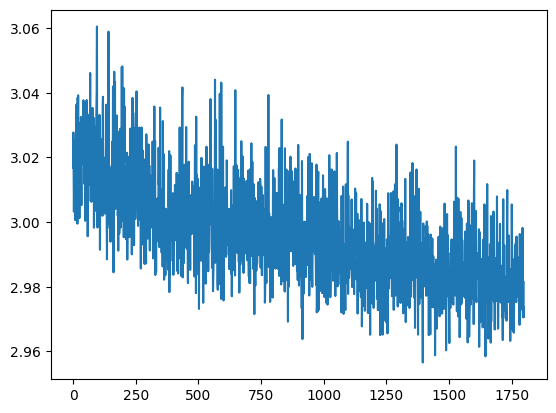

| | | | | | | | | | 

Epoch : 1 # 1810
Loss: 2.9917147159576416
--------------------
| | | | | | | | | | 

Epoch : 1 # 1820
Loss: 2.974602222442627
--------------------
| | | | | | | | | | 

Epoch : 1 # 1830
Loss: 2.964031457901001
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 1840
Loss: 2.988922595977783
--------------------
| | | | | | | | | | 

Epoch : 1 # 1850
Loss: 2.96944522857666
--------------------
| | | | | | | | | | 

Epoch : 1 # 1860
Loss: 2.9872241020202637
--------------------
| | | | | | | | | | 

Epoch : 1 # 1870
Loss: 2.980072021484375
--------------------
| | | | | | | | | | 

Epoch : 1 # 1880
Loss: 2.989123821258545
--------------------
| | | | | | | | | | 

Epoch : 1 # 1890
Loss: 2.9770476818084717
--------------------
| | | | | | | | | | 

Epoch : 1 # 1900
Loss: 2.981602430343628
--------------------


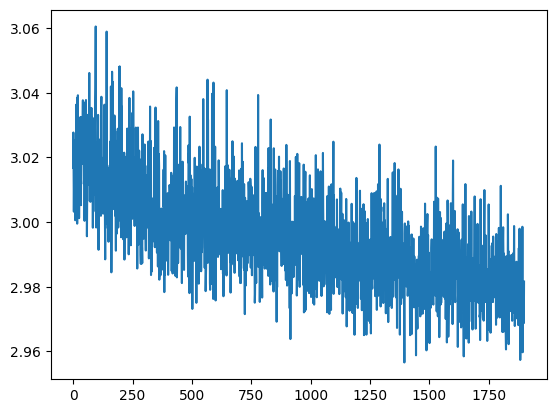

| | | | | | | | | | 

Epoch : 1 # 1910
Loss: 2.985719680786133
--------------------
| | | | | | | | | | 

Epoch : 1 # 1920
Loss: 2.971737861633301
--------------------
| | | | | | | | | | 

Epoch : 1 # 1930
Loss: 2.965909242630005
--------------------
| | | | | | | | | | 

Epoch : 1 # 1940
Loss: 2.949380397796631
--------------------
saved SSLEncoder.pth
--------------------
| | | | | | | | | | 

Epoch : 1 # 1950
Loss: 2.972325086593628
--------------------
| | | | | | | | | | 

Epoch : 1 # 1960
Loss: 2.985729694366455
--------------------
| | | | | | | | | | 

Epoch : 1 # 1970
Loss: 2.974956512451172
--------------------
| | | | | | | | | | 

Epoch : 1 # 1980
Loss: 2.973273515701294
--------------------
| | | | | | | | | | 

Epoch : 1 # 1990
Loss: 2.984788417816162
--------------------
| | | | | | | | | | 

Epoch : 1 # 2000
Loss: 2.9906301498413086
--------------------


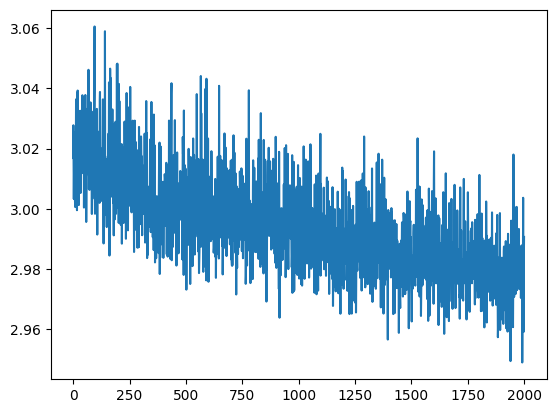

| | | | | | | | | | 

Epoch : 1 # 2010
Loss: 2.9835352897644043
--------------------
| | | | | | | | | | 

Epoch : 1 # 2020
Loss: 2.9727630615234375
--------------------
| | | | | | | | | | 

Epoch : 1 # 2030
Loss: 2.9723830223083496
--------------------
| | | | | | | | | | 

Epoch : 1 # 2040
Loss: 2.966590404510498
--------------------
| | | | | | | | | | 

Epoch : 1 # 2050
Loss: 2.975518226623535
--------------------
| | | | | | | | | | 

Epoch : 1 # 2060
Loss: 2.9706974029541016
--------------------
| | | | | | | | | | 

Epoch : 1 # 2070
Loss: 2.986757278442383
--------------------
| | | | | | | | | | 

Epoch : 1 # 2080
Loss: 2.9919047355651855
--------------------
| | | | | | | | | | 

Epoch : 1 # 2090
Loss: 2.9745945930480957
--------------------
| | | | | | | | | | 

Epoch : 1 # 2100
Loss: 2.969982624053955
--------------------


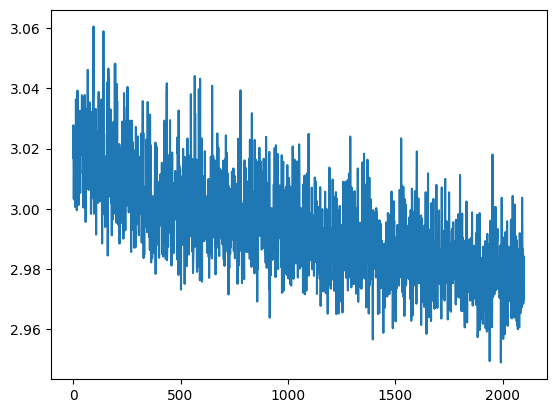

| | | | | | | | | | 

Epoch : 1 # 2110
Loss: 2.966442108154297
--------------------
| | | | | | | | | | 

Epoch : 1 # 2120
Loss: 2.967939853668213
--------------------
| | | | | | | | | | 

Epoch : 1 # 2130
Loss: 2.9815547466278076
--------------------
| | | | | | | | | | 

Epoch : 1 # 2140
Loss: 2.9838268756866455
--------------------
| | | | | | | | 

In [ ]:
epochs=2
min_loss=None
for epoch in range(epochs):
    c=0
    l=[]
    for v1,v2 in my_dataloader:
        v1,v2=v1.to(device),v2.to(device)
        optim.zero_grad()
        with torch.autocast(device_type='cuda', enabled=(device.type == "cuda")):
            h1,z1=SSLEncoder(v1)
            h2,z2=SSLEncoder(v2)

            z=torch.stack([z1,z2],dim=1).reshape(-1,z1.shape[-1])

            loss=NTXent_Loss(z,tau=0.5)

            loss.backward()

            optim.step()

        l.append(loss.item())

        c+=1
        print("|",end=" ")
        if c%10==0:
            print("\n")
            print(f"Epoch : {epoch} # {c}")
            print(f"Loss: {loss.item()}")
            print("-"*20)
            if(min_loss is None or loss.item()<min_loss):
                min_loss=loss.item()
                torch.save(SSLEncoder.state_dict(),"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth")
                print("saved SSLEncoder.pth")
                print("-"*20)
            if c%100==0:
                plt.plot(l)
                plt.show()
    loss_dict[epoch]=l

In [ ]:
# loss_dict

In [ ]:
SSLEncoder.load_state_dict(torch.load('/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth',weights_only=True))

<All keys matched successfully>

### t-sne Visualisation of some images

69999 images loaded successfully


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | | | | | | | | | | | 

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


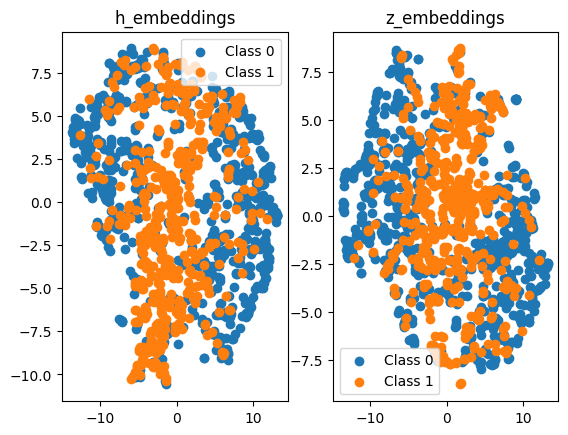

In [ ]:
tsne_h=TSNE(n_components=2,perplexity=30,n_iter=300)
tsne_z=TSNE(n_components=2,perplexity=30,n_iter=300)
linear_DS=DT(layer_list,True,labels,p=100)
DL=DataLoader(
    dataset=linear_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
    )
y_set=torch.tensor([]).to(device)
h_set=torch.tensor([]).to(device)
z_set=torch.tensor([]).to(device)

for k in range(20):
  x,y=next(iter(DL))
  x,y=x.to(device),y.to(device)
  with torch.no_grad():
      h,z=SSLEncoder(x)
  y_set=torch.cat([y_set,y])
  h_set=torch.cat([h_set,h])
  z_set=torch.cat([z_set,z])
  print("|",end=" ")

h_emb=tsne_h.fit_transform(h_set.cpu().numpy())
z_emb=tsne_z.fit_transform(z_set.cpu().numpy())
y_set=y_set.cpu().long().numpy()
plt.subplot(1, 2, 1)
plt.scatter(h_emb[y_set == 0, 0], h_emb[y_set == 0, 1], label='Class 0')
plt.scatter(h_emb[y_set == 1, 0], h_emb[y_set == 1, 1], label='Class 1')
plt.title("h_embeddings")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(z_emb[y_set == 0, 0], z_emb[y_set == 0, 1], label='Class 0')
plt.scatter(z_emb[y_set == 1, 0], z_emb[y_set == 1, 1], label='Class 1')
plt.title("z_embeddings")
plt.legend()

plt.savefig("/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/tsne.png")
plt.show()

## Linear Layer

In [23]:
class Linear_Layer(nn.Module):
    def __init__(self,input_dim=512):
        super().__init__()
        self.ll=nn.Sequential(
            nn.Linear(in_features=input_dim,out_features=64),
            nn.ReLU(),

            nn.Linear(in_features=64,out_features=1),
            # nn.Softmax(dim=1),
            # nn.Sigmoid()
        )
    def forward(self,h):
        return self.ll(h)

In [24]:
Final_Layer=Linear_Layer()
optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)

## Encoder weights freezing

In [ ]:
for param in SSLEncoder.parameters():
    param.requires_grad=False

## Linear layer training

In [ ]:
label_percent=[1,5,10,100]

699 images loaded successfully


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | 

Epoch : 0 # 10
Loss: 0.6461021900177002
--------------------
| --------------------
Epoch#0
Accuracy : 0.6194563508033752
F1 Score : 0.05673758685588837
AUC-ROC : 0.7946991324424744
Specificity : 0.9906759858131409
Recall : 0.029629629105329514
ECE : 0.0973660264148221
--------------------
| | | | | | | | | | 

Epoch : 1 # 10
Loss: 0.5922697186470032
--------------------
| --------------------
Epoch#1
Accuracy : 0.6294706463813782
F1 Score : 0.11604095250368118
AUC-ROC : 0.8195977210998535
Specificity : 0.9860140085220337
Recall : 0.06296296417713165
ECE : 0.14446687314643367
--------------------
| | | | | | | | | | 

Epoch : 2 # 10
Loss: 0.6138364672660828
--------------------
| --------------------
Epoch#2
Accuracy : 0.6494992971420288
F1 Score : 0.21221864223480225
AUC-ROC : 0.8339117765426636
Specificity : 0.9813519716262817
Recall : 0.12222222238779068
ECE : 0.17338317069884537
--------------------
| | | | | | | | | | 

Epoch : 3 # 10
Loss: 0.5996508598327637

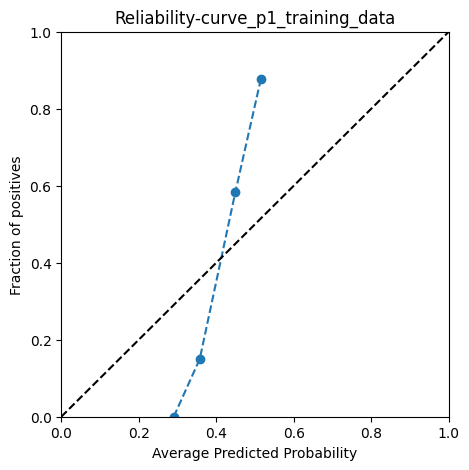

3495 images loaded successfully
| | | | | | | | | | 

Epoch : 0 # 10
Loss: 0.7115439176559448
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 0.6997994184494019
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 0.6856280565261841
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 0.6784219741821289
--------------------
| | | | | | | | | | 

Epoch : 0 # 50
Loss: 0.652402400970459
--------------------
| | | | | --------------------
Epoch#0
Accuracy : 0.5307582020759583
F1 Score : 0.3376413583755493
AUC-ROC : 0.5292394161224365
Specificity : 0.6982507109642029
Recall : 0.29088377952575684
ECE : 0.07668135343532531
--------------------
| | | | | | | | | | 

Epoch : 1 # 10
Loss: 0.6706225275993347
--------------------
| | | | | | | | | | 

Epoch : 1 # 20
Loss: 0.6394667625427246
--------------------
| | | | | | | | | | 

Epoch : 1 # 30
Loss: 0.62290358543396
--------------------
| | | | | | | | | | 

Epoch : 1 # 40
Loss: 0.6116625070571899
--------

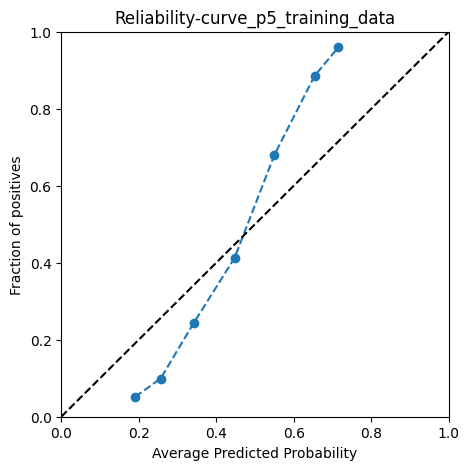

6990 images loaded successfully
| | | | | | | | | | 

Epoch : 0 # 10
Loss: 0.6961409449577332
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 0.6878998279571533
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 0.6789450645446777
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 0.657249927520752
--------------------
| | | | | | | | | | 

Epoch : 0 # 50
Loss: 0.6558891534805298
--------------------
| | | | | | | | | | 

Epoch : 0 # 60
Loss: 0.6114096641540527
--------------------
| | | | | | | | | | 

Epoch : 0 # 70
Loss: 0.6197712421417236
--------------------
| | | | | | | | | | 

Epoch : 0 # 80
Loss: 0.6129671335220337
--------------------
| | | | | | | | | | 

Epoch : 0 # 90
Loss: 0.6508485078811646
--------------------
| | | | | | | | | | 

Epoch : 0 # 100
Loss: 0.5700932741165161
--------------------


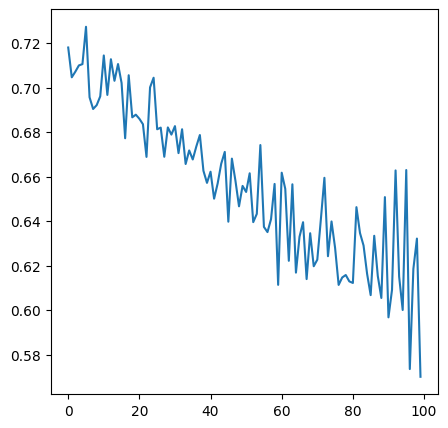

| | | | | | | | | | 

Epoch : 0 # 110
Loss: 0.6461118459701538
--------------------
--------------------
Epoch#0
Accuracy : 0.6670958399772644
F1 Score : 0.5738875865936279
AUC-ROC : 0.7007852792739868
Specificity : 0.7397849559783936
Recall : 0.5586452484130859
ECE : 0.11604948280024766
--------------------
| | | | | | | | | | 

Epoch : 1 # 10
Loss: 0.597547709941864
--------------------
| | | | | | | | | | 

Epoch : 1 # 20
Loss: 0.6098812222480774
--------------------
| | | | | | | | | | 

Epoch : 1 # 30
Loss: 0.5335506796836853
--------------------
| | | | | | | | | | 

Epoch : 1 # 40
Loss: 0.5544703006744385
--------------------
| | | | | | | | | | 

Epoch : 1 # 50
Loss: 0.5958963632583618
--------------------
| | | | | | | | | | 

Epoch : 1 # 60
Loss: 0.528590202331543
--------------------
| | | | | | | | | | 

Epoch : 1 # 70
Loss: 0.5701513290405273
--------------------
| | | | | | | | | | 

Epoch : 1 # 80
Loss: 0.5623336434364319
--------------------
| | | | | | | | | | 

Epoch 

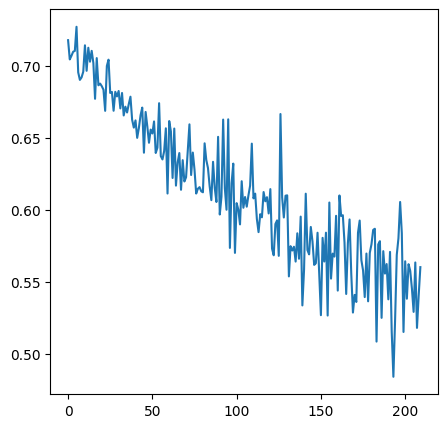

| | | | | | | | | | 

Epoch : 1 # 110
Loss: 0.7354881167411804
--------------------
--------------------
Epoch#1
Accuracy : 0.7773962616920471
F1 Score : 0.6811475157737732
AUC-ROC : 0.8249127268791199
Specificity : 0.9013141989707947
Recall : 0.592513382434845
ECE : 0.15948144295525996
--------------------
| | | | | | | | | | 

Epoch : 2 # 10
Loss: 0.49405092000961304
--------------------
| | | | | | | | | | 

Epoch : 2 # 20
Loss: 0.5471627712249756
--------------------
| | | | | | | | | | 

Epoch : 2 # 30
Loss: 0.5184122323989868
--------------------
| | | | | | | | | | 

Epoch : 2 # 40
Loss: 0.5689959526062012
--------------------
| | | | | | | | | | 

Epoch : 2 # 50
Loss: 0.5157774686813354
--------------------
| | | | | | | | | | 

Epoch : 2 # 60
Loss: 0.4908792972564697
--------------------
| | | | | | | | | | 

Epoch : 2 # 70
Loss: 0.572334885597229
--------------------
| | | | | | | | | | 

Epoch : 2 # 80
Loss: 0.568504273891449
--------------------
| | | | | | | | | | 

Epoch 

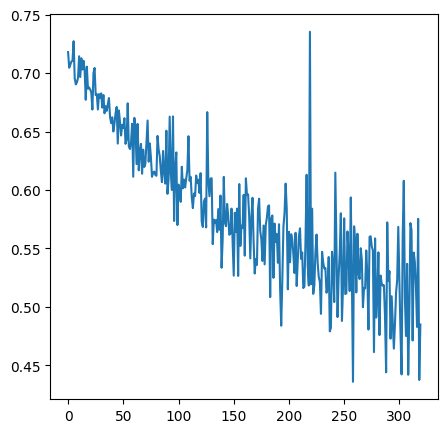

| | | | | | | | | | 

Epoch : 2 # 110
Loss: 0.4834257960319519
--------------------
--------------------
Epoch#2
Accuracy : 0.7884120345115662
F1 Score : 0.7146440148353577
AUC-ROC : 0.8418338298797607
Specificity : 0.8743129968643188
Recall : 0.6602495312690735
ECE : 0.12053704640810753
--------------------
| | | | | | | | | | 

Epoch : 3 # 10
Loss: 0.4981955885887146
--------------------
| | | | | | | | | | 

Epoch : 3 # 20
Loss: 0.4070414900779724
--------------------
| | | | | | | | | | 

Epoch : 3 # 30
Loss: 0.5493717193603516
--------------------
| | | | | | | | | | 

Epoch : 3 # 40
Loss: 0.4415760338306427
--------------------
| | | | | | | | | | 

Epoch : 3 # 50
Loss: 0.5176303386688232
--------------------
| | | | | | | | | | 

Epoch : 3 # 60
Loss: 0.4602962136268616
--------------------
| | | | | | | | | | 

Epoch : 3 # 70
Loss: 0.4928690493106842
--------------------
| | | | | | | | | | 

Epoch : 3 # 80
Loss: 0.5068385004997253
--------------------
| | | | | | | | | | 

Epoc

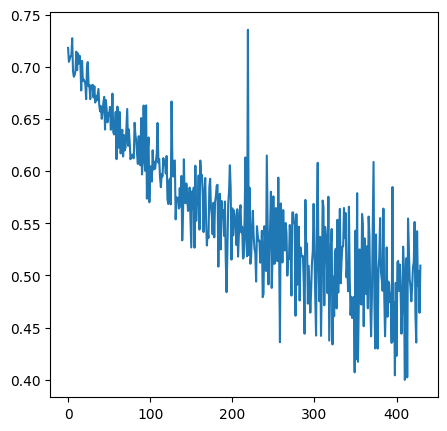

| | | | | | | | | | 

Epoch : 3 # 110
Loss: 0.41472330689430237
--------------------
--------------------
Epoch#3
Accuracy : 0.7914162874221802
F1 Score : 0.7229190468788147
AUC-ROC : 0.8465664386749268
Specificity : 0.8673835396766663
Recall : 0.678074836730957
ECE : 0.08508853557198515
--------------------
| | | | | | | | | | 

Epoch : 4 # 10
Loss: 0.49640321731567383
--------------------
| | | | | | | | | | 

Epoch : 4 # 20
Loss: 0.5129097104072571
--------------------
| | | | | | | | | | 

Epoch : 4 # 30
Loss: 0.48854178190231323
--------------------
| | | | | | | | | | 

Epoch : 4 # 40
Loss: 0.42497992515563965
--------------------
| | | | | | | | | | 

Epoch : 4 # 50
Loss: 0.49085766077041626
--------------------
| | | | | | | | | | 

Epoch : 4 # 60
Loss: 0.45967915654182434
--------------------
| | | | | | | | | | 

Epoch : 4 # 70
Loss: 0.4286523461341858
--------------------
| | | | | | | | | | 

Epoch : 4 # 80
Loss: 0.47135472297668457
--------------------
| | | | | | | | | | 

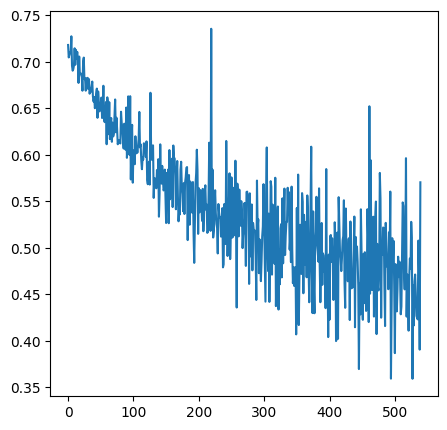

| | | | | | | | | | 

Epoch : 4 # 110
Loss: 0.590790867805481
--------------------
--------------------
Epoch#4
Accuracy : 0.79298996925354
F1 Score : 0.7274439334869385
AUC-ROC : 0.8493551015853882
Specificity : 0.8630824089050293
Recall : 0.6884135603904724
ECE : 0.059211975913787955
--------------------


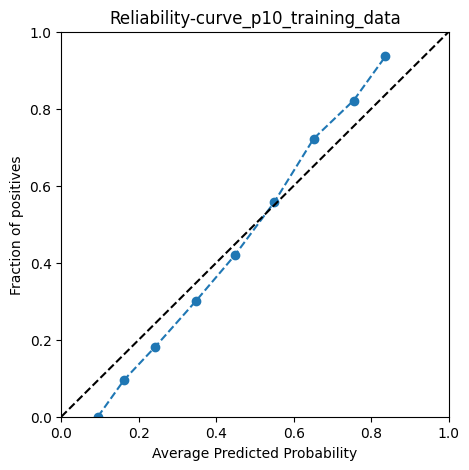

69999 images loaded successfully
| | | | | | | | | | 

Epoch : 0 # 10
Loss: 0.6659859418869019
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 0.6671906113624573
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 0.6606971025466919
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 0.622040867805481
--------------------
| | | | | | | | | | 

Epoch : 0 # 50
Loss: 0.6561868190765381
--------------------
| | | | | | | | | | 

Epoch : 0 # 60
Loss: 0.6258918046951294
--------------------
| | | | | | | | | | 

Epoch : 0 # 70
Loss: 0.6497397422790527
--------------------
| | | | | | | | | | 

Epoch : 0 # 80
Loss: 0.6100587844848633
--------------------
| | | | | | | | | | 

Epoch : 0 # 90
Loss: 0.6060507297515869
--------------------
| | | | | | | | | | 

Epoch : 0 # 100
Loss: 0.6009325385093689
--------------------


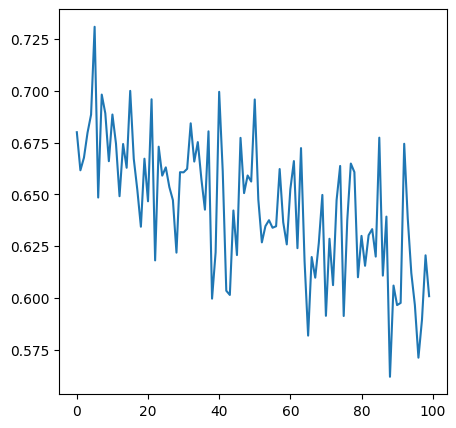

| | | | | | | | | | 

Epoch : 0 # 110
Loss: 0.5811953544616699
--------------------
| | | | | | | | | | 

Epoch : 0 # 120
Loss: 0.5847358107566833
--------------------
| | | | | | | | | | 

Epoch : 0 # 130
Loss: 0.5941070318222046
--------------------
| | | | | | | | | | 

Epoch : 0 # 140
Loss: 0.5698627233505249
--------------------
| | | | | | | | | | 

Epoch : 0 # 150
Loss: 0.5686118006706238
--------------------
| | | | | | | | | | 

Epoch : 0 # 160
Loss: 0.5689346790313721
--------------------
| | | | | | | | | | 

Epoch : 0 # 170
Loss: 0.575491189956665
--------------------
| | | | | | | | | | 

Epoch : 0 # 180
Loss: 0.5540812015533447
--------------------
| | | | | | | | | | 

Epoch : 0 # 190
Loss: 0.5416486263275146
--------------------
| | | | | | | | | | 

Epoch : 0 # 200
Loss: 0.5324618816375732
--------------------


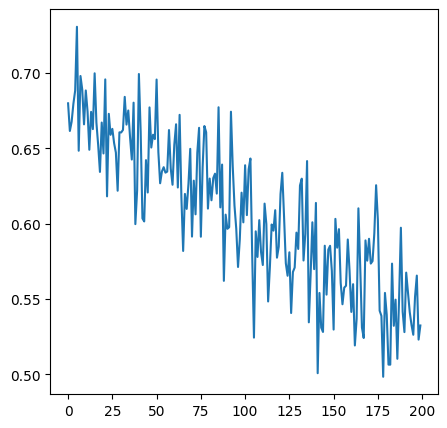

| | | | | | | | | | 

Epoch : 0 # 210
Loss: 0.5771806240081787
--------------------
| | | | | | | | | | 

Epoch : 0 # 220
Loss: 0.5095530152320862
--------------------
| | | | | | | | | | 

Epoch : 0 # 230
Loss: 0.5345318913459778
--------------------
| | | | | | | | | | 

Epoch : 0 # 240
Loss: 0.5575683116912842
--------------------
| | | | | | | | | | 

Epoch : 0 # 250
Loss: 0.544285774230957
--------------------
| | | | | | | | | | 

Epoch : 0 # 260
Loss: 0.5004044771194458
--------------------
| | | | | | | | | | 

Epoch : 0 # 270
Loss: 0.529739260673523
--------------------
| | | | | | | | | | 

Epoch : 0 # 280
Loss: 0.472697913646698
--------------------
| | | | | | | | | | 

Epoch : 0 # 290
Loss: 0.5257521271705627
--------------------
| | | | | | | | | | 

Epoch : 0 # 300
Loss: 0.46549439430236816
--------------------


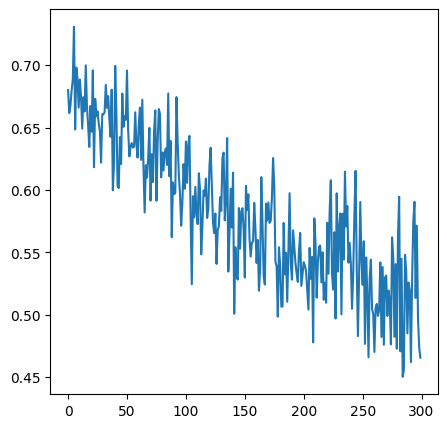

| | | | | | | | | | 

Epoch : 0 # 310
Loss: 0.49533092975616455
--------------------
| | | | | | | | | | 

Epoch : 0 # 320
Loss: 0.44242846965789795
--------------------
| | | | | | | | | | 

Epoch : 0 # 330
Loss: 0.4686028063297272
--------------------
| | | | | | | | | | 

Epoch : 0 # 340
Loss: 0.5466378927230835
--------------------
| | | | | | | | | | 

Epoch : 0 # 350
Loss: 0.5421528220176697
--------------------
| | | | | | | | | | 

Epoch : 0 # 360
Loss: 0.5064454078674316
--------------------
| | | | | | | | | | 

Epoch : 0 # 370
Loss: 0.46896490454673767
--------------------
| | | | | | | | | | 

Epoch : 0 # 380
Loss: 0.4683353304862976
--------------------
| | | | | | | | | | 

Epoch : 0 # 390
Loss: 0.4307214915752411
--------------------
| | | | | | | | | | 

Epoch : 0 # 400
Loss: 0.4386254549026489
--------------------


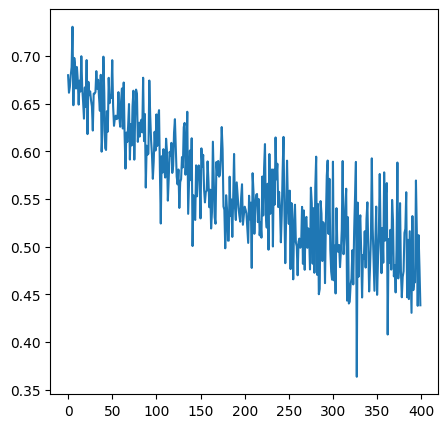

| | | | | | | | | | 

Epoch : 0 # 410
Loss: 0.478677898645401
--------------------
| | | | | | | | | | 

Epoch : 0 # 420
Loss: 0.5382677316665649
--------------------
| | | | | | | | | | 

Epoch : 0 # 430
Loss: 0.4952542781829834
--------------------
| | | | | | | | | | 

Epoch : 0 # 440
Loss: 0.4545820653438568
--------------------
| | | | | | | | | | 

Epoch : 0 # 450
Loss: 0.4542720317840576
--------------------
| | | | | | | | | | 

Epoch : 0 # 460
Loss: 0.41349679231643677
--------------------
| | | | | | | | | | 

Epoch : 0 # 470
Loss: 0.4742412567138672
--------------------
| | | | | | | | | | 

Epoch : 0 # 480
Loss: 0.5216954946517944
--------------------
| | | | | | | | | | 

Epoch : 0 # 490
Loss: 0.42832571268081665
--------------------
| | | | | | | | | | 

Epoch : 0 # 500
Loss: 0.4454514980316162
--------------------


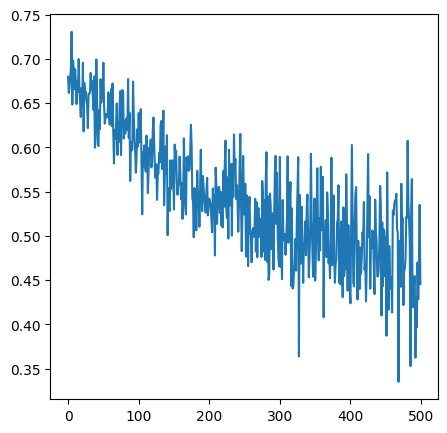

| | | | | | | | | | 

Epoch : 0 # 510
Loss: 0.39605024456977844
--------------------
| | | | | | | | | | 

Epoch : 0 # 520
Loss: 0.5035834312438965
--------------------
| | | | | | | | | | 

Epoch : 0 # 530
Loss: 0.47509297728538513
--------------------
| | | | | | | | | | 

Epoch : 0 # 540
Loss: 0.4730978012084961
--------------------
| | | | | | | | | | 

Epoch : 0 # 550
Loss: 0.3775045573711395
--------------------
| | | | | | | | | | 

Epoch : 0 # 560
Loss: 0.4758824110031128
--------------------
| | | | | | | | | | 

Epoch : 0 # 570
Loss: 0.402249276638031
--------------------
| | | | | | | | | | 

Epoch : 0 # 580
Loss: 0.5478332042694092
--------------------
| | | | | | | | | | 

Epoch : 0 # 590
Loss: 0.4424489736557007
--------------------
| | | | | | | | | | 

Epoch : 0 # 600
Loss: 0.42043060064315796
--------------------


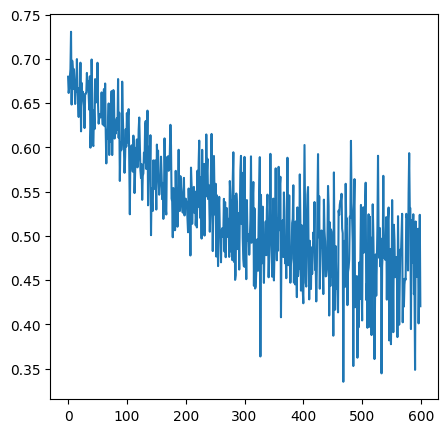

| | | | | | | | | | 

Epoch : 0 # 610
Loss: 0.45250964164733887
--------------------
| | | | | | | | | | 

Epoch : 0 # 620
Loss: 0.47392481565475464
--------------------
| | | | | | | | | | 

Epoch : 0 # 630
Loss: 0.4885343909263611
--------------------
| | | | | | | | | | 

Epoch : 0 # 640
Loss: 0.5236371755599976
--------------------
| | | | | | | | | | 

Epoch : 0 # 650
Loss: 0.402945339679718
--------------------
| | | | | | | | | | 

Epoch : 0 # 660
Loss: 0.4283560514450073
--------------------
| | | | | | | | | | 

Epoch : 0 # 670
Loss: 0.4875449538230896
--------------------
| | | | | | | | | | 

Epoch : 0 # 680
Loss: 0.42092591524124146
--------------------
| | | | | | | | | | 

Epoch : 0 # 690
Loss: 0.4316771328449249
--------------------
| | | | | | | | | | 

Epoch : 0 # 700
Loss: 0.3236294388771057
--------------------


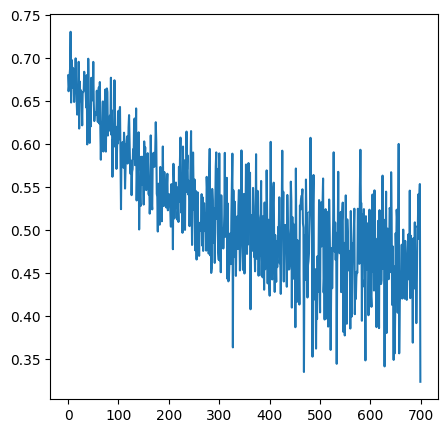

| | | | | | | | | | 

Epoch : 0 # 710
Loss: 0.504115879535675
--------------------
| | | | | | | | | | 

Epoch : 0 # 720
Loss: 0.5306850075721741
--------------------
| | | | | | | | | | 

Epoch : 0 # 730
Loss: 0.3496460020542145
--------------------
| | | | | | | | | | 

Epoch : 0 # 740
Loss: 0.467693030834198
--------------------
| | | | | | | | | | 

Epoch : 0 # 750
Loss: 0.6170075535774231
--------------------
| | | | | | | | | | 

Epoch : 0 # 760
Loss: 0.5137391090393066
--------------------
| | | | | | | | | | 

Epoch : 0 # 770
Loss: 0.4249783158302307
--------------------
| | | | | | | | | | 

Epoch : 0 # 780
Loss: 0.5535393357276917
--------------------
| | | | | | | | | | 

Epoch : 0 # 790
Loss: 0.5023959279060364
--------------------
| | | | | | | | | | 

Epoch : 0 # 800
Loss: 0.4350740909576416
--------------------


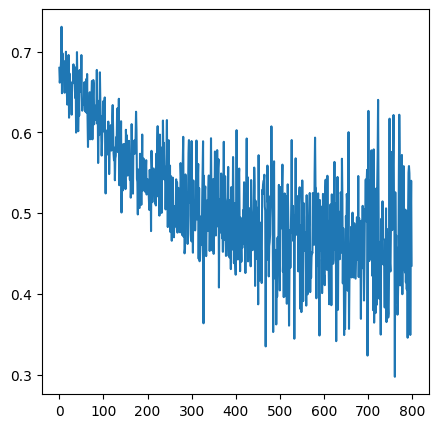

| | | | | | | | | | 

Epoch : 0 # 810
Loss: 0.5809157490730286
--------------------
| | | | | | | | | | 

Epoch : 0 # 820
Loss: 0.38043153285980225
--------------------
| | | | | | | | | | 

Epoch : 0 # 830
Loss: 0.3793260455131531
--------------------
| | | | | | | | | | 

Epoch : 0 # 840
Loss: 0.43385326862335205
--------------------
| | | | | | | | | | 

Epoch : 0 # 850
Loss: 0.41390353441238403
--------------------
| | | | | | | | | | 

Epoch : 0 # 860
Loss: 0.674122154712677
--------------------
| | | | | | | | | | 

Epoch : 0 # 870
Loss: 0.46270662546157837
--------------------
| | | | | | | | | | 

Epoch : 0 # 880
Loss: 0.49013298749923706
--------------------
| | | | | | | | | | 

Epoch : 0 # 890
Loss: 0.45145827531814575
--------------------
| | | | | | | | | | 

Epoch : 0 # 900
Loss: 0.4008282423019409
--------------------


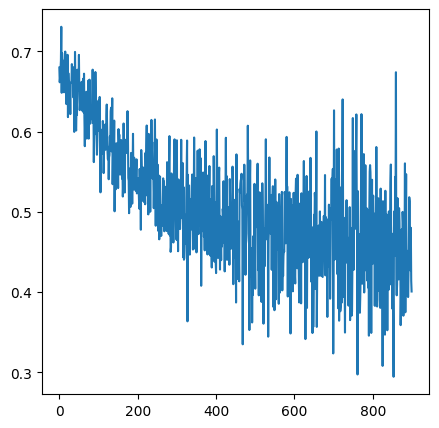

| | | | | | | | | | 

Epoch : 0 # 910
Loss: 0.4274173974990845
--------------------
| | | | | | | | | | 

Epoch : 0 # 920
Loss: 0.4297359883785248
--------------------
| | | | | | | | | | 

Epoch : 0 # 930
Loss: 0.5182926654815674
--------------------
| | | | | | | | | | 

Epoch : 0 # 940
Loss: 0.4394259750843048
--------------------
| | | | | | | | | | 

Epoch : 0 # 950
Loss: 0.43649885058403015
--------------------
| | | | | | | | | | 

Epoch : 0 # 960
Loss: 0.49565160274505615
--------------------
| | | | | | | | | | 

Epoch : 0 # 970
Loss: 0.4583702087402344
--------------------
| | | | | | | | | | 

Epoch : 0 # 980
Loss: 0.3754950761795044
--------------------
| | | | | | | | | | 

Epoch : 0 # 990
Loss: 0.435671865940094
--------------------
| | | | | | | | | | 

Epoch : 0 # 1000
Loss: 0.4579750895500183
--------------------


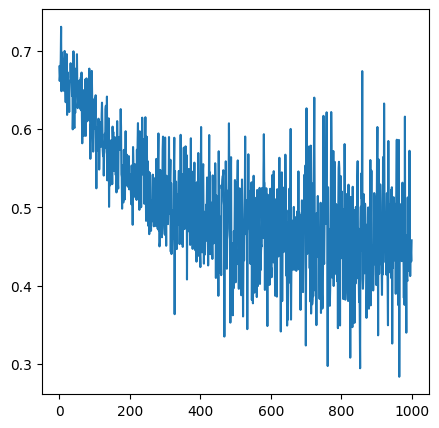

| | | | | | | | | | 

Epoch : 0 # 1010
Loss: 0.38722094893455505
--------------------
| | | | | | | | | | 

Epoch : 0 # 1020
Loss: 0.5623041391372681
--------------------
| | | | | | | | | | 

Epoch : 0 # 1030
Loss: 0.4648570716381073
--------------------
| | | | | | | | | | 

Epoch : 0 # 1040
Loss: 0.40834230184555054
--------------------
| | | | | | | | | | 

Epoch : 0 # 1050
Loss: 0.4583628177642822
--------------------
| | | | | | | | | | 

Epoch : 0 # 1060
Loss: 0.42190518975257874
--------------------
| | | | | | | | | | 

Epoch : 0 # 1070
Loss: 0.5041799545288086
--------------------
| | | | | | | | | | 

Epoch : 0 # 1080
Loss: 0.4414060711860657
--------------------
| | | | | | | | | | 

Epoch : 0 # 1090
Loss: 0.4691847562789917
--------------------
| | | | --------------------
Epoch#0
Accuracy : 0.7662109732627869
F1 Score : 0.6782659888267517
AUC-ROC : 0.8359453082084656
Specificity : 0.8742581009864807
Recall : 0.6077795624732971
ECE : 0.06305969700358384
-------------------

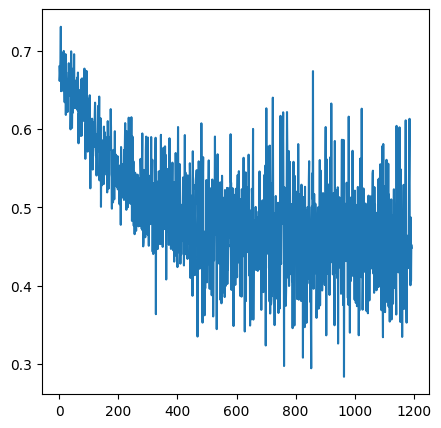

| | | | | | | | | | 

Epoch : 1 # 110
Loss: 0.38338878750801086
--------------------
| | | | | | | | | | 

Epoch : 1 # 120
Loss: 0.44439488649368286
--------------------
| | | | | | | | | | 

Epoch : 1 # 130
Loss: 0.3663788437843323
--------------------
| | | | | | | | | | 

Epoch : 1 # 140
Loss: 0.5297906994819641
--------------------
| | | | | | | | | | 

Epoch : 1 # 150
Loss: 0.4751502573490143
--------------------
| | | | | | | | | | 

Epoch : 1 # 160
Loss: 0.45735594630241394
--------------------
| | | | | | | | | | 

Epoch : 1 # 170
Loss: 0.5072006583213806
--------------------
| | | | | | | | | | 

Epoch : 1 # 180
Loss: 0.4359927773475647
--------------------
| | | | | | | | | | 

Epoch : 1 # 190
Loss: 0.522180438041687
--------------------
| | | | | | | | | | 

Epoch : 1 # 200
Loss: 0.5407817959785461
--------------------


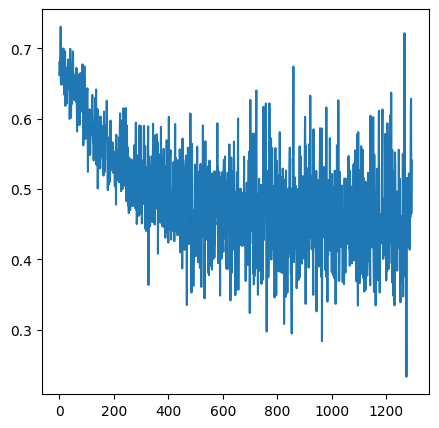

| | | | | | | | | | 

Epoch : 1 # 210
Loss: 0.5065239071846008
--------------------
| | | | | | | | | | 

Epoch : 1 # 220
Loss: 0.39156901836395264
--------------------
| | | | | | | | | | 

Epoch : 1 # 230
Loss: 0.416321337223053
--------------------
| | | | | | | | | | 

Epoch : 1 # 240
Loss: 0.39515864849090576
--------------------
| | | | | | | | | | 

Epoch : 1 # 250
Loss: 0.4109398424625397
--------------------
| | | | | | | | | | 

Epoch : 1 # 260
Loss: 0.5602318048477173
--------------------
| | | | | | | | | | 

Epoch : 1 # 270
Loss: 0.5286252498626709
--------------------
| | | | | | | | | | 

Epoch : 1 # 280
Loss: 0.37371838092803955
--------------------
| | | | | | | | | | 

Epoch : 1 # 290
Loss: 0.4467964470386505
--------------------
| | | | | | | | | | 

Epoch : 1 # 300
Loss: 0.5660724639892578
--------------------


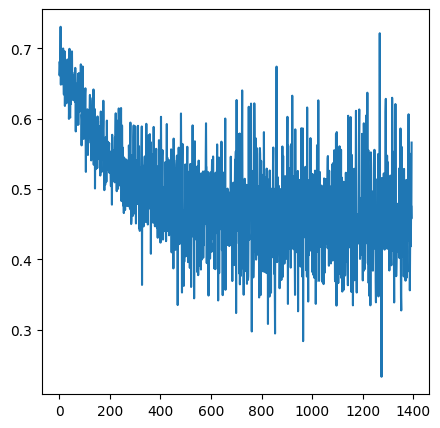

| | | | | | | | | | 

Epoch : 1 # 310
Loss: 0.5916640758514404
--------------------
| | | | | | | | | | 

Epoch : 1 # 320
Loss: 0.46075665950775146
--------------------
| | | | | | | | | | 

Epoch : 1 # 330
Loss: 0.44538170099258423
--------------------
| | | | | | | | | | 

Epoch : 1 # 340
Loss: 0.4544851779937744
--------------------
| | | | | | | | | | 

Epoch : 1 # 350
Loss: 0.4956701993942261
--------------------
| | | | | | | | | | 

Epoch : 1 # 360
Loss: 0.5150109529495239
--------------------
| | | | | | | | | | 

Epoch : 1 # 370
Loss: 0.5485337972640991
--------------------
| | | | | | | | | | 

Epoch : 1 # 380
Loss: 0.41174235939979553
--------------------
| | | | | | | | | | 

Epoch : 1 # 390
Loss: 0.4574534595012665
--------------------
| | | | | | | | | | 

Epoch : 1 # 400
Loss: 0.37213945388793945
--------------------


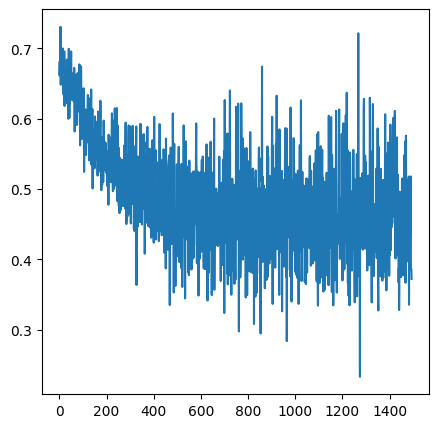

| | | | | | | | | | 

Epoch : 1 # 410
Loss: 0.5092554092407227
--------------------
| | | | | | | | | | 

Epoch : 1 # 420
Loss: 0.37228265404701233
--------------------
| | | | | | | | | | 

Epoch : 1 # 430
Loss: 0.4562690854072571
--------------------
| | | | | | | | | | 

Epoch : 1 # 440
Loss: 0.5048415660858154
--------------------
| | | | | | | | | | 

Epoch : 1 # 450
Loss: 0.5597044229507446
--------------------
| | | | | | | | | | 

Epoch : 1 # 460
Loss: 0.5002453923225403
--------------------
| | | | | | | | | | 

Epoch : 1 # 470
Loss: 0.44318926334381104
--------------------
| | | | | | | | | | 

Epoch : 1 # 480
Loss: 0.5891997814178467
--------------------
| | | | | | | | | | 

Epoch : 1 # 490
Loss: 0.44941702485084534
--------------------
| | | | | | | | | | 

Epoch : 1 # 500
Loss: 0.4783187508583069
--------------------


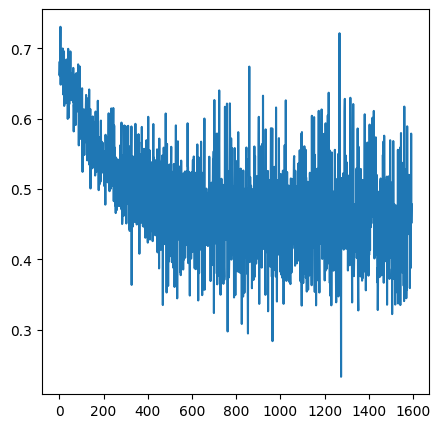

| | | | | | | | | | 

Epoch : 1 # 510
Loss: 0.41218996047973633
--------------------
| | | | | | | | | | 

Epoch : 1 # 520
Loss: 0.42481082677841187
--------------------
| | | | | | | | | | 

Epoch : 1 # 530
Loss: 0.3310222327709198
--------------------
| | | | | | | | | | 

Epoch : 1 # 540
Loss: 0.43289560079574585
--------------------
| | | | | | | | | | 

Epoch : 1 # 550
Loss: 0.38661688566207886
--------------------
| | | | | | | | | | 

Epoch : 1 # 560
Loss: 0.5361478328704834
--------------------
| | | | | | | | | | 

Epoch : 1 # 570
Loss: 0.44594234228134155
--------------------
| | | | | | | | | | 

Epoch : 1 # 580
Loss: 0.3736079931259155
--------------------
| | | | | | | | | | 

Epoch : 1 # 590
Loss: 0.4011194407939911
--------------------
| | | | | | | | | | 

Epoch : 1 # 600
Loss: 0.42511746287345886
--------------------


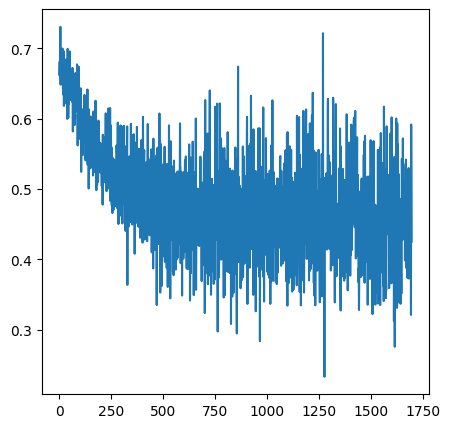

| | | | | | | | | | 

Epoch : 1 # 610
Loss: 0.47986117005348206
--------------------
| | | | | | | | | | 

Epoch : 1 # 620
Loss: 0.32281988859176636
--------------------
| | | | | | | | | | 

Epoch : 1 # 630
Loss: 0.5344448685646057
--------------------
| | | | | | | | | | 

Epoch : 1 # 640
Loss: 0.3319939076900482
--------------------
| | | | | | | | | | 

Epoch : 1 # 650
Loss: 0.43445515632629395
--------------------
| | | | | | | | | | 

Epoch : 1 # 660
Loss: 0.41224607825279236
--------------------
| | | | | | | | | | 

Epoch : 1 # 670
Loss: 0.3032769560813904
--------------------
| | | | | | | | | | 

Epoch : 1 # 680
Loss: 0.47925201058387756
--------------------
| | | | | | | | | | 

Epoch : 1 # 690
Loss: 0.4254269599914551
--------------------
| | | | | | | | | | 

Epoch : 1 # 700
Loss: 0.4389391541481018
--------------------


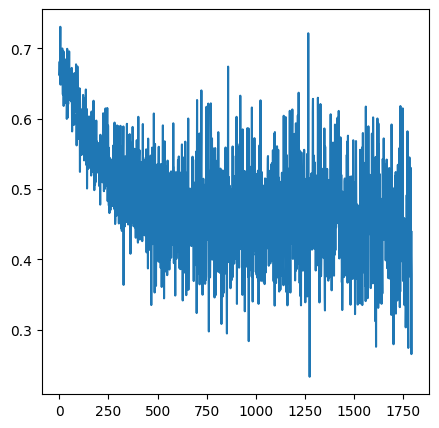

| | | | | | | | | | 

Epoch : 1 # 710
Loss: 0.47746437788009644
--------------------
| | | | | | | | | | 

Epoch : 1 # 720
Loss: 0.545958399772644
--------------------
| | | | | | | | | | 

Epoch : 1 # 730
Loss: 0.4204753637313843
--------------------
| | | | | | | | | | 

Epoch : 1 # 740
Loss: 0.3694590628147125
--------------------
| | | | | | | | | | 

Epoch : 1 # 750
Loss: 0.5046877861022949
--------------------
| | | | | | | | | | 

Epoch : 1 # 760
Loss: 0.37483519315719604
--------------------
| | | | | | | | | | 

Epoch : 1 # 770
Loss: 0.43395042419433594
--------------------
| | | | | | | | | | 

Epoch : 1 # 780
Loss: 0.40735501050949097
--------------------
| | | | | | | | | | 

Epoch : 1 # 790
Loss: 0.3718772530555725
--------------------
| | | | | | | | | | 

Epoch : 1 # 800
Loss: 0.48871612548828125
--------------------


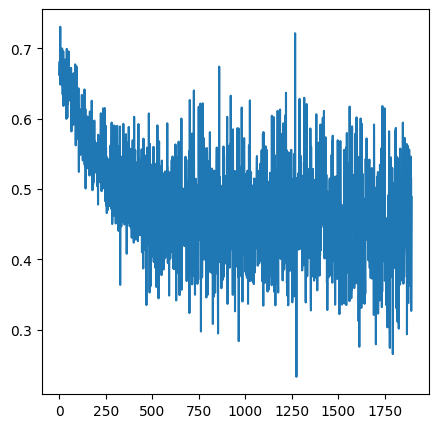

| | | | | | | | | | 

Epoch : 1 # 810
Loss: 0.4253317415714264
--------------------
| | | | | | | | | | 

Epoch : 1 # 820
Loss: 0.4861682057380676
--------------------
| | | | | | | | | | 

Epoch : 1 # 830
Loss: 0.3649372160434723
--------------------
| | | | | | | | | | 

Epoch : 1 # 840
Loss: 0.41147977113723755
--------------------
| | | | | | | | | | 

Epoch : 1 # 850
Loss: 0.45406901836395264
--------------------
| | | | | | | | | | 

Epoch : 1 # 860
Loss: 0.5330764055252075
--------------------
| | | | | | | | | | 

Epoch : 1 # 870
Loss: 0.4187937080860138
--------------------
| | | | | | | | | | 

Epoch : 1 # 880
Loss: 0.4337952435016632
--------------------
| | | | | | | | | | 

Epoch : 1 # 890
Loss: 0.4580991268157959
--------------------
| | | | | | | | | | 

Epoch : 1 # 900
Loss: 0.440018892288208
--------------------


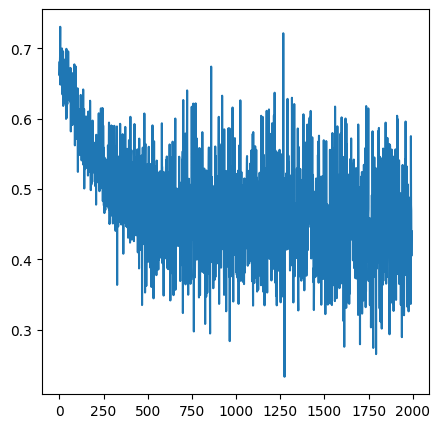

| | | | | | | | | | 

Epoch : 1 # 910
Loss: 0.49779626727104187
--------------------
| | | | | | | | | | 

Epoch : 1 # 920
Loss: 0.47557854652404785
--------------------
| | | | | | | | | | 

Epoch : 1 # 930
Loss: 0.35803547501564026
--------------------
| | | | | | | | | | 

Epoch : 1 # 940
Loss: 0.4211753010749817
--------------------
| | | | | | | | | | 

Epoch : 1 # 950
Loss: 0.2697845995426178
--------------------
| | | | | | | | | | 

Epoch : 1 # 960
Loss: 0.5373506546020508
--------------------
| | | | | | | | | | 

Epoch : 1 # 970
Loss: 0.38791021704673767
--------------------
| | | | | | | | | | 

Epoch : 1 # 980
Loss: 0.41966280341148376
--------------------
| | | | | | | | | | 

Epoch : 1 # 990
Loss: 0.3375033736228943
--------------------
| | | | | | | | | | 

Epoch : 1 # 1000
Loss: 0.388149619102478
--------------------


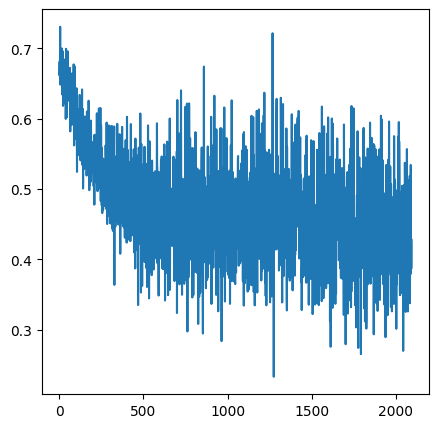

| | | | | | | | | | 

Epoch : 1 # 1010
Loss: 0.43423593044281006
--------------------
| | | | | | | | | | 

Epoch : 1 # 1020
Loss: 0.4262329339981079
--------------------
| | | | | | | | | | 

Epoch : 1 # 1030
Loss: 0.4529199004173279
--------------------
| | | | | | | | | | 

Epoch : 1 # 1040
Loss: 0.5353982448577881
--------------------
| | | | | | | | | | 

Epoch : 1 # 1050
Loss: 0.3418043553829193
--------------------
| | | | | | | | | | 

Epoch : 1 # 1060
Loss: 0.4153871238231659
--------------------
| | | | | | | | | | 

Epoch : 1 # 1070
Loss: 0.3290998935699463
--------------------
| | | | | | | | | | 

Epoch : 1 # 1080
Loss: 0.4785378873348236
--------------------
| | | | | | | | | | 

Epoch : 1 # 1090
Loss: 0.4682631194591522
--------------------
| | | | --------------------
Epoch#1
Accuracy : 0.7972256541252136
F1 Score : 0.7412309646606445
AUC-ROC : 0.8647670149803162
Specificity : 0.8524401187896729
Recall : 0.7162638306617737
ECE : 0.015463927683685472
--------------------

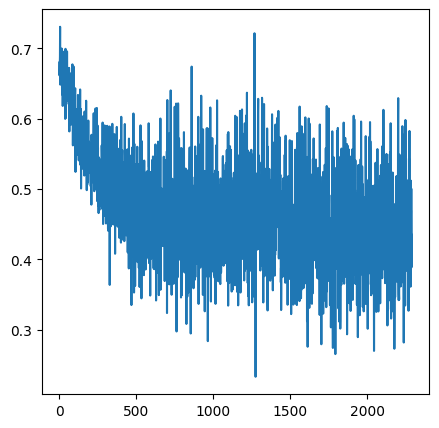

| | | | | | | | | | 

Epoch : 2 # 110
Loss: 0.5305992364883423
--------------------
| | | | | | | | | | 

Epoch : 2 # 120
Loss: 0.3938273787498474
--------------------
| | | | | | | | | | 

Epoch : 2 # 130
Loss: 0.329539954662323
--------------------
| | | | | | | | | | 

Epoch : 2 # 140
Loss: 0.48195916414260864
--------------------
| | | | | | | | | | 

Epoch : 2 # 150
Loss: 0.5116890668869019
--------------------
| | | | | | | | | | 

Epoch : 2 # 160
Loss: 0.44038254022598267
--------------------
| | | | | | | | | | 

Epoch : 2 # 170
Loss: 0.4239628314971924
--------------------
| | | | | | | | | | 

Epoch : 2 # 180
Loss: 0.37716782093048096
--------------------
| | | | | | | | | | 

Epoch : 2 # 190
Loss: 0.491835355758667
--------------------
| | | | | | | | | | 

Epoch : 2 # 200
Loss: 0.37985318899154663
--------------------


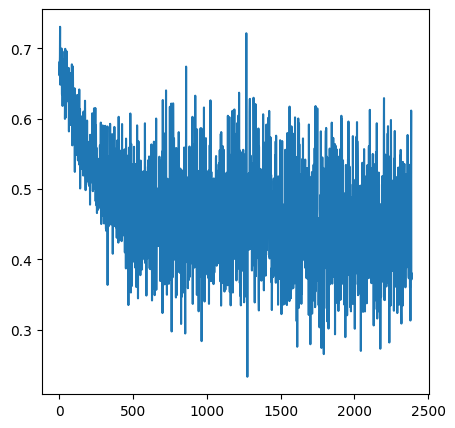

| | | | | | | | | | 

Epoch : 2 # 210
Loss: 0.5578794479370117
--------------------
| | | | | | | | | | 

Epoch : 2 # 220
Loss: 0.44676142930984497
--------------------
| | | | | | | | | | 

Epoch : 2 # 230
Loss: 0.49436840415000916
--------------------
| | | | | | | | | | 

Epoch : 2 # 240
Loss: 0.37868499755859375
--------------------
| | | | | | | | | | 

Epoch : 2 # 250
Loss: 0.3742353320121765
--------------------
| | | | | | | | | | 

Epoch : 2 # 260
Loss: 0.2995944023132324
--------------------
| | | | | | | | | | 

Epoch : 2 # 270
Loss: 0.5196173191070557
--------------------
| | | | | | | | | | 

Epoch : 2 # 280
Loss: 0.3956955075263977
--------------------
| | | | | | | | | | 

Epoch : 2 # 290
Loss: 0.5430081486701965
--------------------
| | | | | | | | | | 

Epoch : 2 # 300
Loss: 0.46144723892211914
--------------------


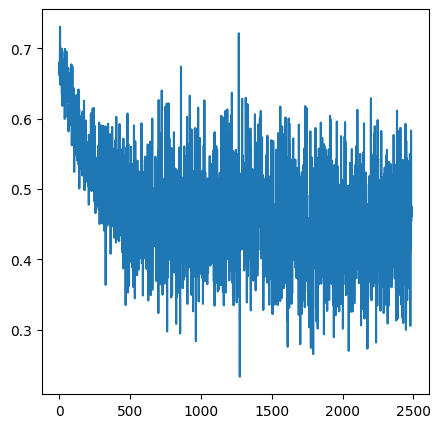

| | | | | | | | | | 

Epoch : 2 # 310
Loss: 0.5547074675559998
--------------------
| | | | | | | | | | 

Epoch : 2 # 320
Loss: 0.46332848072052
--------------------
| | | | | | | | | | 

Epoch : 2 # 330
Loss: 0.4732074737548828
--------------------
| | | | | | | | | | 

Epoch : 2 # 340
Loss: 0.5424663424491882
--------------------
| | | | | | | | | | 

Epoch : 2 # 350
Loss: 0.5066725611686707
--------------------
| | | | | | | | | | 

Epoch : 2 # 360
Loss: 0.3735443353652954
--------------------
| | | | | | | | | | 

Epoch : 2 # 370
Loss: 0.3782857060432434
--------------------
| | | | | | | | | | 

Epoch : 2 # 380
Loss: 0.39526987075805664
--------------------
| | | | | | | | | | 

Epoch : 2 # 390
Loss: 0.42450934648513794
--------------------
| | | | | | | | | | 

Epoch : 2 # 400
Loss: 0.5047207474708557
--------------------


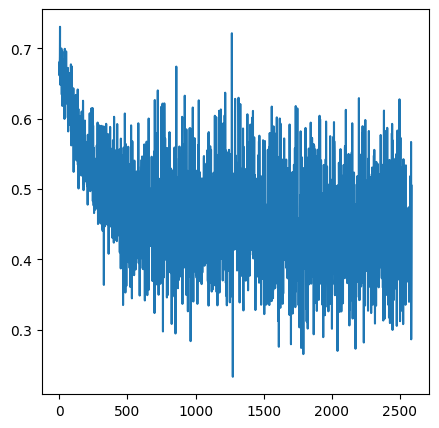

| | | | | | | | | | 

Epoch : 2 # 410
Loss: 0.39948344230651855
--------------------
| | | | | | | | | | 

Epoch : 2 # 420
Loss: 0.4334854185581207
--------------------
| | | | | | | | | | 

Epoch : 2 # 430
Loss: 0.2999976873397827
--------------------
| | | | | | | | | | 

Epoch : 2 # 440
Loss: 0.4442429542541504
--------------------
| | | | | | | | | | 

Epoch : 2 # 450
Loss: 0.4742567539215088
--------------------
| | | | | | | | | | 

Epoch : 2 # 460
Loss: 0.4954954981803894
--------------------
| | | | | | | | | | 

Epoch : 2 # 470
Loss: 0.40810540318489075
--------------------
| | | | | | | | | | 

Epoch : 2 # 480
Loss: 0.5754604339599609
--------------------
| | | | | | | | | | 

Epoch : 2 # 490
Loss: 0.395233690738678
--------------------
| | | | | | | | | | 

Epoch : 2 # 500
Loss: 0.43178388476371765
--------------------


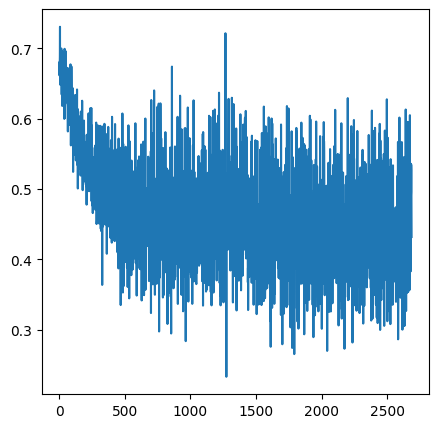

| | | | | | | | | | 

Epoch : 2 # 510
Loss: 0.4806779623031616
--------------------
| | | | | | | | | | 

Epoch : 2 # 520
Loss: 0.3828980028629303
--------------------
| | | | | | | | | | 

Epoch : 2 # 530
Loss: 0.38558441400527954
--------------------
| | | | | | | | | | 

Epoch : 2 # 540
Loss: 0.47252631187438965
--------------------
| | | | | | | | | | 

Epoch : 2 # 550
Loss: 0.4150732755661011
--------------------
| | | | | | | | | | 

Epoch : 2 # 560
Loss: 0.34381359815597534
--------------------
| | | | | | | | | | 

Epoch : 2 # 570
Loss: 0.44490307569503784
--------------------
| | | | | | | | | | 

Epoch : 2 # 580
Loss: 0.5004715919494629
--------------------
| | | | | | | | | | 

Epoch : 2 # 590
Loss: 0.4921712279319763
--------------------
| | | | | | | | | | 

Epoch : 2 # 600
Loss: 0.3108735680580139
--------------------


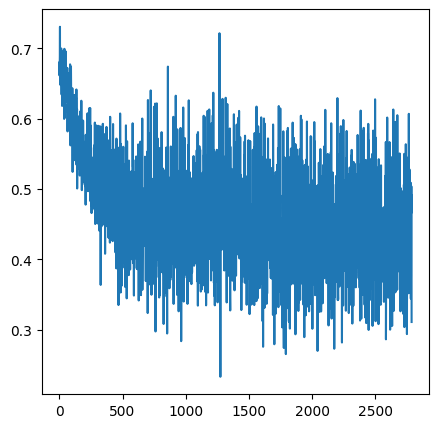

| | | | | | | | | | 

Epoch : 2 # 610
Loss: 0.4154031574726105
--------------------
| | | | | | | | | | 

Epoch : 2 # 620
Loss: 0.4164500832557678
--------------------
| | | | | | | | | | 

Epoch : 2 # 630
Loss: 0.4083976745605469
--------------------
| | | | | | | | | | 

Epoch : 2 # 640
Loss: 0.42186716198921204
--------------------
| | | | | | | | | | 

Epoch : 2 # 650
Loss: 0.5251903533935547
--------------------
| | | | | | | | | | 

Epoch : 2 # 660
Loss: 0.5500843524932861
--------------------
| | | | | | | | | | 

Epoch : 2 # 670
Loss: 0.3729611337184906
--------------------
| | | | | | | | | | 

Epoch : 2 # 680
Loss: 0.48311278223991394
--------------------
| | | | | | | | | | 

Epoch : 2 # 690
Loss: 0.4342142343521118
--------------------
| | | | | | | | | | 

Epoch : 2 # 700
Loss: 0.3185504078865051
--------------------


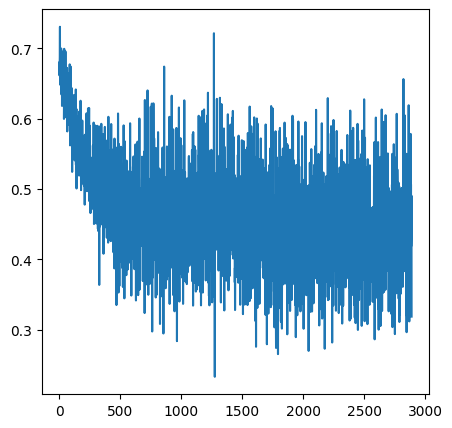

| | | | | | | | | | 

Epoch : 2 # 710
Loss: 0.42452865839004517
--------------------
| | | | | | | | | | 

Epoch : 2 # 720
Loss: 0.5228595733642578
--------------------
| | | | | | | | | | 

Epoch : 2 # 730
Loss: 0.43613913655281067
--------------------
| | | | | | | | | | 

Epoch : 2 # 740
Loss: 0.49007129669189453
--------------------
| | | | | | | | | | 

Epoch : 2 # 750
Loss: 0.5645921230316162
--------------------
| | | | | | | | | | 

Epoch : 2 # 760
Loss: 0.47964996099472046
--------------------
| | | | | | | | | | 

Epoch : 2 # 770
Loss: 0.4092821180820465
--------------------
| | | | | | | | | | 

Epoch : 2 # 780
Loss: 0.4929981231689453
--------------------
| | | | | | | | | | 

Epoch : 2 # 790
Loss: 0.43780744075775146
--------------------
| | | | | | | | | | 

Epoch : 2 # 800
Loss: 0.5268463492393494
--------------------


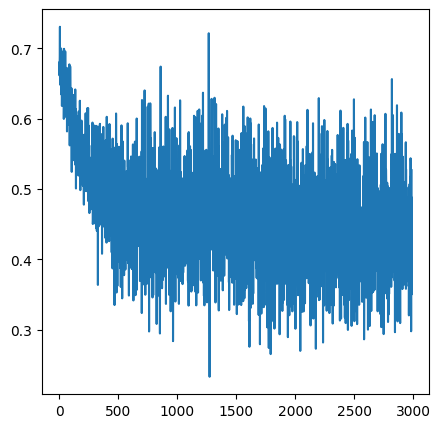

| | | | | | | | | | 

Epoch : 2 # 810
Loss: 0.3936783969402313
--------------------
| | | | | | | | | | 

Epoch : 2 # 820
Loss: 0.42692625522613525
--------------------
| | | | | | | | | | 

Epoch : 2 # 830
Loss: 0.5588663816452026
--------------------
| | | | | | | | | | 

Epoch : 2 # 840
Loss: 0.5645506381988525
--------------------
| | | | | | | | | | 

Epoch : 2 # 850
Loss: 0.38965460658073425
--------------------
| | | | | | | | | | 

Epoch : 2 # 860
Loss: 0.43581557273864746
--------------------
| | | | | | | | | | 

Epoch : 2 # 870
Loss: 0.359596312046051
--------------------
| | | | | | | | | | 

Epoch : 2 # 880
Loss: 0.4404045343399048
--------------------
| | | | | | | | | | 

Epoch : 2 # 890
Loss: 0.45035600662231445
--------------------
| | | | | | | | | | 

Epoch : 2 # 900
Loss: 0.43033885955810547
--------------------


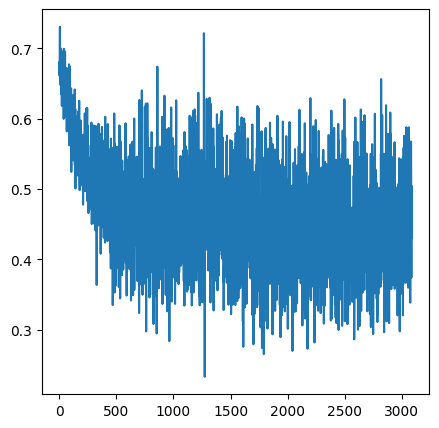

| | | | | | | | | | 

Epoch : 2 # 910
Loss: 0.4504674971103668
--------------------
| | | | | | | | | | 

Epoch : 2 # 920
Loss: 0.44135481119155884
--------------------
| | | | | | | | | | 

Epoch : 2 # 930
Loss: 0.43101102113723755
--------------------
| | | | | | | | | | 

Epoch : 2 # 940
Loss: 0.3271598815917969
--------------------
| | | | | | | | | | 

Epoch : 2 # 950
Loss: 0.3525172770023346
--------------------
| | | | | | | | | | 

Epoch : 2 # 960
Loss: 0.3222869038581848
--------------------
| | | | | | | | | | 

Epoch : 2 # 970
Loss: 0.47202610969543457
--------------------
| | | | | | | | | | 

Epoch : 2 # 980
Loss: 0.33903709053993225
--------------------
| | | | | | | | | | 

Epoch : 2 # 990
Loss: 0.3708301782608032
--------------------
| | | | | | | | | | 

Epoch : 2 # 1000
Loss: 0.40151748061180115
--------------------


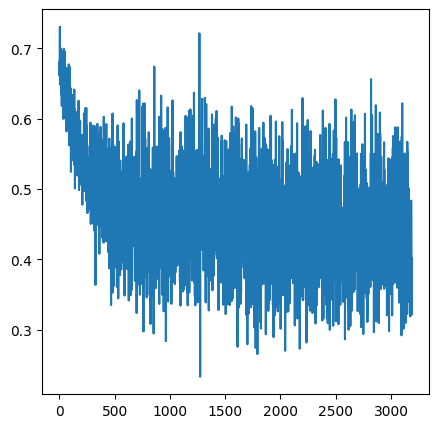

| | | | | | | | | | 

Epoch : 2 # 1010
Loss: 0.6381215453147888
--------------------
| | | | | | | | | | 

Epoch : 2 # 1020
Loss: 0.4556484818458557
--------------------
| | | | | | | | | | 

Epoch : 2 # 1030
Loss: 0.4325811564922333
--------------------
| | | | | | | | | | 

Epoch : 2 # 1040
Loss: 0.4291076362133026
--------------------
| | | | | | | | | | 

Epoch : 2 # 1050
Loss: 0.37705159187316895
--------------------
| | | | | | | | | | 

Epoch : 2 # 1060
Loss: 0.3552698791027069
--------------------
| | | | | | | | | | 

Epoch : 2 # 1070
Loss: 0.4100516438484192
--------------------
| | | | | | | | | | 

Epoch : 2 # 1080
Loss: 0.4463532865047455
--------------------
| | | | | | | | | | 

Epoch : 2 # 1090
Loss: 0.45191118121147156
--------------------
| | | | --------------------
Epoch#2
Accuracy : 0.7990399599075317
F1 Score : 0.7417714595794678
AUC-ROC : 0.8684282898902893
Specificity : 0.8584953546524048
Recall : 0.7118596434593201
ECE : 0.011671830833662416
-------------------

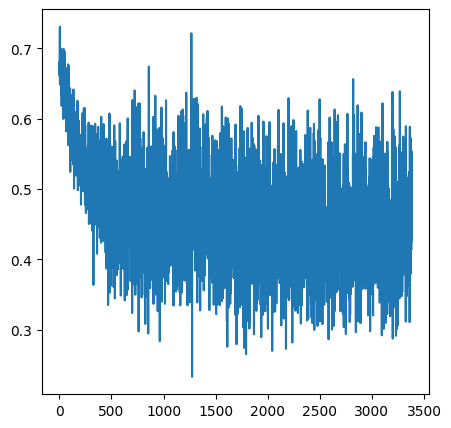

| | | | | | | | | | 

Epoch : 3 # 110
Loss: 0.45634186267852783
--------------------
| | | | | | | | | | 

Epoch : 3 # 120
Loss: 0.4425605535507202
--------------------
| | | | | | | | | | 

Epoch : 3 # 130
Loss: 0.4864152669906616
--------------------
| | | | | | | | | | 

Epoch : 3 # 140
Loss: 0.41428375244140625
--------------------
| | | | | | | | | | 

Epoch : 3 # 150
Loss: 0.4089980721473694
--------------------
| | | | | | | | | | 

Epoch : 3 # 160
Loss: 0.351396381855011
--------------------
| | | | | | | | | | 

Epoch : 3 # 170
Loss: 0.4668259620666504
--------------------
| | | | | | | | | | 

Epoch : 3 # 180
Loss: 0.44251370429992676
--------------------
| | | | | | | | | | 

Epoch : 3 # 190
Loss: 0.4436551630496979
--------------------
| | | | | | | | | | 

Epoch : 3 # 200
Loss: 0.4824172258377075
--------------------


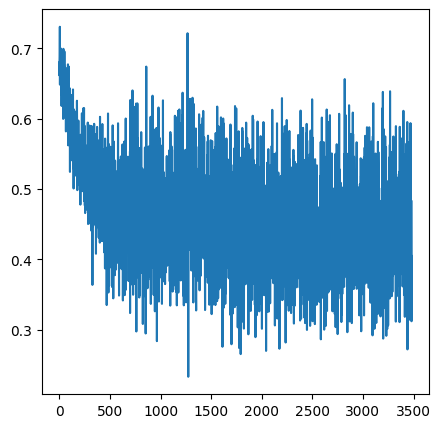

| | | | | | | | | | 

Epoch : 3 # 210
Loss: 0.3866210877895355
--------------------
| | | | | | | | | | 

Epoch : 3 # 220
Loss: 0.42148640751838684
--------------------
| | | | | | | | | | 

Epoch : 3 # 230
Loss: 0.37605687975883484
--------------------
| | | | | | | | | | 

Epoch : 3 # 240
Loss: 0.4788377285003662
--------------------
| | | | | | | | | | 

Epoch : 3 # 250
Loss: 0.45181208848953247
--------------------
| | | | | | | | | | 

Epoch : 3 # 260
Loss: 0.4464458227157593
--------------------
| | | | | | | | | | 

Epoch : 3 # 270
Loss: 0.24930676817893982
--------------------
| | | | | | | | | | 

Epoch : 3 # 280
Loss: 0.42584428191185
--------------------
| | | | | | | | | | 

Epoch : 3 # 290
Loss: 0.5130655765533447
--------------------
| | | | | | | | | | 

Epoch : 3 # 300
Loss: 0.44868162274360657
--------------------


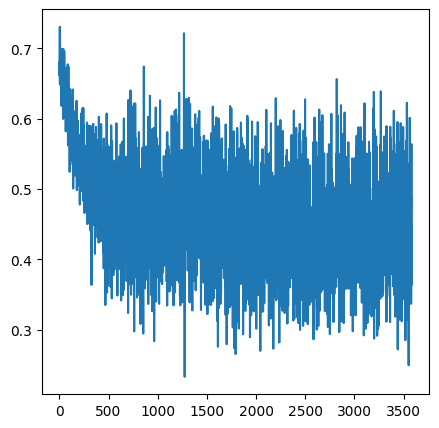

| | | | | | | | | | 

Epoch : 3 # 310
Loss: 0.5398777723312378
--------------------
| | | | | | | | | | 

Epoch : 3 # 320
Loss: 0.32903167605400085
--------------------
| | | | | | | | | | 

Epoch : 3 # 330
Loss: 0.449953556060791
--------------------
| | | | | | | | | | 

Epoch : 3 # 340
Loss: 0.4111136794090271
--------------------
| | | | | | | | | | 

Epoch : 3 # 350
Loss: 0.3753354549407959
--------------------
| | | | | | | | | | 

Epoch : 3 # 360
Loss: 0.32541602849960327
--------------------
| | | | | | | | | | 

Epoch : 3 # 370
Loss: 0.42472150921821594
--------------------
| | | | | | | | | | 

Epoch : 3 # 380
Loss: 0.3608815371990204
--------------------
| | | | | | | | | | 

Epoch : 3 # 390
Loss: 0.3907982110977173
--------------------
| | | | | | | | | | 

Epoch : 3 # 400
Loss: 0.5436424016952515
--------------------


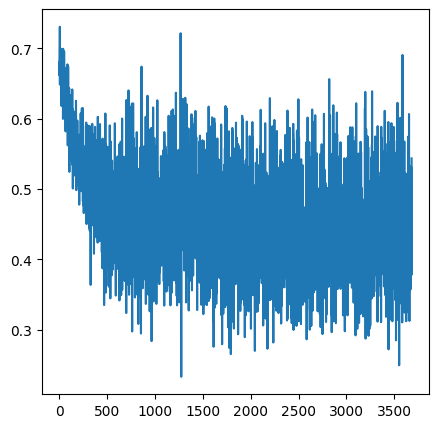

| | | | | | | | | | 

Epoch : 3 # 410
Loss: 0.5056788921356201
--------------------
| | | | | | | | | | 

Epoch : 3 # 420
Loss: 0.46906471252441406
--------------------
| | | | | | | | | | 

Epoch : 3 # 430
Loss: 0.524507999420166
--------------------
| | | | | | | | | | 

Epoch : 3 # 440
Loss: 0.5243192911148071
--------------------
| | | | | | | | | | 

Epoch : 3 # 450
Loss: 0.3579818904399872
--------------------
| | | | | | | | | | 

Epoch : 3 # 460
Loss: 0.4105559289455414
--------------------
| | | | | | | | | | 

Epoch : 3 # 470
Loss: 0.5389218330383301
--------------------
| | | | | | | | | | 

Epoch : 3 # 480
Loss: 0.4661642014980316
--------------------
| | | | | | | | | | 

Epoch : 3 # 490
Loss: 0.37446463108062744
--------------------
| | | | | | | | | | 

Epoch : 3 # 500
Loss: 0.48193708062171936
--------------------


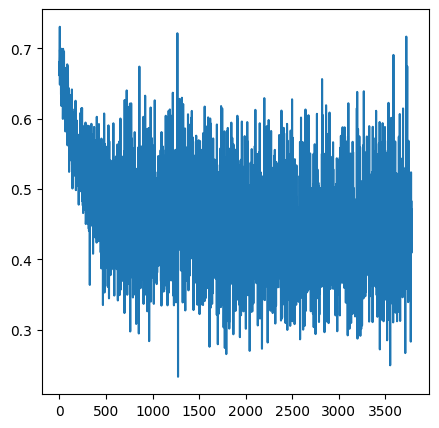

| | | | | | | | | | 

Epoch : 3 # 510
Loss: 0.4553607702255249
--------------------
| | | | | | | | | | 

Epoch : 3 # 520
Loss: 0.3388019800186157
--------------------
| | | | | | | | | | 

Epoch : 3 # 530
Loss: 0.5947846174240112
--------------------
| | | | | | | | | | 

Epoch : 3 # 540
Loss: 0.37640687823295593
--------------------
| | | | | | | | | | 

Epoch : 3 # 550
Loss: 0.543441891670227
--------------------
| | | | | | | | | | 

Epoch : 3 # 560
Loss: 0.4702453017234802
--------------------
| | | | | | | | | | 

Epoch : 3 # 570
Loss: 0.42850691080093384
--------------------
| | | | | | | | | | 

Epoch : 3 # 580
Loss: 0.459441602230072
--------------------
| | | | | | | | | | 

Epoch : 3 # 590
Loss: 0.4484022557735443
--------------------
| | | | | | | | | | 

Epoch : 3 # 600
Loss: 0.43377411365509033
--------------------


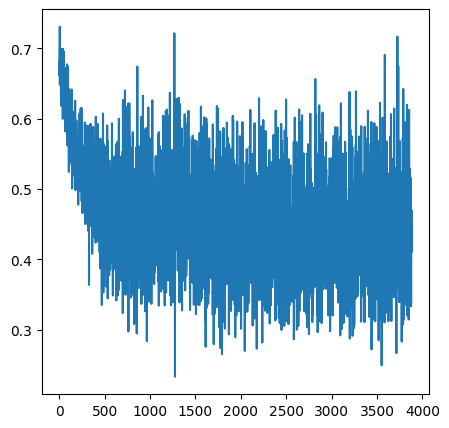

| | | | | | | | | | 

Epoch : 3 # 610
Loss: 0.43615397810935974
--------------------
| | | | | | | | | | 

Epoch : 3 # 620
Loss: 0.507091760635376
--------------------
| | | | | | | | | | 

Epoch : 3 # 630
Loss: 0.3821670114994049
--------------------
| | | | | | | | | | 

Epoch : 3 # 640
Loss: 0.4188086986541748
--------------------
| | | | | | | | | | 

Epoch : 3 # 650
Loss: 0.4011044502258301
--------------------
| | | | | | | | | | 

Epoch : 3 # 660
Loss: 0.39435631036758423
--------------------
| | | | | | | | | | 

Epoch : 3 # 670
Loss: 0.4112529158592224
--------------------
| | | | | | | | | | 

Epoch : 3 # 680
Loss: 0.42077600955963135
--------------------
| | | | | | | | | | 

Epoch : 3 # 690
Loss: 0.5445396900177002
--------------------
| | | | | | | | | | 

Epoch : 3 # 700
Loss: 0.4576738476753235
--------------------


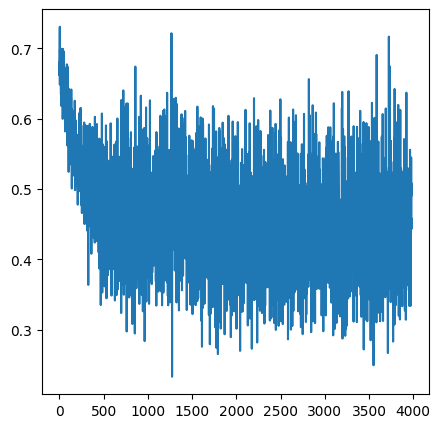

| | | | | | | | | | 

Epoch : 3 # 710
Loss: 0.5011401772499084
--------------------
| | | | | | | | | | 

Epoch : 3 # 720
Loss: 0.48046061396598816
--------------------
| | | | | | | | | | 

Epoch : 3 # 730
Loss: 0.3816690444946289
--------------------
| | | | | | | | | | 

Epoch : 3 # 740
Loss: 0.3761451244354248
--------------------
| | | | | | | | | | 

Epoch : 3 # 750
Loss: 0.45938640832901
--------------------
| | | | | | | | | | 

Epoch : 3 # 760
Loss: 0.3794974684715271
--------------------
| | | | | | | | | | 

Epoch : 3 # 770
Loss: 0.508176863193512
--------------------
| | | | | | | | | | 

Epoch : 3 # 780
Loss: 0.38175034523010254
--------------------
| | | | | | | | | | 

Epoch : 3 # 790
Loss: 0.44880327582359314
--------------------
| | | | | | | | | | 

Epoch : 3 # 800
Loss: 0.5122785568237305
--------------------


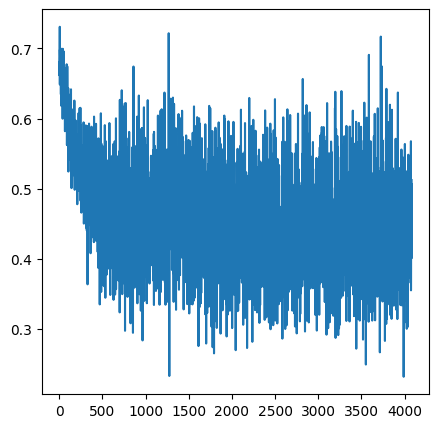

| | | | | | | | | | 

Epoch : 3 # 810
Loss: 0.4913238286972046
--------------------
| | | | | | | | | | 

Epoch : 3 # 820
Loss: 0.37265345454216003
--------------------
| | | | | | | | | | 

Epoch : 3 # 830
Loss: 0.3558742105960846
--------------------
| | | | | | | | | | 

Epoch : 3 # 840
Loss: 0.42194291949272156
--------------------
| | | | | | | | | | 

Epoch : 3 # 850
Loss: 0.5194581747055054
--------------------
| | | | | | | | | | 

Epoch : 3 # 860
Loss: 0.440448522567749
--------------------
| | | | | | | | | | 

Epoch : 3 # 870
Loss: 0.4284723997116089
--------------------
| | | | | | | | | | 

Epoch : 3 # 880
Loss: 0.3809259533882141
--------------------
| | | | | | | | | | 

Epoch : 3 # 890
Loss: 0.32673659920692444
--------------------
| | | | | | | | | | 

Epoch : 3 # 900
Loss: 0.44346028566360474
--------------------


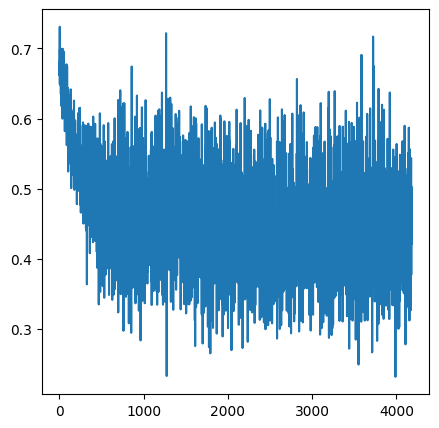

| | | | | | | | | | 

Epoch : 3 # 910
Loss: 0.38911905884742737
--------------------
| | | | | | | | | | 

Epoch : 3 # 920
Loss: 0.4509059190750122
--------------------
| | | | | | | | | | 

Epoch : 3 # 930
Loss: 0.4852483570575714
--------------------
| | | | | | | | | | 

Epoch : 3 # 940
Loss: 0.5454913377761841
--------------------
| | | | | | | | | | 

Epoch : 3 # 950
Loss: 0.36044883728027344
--------------------
| | | | | | | | | | 

Epoch : 3 # 960
Loss: 0.37737345695495605
--------------------
| | | | | | | | | | 

Epoch : 3 # 970
Loss: 0.48628729581832886
--------------------
| | | | | | | | | | 

Epoch : 3 # 980
Loss: 0.3974135220050812
--------------------
| | | | | | | | | | 

Epoch : 3 # 990
Loss: 0.52052241563797
--------------------
| | | | | | | | | | 

Epoch : 3 # 1000
Loss: 0.3587491512298584
--------------------


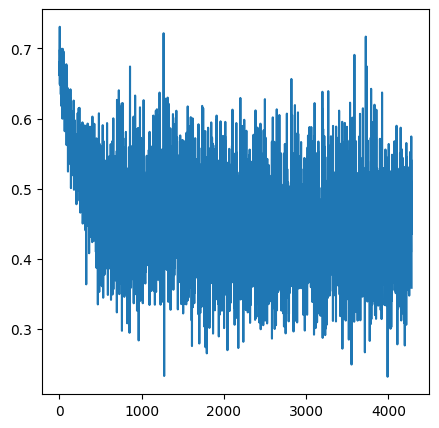

| | | | | | | | | | 

Epoch : 3 # 1010
Loss: 0.41423550248146057
--------------------
| | | | | | | | | | 

Epoch : 3 # 1020
Loss: 0.39653751254081726
--------------------
| | | | | | | | | | 

Epoch : 3 # 1030
Loss: 0.47404032945632935
--------------------
| | | | | | | | | | 

Epoch : 3 # 1040
Loss: 0.3290480375289917
--------------------
| | | | | | | | | | 

Epoch : 3 # 1050
Loss: 0.44757699966430664
--------------------
| | | | | | | | | | 

Epoch : 3 # 1060
Loss: 0.4967205822467804
--------------------
| | | | | | | | | | 

Epoch : 3 # 1070
Loss: 0.3718799948692322
--------------------
| | | | | | | | | | 

Epoch : 3 # 1080
Loss: 0.497050940990448
--------------------
| | | | | | | | | | 

Epoch : 3 # 1090
Loss: 0.38925421237945557
--------------------
| | | | --------------------
Epoch#3
Accuracy : 0.8009400367736816
F1 Score : 0.7434452772140503
AUC-ROC : 0.8709607720375061
Specificity : 0.8620515465736389
Recall : 0.7113311290740967
ECE : 0.011205394780915633
-----------------

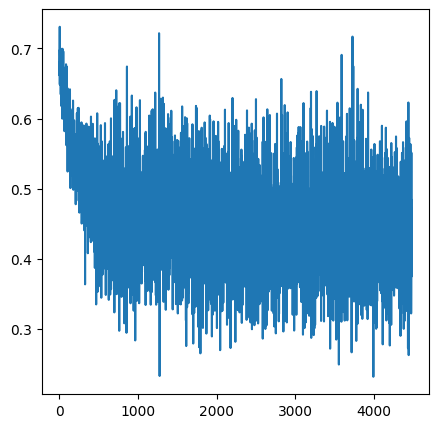

| | | | | | | | | | 

Epoch : 4 # 110
Loss: 0.4225948750972748
--------------------
| | | | | | | | | | 

Epoch : 4 # 120
Loss: 0.46237391233444214
--------------------
| | | | | | | | | | 

Epoch : 4 # 130
Loss: 0.4431172013282776
--------------------
| | | | | | | | | | 

Epoch : 4 # 140
Loss: 0.5230028629302979
--------------------
| | | | | | | | | | 

Epoch : 4 # 150
Loss: 0.38518446683883667
--------------------
| | | | | | | | | | 

Epoch : 4 # 160
Loss: 0.4075630307197571
--------------------
| | | | | | | | | | 

Epoch : 4 # 170
Loss: 0.485887736082077
--------------------
| | | | | | | | | | 

Epoch : 4 # 180
Loss: 0.41356390714645386
--------------------
| | | | | | | | | | 

Epoch : 4 # 190
Loss: 0.3528866767883301
--------------------
| | | | | | | | | | 

Epoch : 4 # 200
Loss: 0.4726555645465851
--------------------


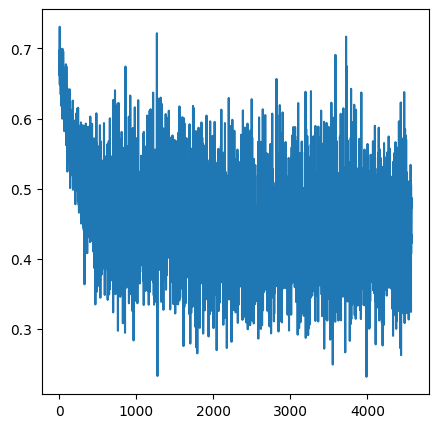

| | | | | | | | | | 

Epoch : 4 # 210
Loss: 0.5127042531967163
--------------------
| | | | | | | | | | 

Epoch : 4 # 220
Loss: 0.42758622765541077
--------------------
| | | | | | | | | | 

Epoch : 4 # 230
Loss: 0.4607653021812439
--------------------
| | | | | | | | | | 

Epoch : 4 # 240
Loss: 0.36080390214920044
--------------------
| | | | | | | | | | 

Epoch : 4 # 250
Loss: 0.4535979628562927
--------------------
| | | | | | | | | | 

Epoch : 4 # 260
Loss: 0.4898974895477295
--------------------
| | | | | | | | | | 

Epoch : 4 # 270
Loss: 0.3989279270172119
--------------------
| | | | | | | | | | 

Epoch : 4 # 280
Loss: 0.5093177556991577
--------------------
| | | | | | | | | | 

Epoch : 4 # 290
Loss: 0.464400976896286
--------------------
| | | | | | | | | | 

Epoch : 4 # 300
Loss: 0.39844244718551636
--------------------


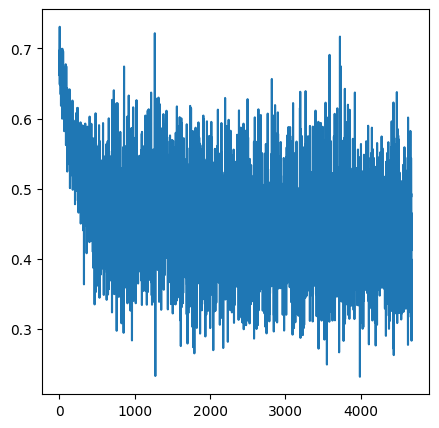

| | | | | | | | | | 

Epoch : 4 # 310
Loss: 0.4567449986934662
--------------------
| | | | | | | | | | 

Epoch : 4 # 320
Loss: 0.4804334044456482
--------------------
| | | | | | | | | | 

Epoch : 4 # 330
Loss: 0.4521940350532532
--------------------
| | | | | | | | | | 

Epoch : 4 # 340
Loss: 0.42902207374572754
--------------------
| | | | | | | | | | 

Epoch : 4 # 350
Loss: 0.4321158230304718
--------------------
| | | | | | | | | | 

Epoch : 4 # 360
Loss: 0.3722059726715088
--------------------
| | | | | | | | | | 

Epoch : 4 # 370
Loss: 0.5229867696762085
--------------------
| | | | | | | | | | 

Epoch : 4 # 380
Loss: 0.3816690444946289
--------------------
| | | | | | | | | | 

Epoch : 4 # 390
Loss: 0.36691445112228394
--------------------
| | | | | | | | | | 

Epoch : 4 # 400
Loss: 0.5057138204574585
--------------------


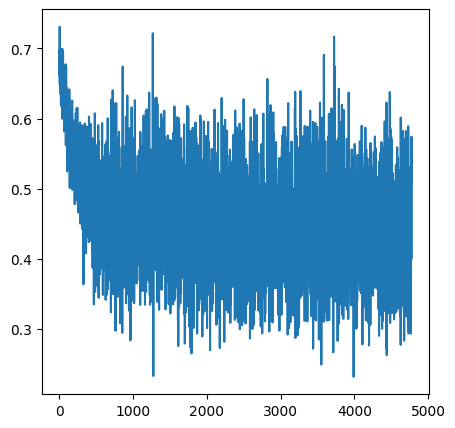

| | | | | | | | | | 

Epoch : 4 # 410
Loss: 0.46819597482681274
--------------------
| | | | | | | | | | 

Epoch : 4 # 420
Loss: 0.3470306098461151
--------------------
| | | | | | | | | | 

Epoch : 4 # 430
Loss: 0.35412734746932983
--------------------
| | | | | | | | | | 

Epoch : 4 # 440
Loss: 0.4512922167778015
--------------------
| | | | | | | | | | 

Epoch : 4 # 450
Loss: 0.40783053636550903
--------------------
| | | | | | | | | | 

Epoch : 4 # 460
Loss: 0.42172813415527344
--------------------
| | | | | | | | | | 

Epoch : 4 # 470
Loss: 0.5277672410011292
--------------------
| | | | | | | | | | 

Epoch : 4 # 480
Loss: 0.4351329505443573
--------------------
| | | | | | | | | | 

Epoch : 4 # 490
Loss: 0.3691411316394806
--------------------
| | | | | | | | | | 

Epoch : 4 # 500
Loss: 0.43387848138809204
--------------------


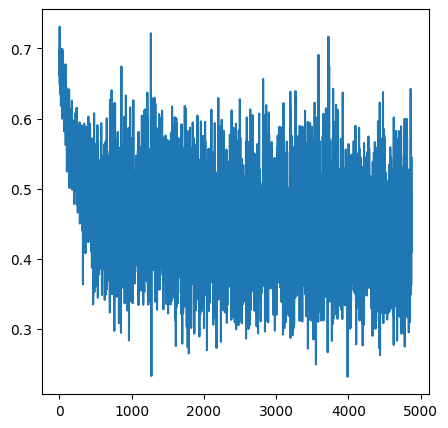

| | | | | | | | | | 

Epoch : 4 # 510
Loss: 0.4575779438018799
--------------------
| | | | | | | | | | 

Epoch : 4 # 520
Loss: 0.4813188910484314
--------------------
| | | | | | | | | | 

Epoch : 4 # 530
Loss: 0.48804670572280884
--------------------
| | | | | | | | | | 

Epoch : 4 # 540
Loss: 0.37709102034568787
--------------------
| | | | | | | | | | 

Epoch : 4 # 550
Loss: 0.4292730391025543
--------------------
| | | | | | | | | | 

Epoch : 4 # 560
Loss: 0.4322308301925659
--------------------
| | | | | | | | | | 

Epoch : 4 # 570
Loss: 0.4358089566230774
--------------------
| | | | | | | | | | 

Epoch : 4 # 580
Loss: 0.47266072034835815
--------------------
| | | | | | | | | | 

Epoch : 4 # 590
Loss: 0.4499732553958893
--------------------
| | | | | | | | | | 

Epoch : 4 # 600
Loss: 0.5022367238998413
--------------------


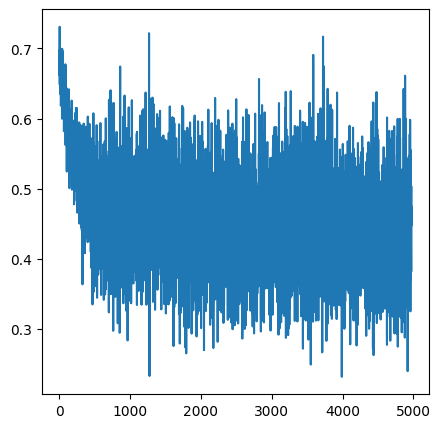

| | | | | | | | | | 

Epoch : 4 # 610
Loss: 0.34255969524383545
--------------------
| | | | | | | | | | 

Epoch : 4 # 620
Loss: 0.3670281171798706
--------------------
| | | | | | | | | | 

Epoch : 4 # 630
Loss: 0.43709248304367065
--------------------
| | | | | | | | | | 

Epoch : 4 # 640
Loss: 0.36518049240112305
--------------------
| | | | | | | | | | 

Epoch : 4 # 650
Loss: 0.3631940186023712
--------------------
| | | | | | | | | | 

Epoch : 4 # 660
Loss: 0.4945891201496124
--------------------
| | | | | | | | | | 

Epoch : 4 # 670
Loss: 0.3808576464653015
--------------------
| | | | | | | | | | 

Epoch : 4 # 680
Loss: 0.393151193857193
--------------------
| | | | | | | | | | 

Epoch : 4 # 690
Loss: 0.4560677409172058
--------------------
| | | | | | | | | | 

Epoch : 4 # 700
Loss: 0.4401031732559204
--------------------


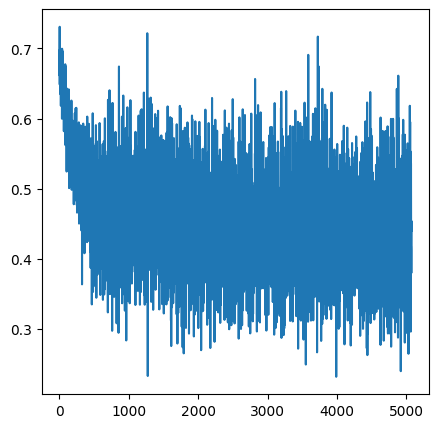

| | | | | | | | | | 

Epoch : 4 # 710
Loss: 0.4398595690727234
--------------------
| | | | | | | | | | 

Epoch : 4 # 720
Loss: 0.41754934191703796
--------------------
| | | | | | | | | | 

Epoch : 4 # 730
Loss: 0.48897719383239746
--------------------
| | | | | | | | | | 

Epoch : 4 # 740
Loss: 0.3942790627479553
--------------------
| | | | | | | | | | 

Epoch : 4 # 750
Loss: 0.5411714911460876
--------------------
| | | | | | | | | | 

Epoch : 4 # 760
Loss: 0.39284658432006836
--------------------
| | | | | | | | | | 

Epoch : 4 # 770
Loss: 0.3756856918334961
--------------------
| | | | | | | | | | 

Epoch : 4 # 780
Loss: 0.4294370412826538
--------------------
| | | | | | | | | | 

Epoch : 4 # 790
Loss: 0.41241228580474854
--------------------
| | | | | | | | | | 

Epoch : 4 # 800
Loss: 0.4897283911705017
--------------------


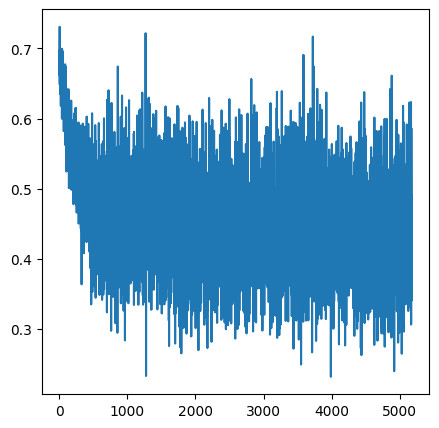

| | | | | | | | | | 

Epoch : 4 # 810
Loss: 0.37540632486343384
--------------------
| | | | | | | | | | 

Epoch : 4 # 820
Loss: 0.5200069546699524
--------------------
| | | | | | | | | | 

Epoch : 4 # 830
Loss: 0.43240541219711304
--------------------
| | | | | | | | | | 

Epoch : 4 # 840
Loss: 0.47497376799583435
--------------------
| | | | | | | | | | 

Epoch : 4 # 850
Loss: 0.42037543654441833
--------------------
| | | | | | | | | | 

Epoch : 4 # 860
Loss: 0.5096494555473328
--------------------
| | | | | | | | | | 

Epoch : 4 # 870
Loss: 0.523963451385498
--------------------
| | | | | | | | | | 

Epoch : 4 # 880
Loss: 0.3880685567855835
--------------------
| | | | | | | | | | 

Epoch : 4 # 890
Loss: 0.4041942358016968
--------------------
| | | | | | | | | | 

Epoch : 4 # 900
Loss: 0.3708135485649109
--------------------


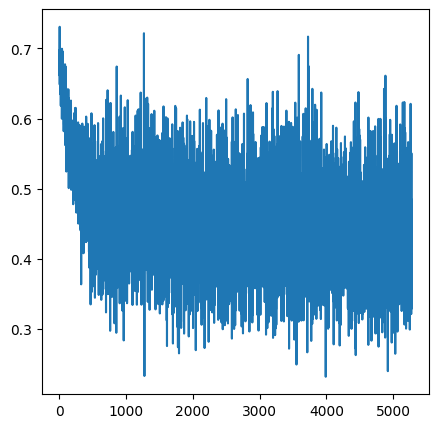

| | | | | | | | | | 

Epoch : 4 # 910
Loss: 0.3696643114089966
--------------------
| | | | | | | | | | 

Epoch : 4 # 920
Loss: 0.40006595849990845
--------------------
| | | | | | | | | | 

Epoch : 4 # 930
Loss: 0.49471738934516907
--------------------
| | | | | | | | | | 

Epoch : 4 # 940
Loss: 0.4403129816055298
--------------------
| | | | | | | | | | 

Epoch : 4 # 950
Loss: 0.39857882261276245
--------------------
| | | | | | | | | | 

Epoch : 4 # 960
Loss: 0.4931095242500305
--------------------
| | | | | | | | | | 

Epoch : 4 # 970
Loss: 0.39494478702545166
--------------------
| | | | | | | | | | 

Epoch : 4 # 980
Loss: 0.3440072536468506
--------------------
| | | | | | | | | | 

Epoch : 4 # 990
Loss: 0.5357236266136169
--------------------
| | | | | | | | | | 

Epoch : 4 # 1000
Loss: 0.4136941432952881
--------------------


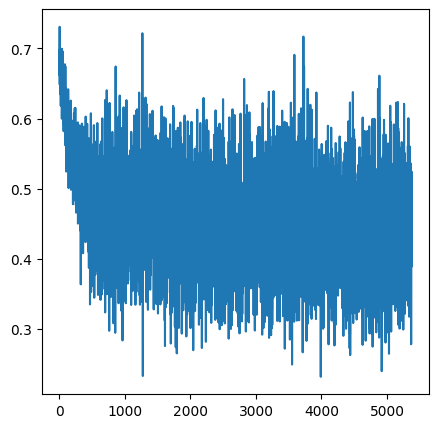

| | | | | | | | | | 

Epoch : 4 # 1010
Loss: 0.4676269292831421
--------------------
| | | | | | | | | | 

Epoch : 4 # 1020
Loss: 0.4574602246284485
--------------------
| | | | | | | | | | 

Epoch : 4 # 1030
Loss: 0.4218950569629669
--------------------
| | | | | | | | | | 

Epoch : 4 # 1040
Loss: 0.3383333683013916
--------------------
| | | | | | | | | | 

Epoch : 4 # 1050
Loss: 0.33634668588638306
--------------------
| | | | | | | | | | 

Epoch : 4 # 1060
Loss: 0.5032508373260498
--------------------
| | | | | | | | | | 

Epoch : 4 # 1070
Loss: 0.33898037672042847
--------------------
| | | | | | | | | | 

Epoch : 4 # 1080
Loss: 0.32411330938339233
--------------------
| | | | | | | | | | 

Epoch : 4 # 1090
Loss: 0.3825922906398773
--------------------
| | | | --------------------
Epoch#4
Accuracy : 0.8026114702224731
F1 Score : 0.7450220584869385
AUC-ROC : 0.8730536699295044
Specificity : 0.8649349808692932
Recall : 0.7112254500389099
ECE : 0.011615982237750334
------------------

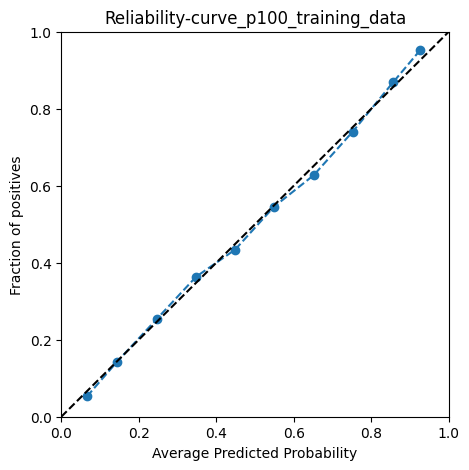

In [ ]:
epochs=5
loss_dict_FL={}
lossFn=nn.BCEWithLogitsLoss()
SSLEncoder.eval()
label_percentwise_metrics={}
for lp in label_percent:
    linear_DS=DT(layer_list,True,labels,p=lp)
    DL=DataLoader(
    dataset=linear_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
    )
    Final_Layer = Linear_Layer().to(device)
    optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)
    # d={}
    min_loss=None
    l=[]
    for epoch in range(epochs):
        c=0
        y_result_accumulated=torch.tensor([]).to(device)
        y_real_accumulated=torch.tensor([]).to(device)
        for x,y in DL:
            x,y=x.to(device),y.to(device)
            optimizer_FL.zero_grad()
            with torch.no_grad():
                h,_=SSLEncoder(x)

            y_result=Final_Layer(h).squeeze(1)
            loss=lossFn(y_result,y.float())
            loss.backward()
            optimizer_FL.step()
            c+=1
            y_result=torch.sigmoid(y_result)
            l.append(loss.item())
            y_result_accumulated=torch.cat([y_result_accumulated,y_result])
            y_real_accumulated=torch.cat([y_real_accumulated,y])
            if min_loss is None: min_loss=loss.item()
            print("|",end=" ")
            if(c%10==0):
                print("\n")
                print(f"Epoch : {epoch} # {c}")
                print(f"Loss: {loss.item()}")
                # metrics_display(y_real=y,y_result=y_result)
                print("-"*20)
                if(loss.item()<min_loss):
                    min_loss=loss.item()
                    addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Final_Layer_p{lp}.pth"
                    torch.save(Final_Layer.state_dict(),addr)
                if c%100==0:
                    plt.figure(figsize=(5,5))
                    plt.plot(l)
                    plt.show()
                    plt.close()
        print("-"*20)
        print(f"Epoch#{epoch}")
        metrics_display(y_real=y_real_accumulated.long(),y_result=y_result_accumulated)
        print("-"*20)

    reliability_plot(y_real=y_real_accumulated.long(),y_result=y_result_accumulated,save_img=True,title=f"Reliability-curve_p{lp}_training_data")
    loss_dict_FL[lp]=l
    label_percentwise_metrics[lp]=metrics_dict_creator(y_real=y_real_accumulated.long(),y_result=y_result_accumulated)

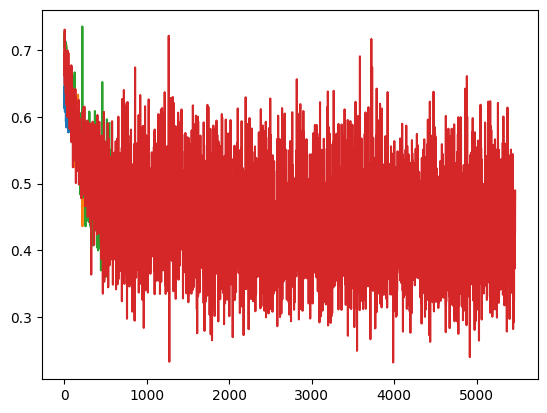

In [ ]:
plt.figure()
for lp in loss_dict_FL.keys():
    plt.plot(loss_dict_FL[lp])
plt.show()

In [ ]:
label_percentwise_metrics_df=pd.DataFrame(label_percentwise_metrics)
print(label_percentwise_metrics_df)

                                         1                                5    \
Accuracy     tensor(0.6924, device='cuda:0')  tensor(0.7997, device='cuda:0')   
F1 Score     tensor(0.3732, device='cuda:0')  tensor(0.7322, device='cuda:0')   
AUC-ROC      tensor(0.8461, device='cuda:0')  tensor(0.8609, device='cuda:0')   
Specificity  tensor(0.9790, device='cuda:0')  tensor(0.8931, device='cuda:0')   
Recall       tensor(0.2370, device='cuda:0')  tensor(0.6660, device='cuda:0')   
ECE                                 0.197828                         0.140303   

                                         10                               100  
Accuracy     tensor(0.7930, device='cuda:0')  tensor(0.8026, device='cuda:0')  
F1 Score     tensor(0.7274, device='cuda:0')  tensor(0.7450, device='cuda:0')  
AUC-ROC      tensor(0.8494, device='cuda:0')  tensor(0.8731, device='cuda:0')  
Specificity  tensor(0.8631, device='cuda:0')  tensor(0.8649, device='cuda:0')  
Recall       tensor(0.6884, devi

## Base Line Model
- Resnet trained directly without SSL training

In [ ]:
BLEncoder=Encoder().to(device)
BLFinal_Layer=Linear_Layer().to(device)
optimizer_BL=torch.optim.AdamW(itertools.chain(BLEncoder.parameters(), BLFinal_Layer.parameters()),lr=1e-5,weight_decay=1e-4)


### Baseline Model training loop

69999 images loaded successfully


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | 

Epoch : 0 # 10
Loss: 0.6240475177764893
Accuracy : 0.75
F1 Score : 0.6666666865348816
AUC-ROC : 0.8488636612892151
Specificity : 0.7272727489471436
Recall : 0.800000011920929
ECE : 0.18999330699443817
--------------------
| | | | | | | | | | 

Epoch : 0 # 20
Loss: 0.567514181137085
Accuracy : 0.78125
F1 Score : 0.774193525314331
AUC-ROC : 0.8426197171211243
Specificity : 0.7878788113594055
Recall : 0.774193525314331
ECE : 0.16922814305871725
--------------------
| | | | | | | | | | 

Epoch : 0 # 30
Loss: 0.5461279153823853
Accuracy : 0.734375
F1 Score : 0.6666666865348816
AUC-ROC : 0.8048779964447021
Specificity : 0.7317073345184326
Recall : 0.739130437374115
ECE : 0.135493203997612
--------------------
| | | | | | | | | | 

Epoch : 0 # 40
Loss: 0.5058735609054565
Accuracy : 0.796875
F1 Score : 0.7547169923782349
AUC-ROC : 0.846846878528595
Specificity : 0.837837815284729
Recall : 0.7407407164573669
ECE : 0.1207584278890863
--------------------
| | | | | | | | | |

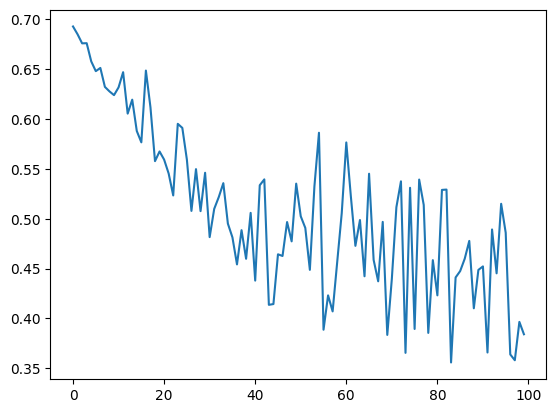

| | | | | | | | | | 

Epoch : 0 # 110
Loss: 0.5069083571434021
Accuracy : 0.796875
F1 Score : 0.7346938848495483
AUC-ROC : 0.8198380470275879
Specificity : 0.8684210777282715
Recall : 0.692307710647583
ECE : 0.11227515281643718
--------------------
| | | | | | | | | | 

Epoch : 0 # 120
Loss: 0.5270281434059143
Accuracy : 0.765625
F1 Score : 0.7272727489471436
AUC-ROC : 0.824404776096344
Specificity : 0.8055555820465088
Recall : 0.7142857313156128
ECE : 0.11054010107181966
--------------------
| | | | | | | | | | 

Epoch : 0 # 130
Loss: 0.35433584451675415
Accuracy : 0.890625
F1 Score : 0.8727272748947144
AUC-ROC : 0.9382352828979492
Specificity : 0.970588207244873
Recall : 0.800000011920929
ECE : 0.11644965270534158
--------------------
| | | | | | | | | | 

Epoch : 0 # 140
Loss: 0.4668062627315521
Accuracy : 0.765625
F1 Score : 0.6808510422706604
AUC-ROC : 0.8572874665260315
Specificity : 0.8684210777282715
Recall : 0.6153846383094788
ECE : 0.13858499459456652
--------------------
| |

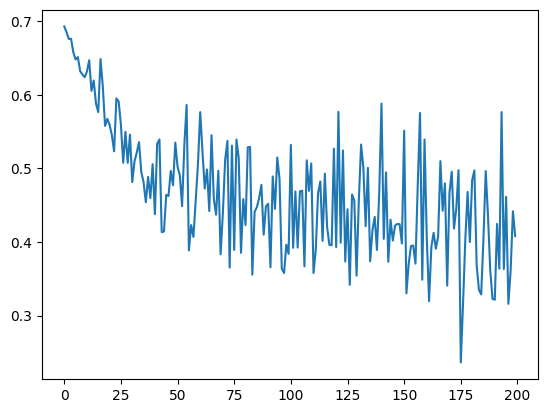

| | | | | | | | | | 

Epoch : 0 # 210
Loss: 0.487011194229126
Accuracy : 0.796875
F1 Score : 0.7636363506317139
AUC-ROC : 0.8492610454559326
Specificity : 0.8571428656578064
Recall : 0.7241379022598267
ECE : 0.15481606021057814
--------------------
| | | | | | | | | | 

Epoch : 0 # 220
Loss: 0.3656889796257019
Accuracy : 0.84375
F1 Score : 0.782608687877655
AUC-ROC : 0.9097435474395752
Specificity : 0.9230769276618958
Recall : 0.7200000286102295
ECE : 0.12408819643314928
--------------------
| | | | | | | | | | 

Epoch : 0 # 230
Loss: 0.30346718430519104
Accuracy : 0.890625
F1 Score : 0.8372092843055725
AUC-ROC : 0.9523809552192688
Specificity : 0.9285714030265808
Recall : 0.8181818127632141
ECE : 0.08585666213184595
--------------------
| | | | | | | | | | 

Epoch : 0 # 240
Loss: 0.4902243912220001
Accuracy : 0.75
F1 Score : 0.6521739363670349
AUC-ROC : 0.8282078504562378
Specificity : 0.8048780560493469
Recall : 0.6521739363670349
ECE : 0.12222083314554766
--------------------
| | | 

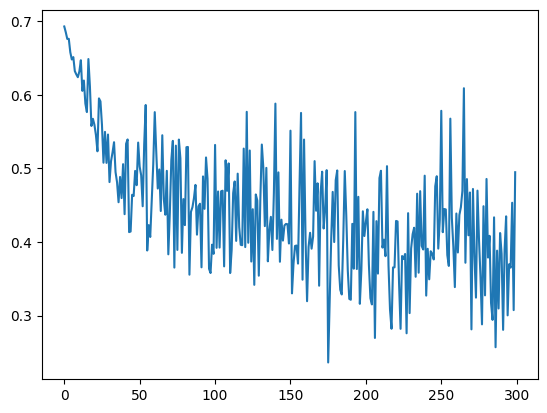

| | | | | | | | | | 

Epoch : 0 # 310
Loss: 0.5083625316619873
Accuracy : 0.75
F1 Score : 0.692307710647583
AUC-ROC : 0.8453201651573181
Specificity : 0.8571428656578064
Recall : 0.6206896305084229
ECE : 0.08986006554914638
--------------------
| | | | | | | | | | 

Epoch : 0 # 320
Loss: 0.27479395270347595
Accuracy : 0.890625
F1 Score : 0.8372092843055725
AUC-ROC : 0.9724284410476685
Specificity : 0.9512194991111755
Recall : 0.782608687877655
ECE : 0.13268547446932644
--------------------
| | | | | | | | | | 

Epoch : 0 # 330
Loss: 0.406363844871521
Accuracy : 0.84375
F1 Score : 0.800000011920929
AUC-ROC : 0.882882833480835
Specificity : 0.9189189076423645
Recall : 0.7407407164573669
ECE : 0.10878574842354283
--------------------
| | | | | | | | | | 

Epoch : 0 # 340
Loss: 0.2709304690361023
Accuracy : 0.890625
F1 Score : 0.8771929740905762
AUC-ROC : 0.9745097756385803
Specificity : 0.9411764740943909
Recall : 0.8333333134651184
ECE : 0.10314372088760138
--------------------
| | | | |

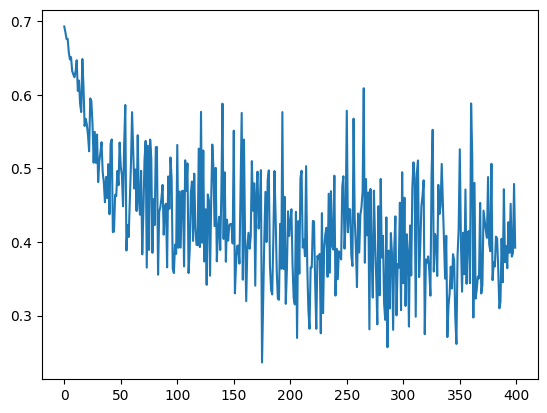

| | | | | | | | | | 

Epoch : 0 # 410
Loss: 0.37899327278137207
Accuracy : 0.859375
F1 Score : 0.7804877758026123
AUC-ROC : 0.9102272987365723
Specificity : 0.8863636255264282
Recall : 0.800000011920929
ECE : 0.11715674423612654
--------------------
| | | | | | | | | | 

Epoch : 0 # 420
Loss: 0.418240487575531
Accuracy : 0.8125
F1 Score : 0.75
AUC-ROC : 0.8802083134651184
Specificity : 0.8500000238418579
Recall : 0.75
ECE : 0.0881488905288279
--------------------
| | | | | | | | | | 

Epoch : 0 # 430
Loss: 0.38711273670196533
Accuracy : 0.828125
F1 Score : 0.7555555701255798
AUC-ROC : 0.8859357833862305
Specificity : 0.8372092843055725
Recall : 0.8095238208770752
ECE : 0.09926970856031403
--------------------
| | | | | | | | | | 

Epoch : 0 # 440
Loss: 0.41141682863235474
Accuracy : 0.796875
F1 Score : 0.7234042286872864
AUC-ROC : 0.8874459266662598
Specificity : 0.8095238208770752
Recall : 0.7727272510528564
ECE : 0.11500586336478591
--------------------
| | | | | | | | | | 

Epoch : 

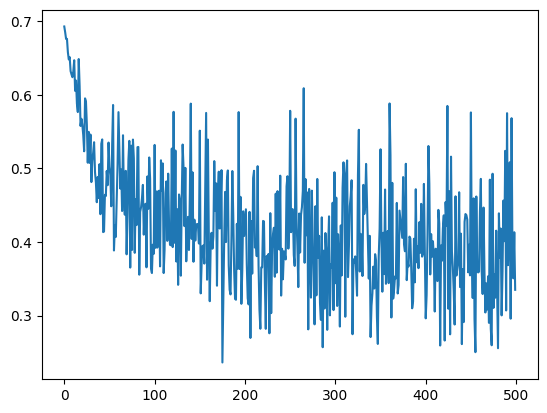

| | | | | | | | | | 

Epoch : 0 # 510
Loss: 0.4522985816001892
Accuracy : 0.8125
F1 Score : 0.739130437374115
AUC-ROC : 0.8520833253860474
Specificity : 0.875
Recall : 0.7083333134651184
ECE : 0.1265697507187724
--------------------
| | | | | | | | | | 

Epoch : 0 # 520
Loss: 0.3060078024864197
Accuracy : 0.84375
F1 Score : 0.7727272510528564
AUC-ROC : 0.9533404111862183
Specificity : 0.9024389982223511
Recall : 0.739130437374115
ECE : 0.11393746954854578
--------------------
| | | | | | | | | | 

Epoch : 0 # 530
Loss: 0.3792771100997925
Accuracy : 0.8125
F1 Score : 0.739130437374115
AUC-ROC : 0.923160195350647
Specificity : 0.8333333134651184
Recall : 0.7727272510528564
ECE : 0.11301789799472317
--------------------
| | | | | | | | | | 

Epoch : 0 # 540
Loss: 0.31131938099861145
Accuracy : 0.890625
F1 Score : 0.8444444537162781
AUC-ROC : 0.9405127763748169
Specificity : 0.9743589758872986
Recall : 0.7599999904632568
ECE : 0.1097023906186223
--------------------
| | | | | | | | | | 

E

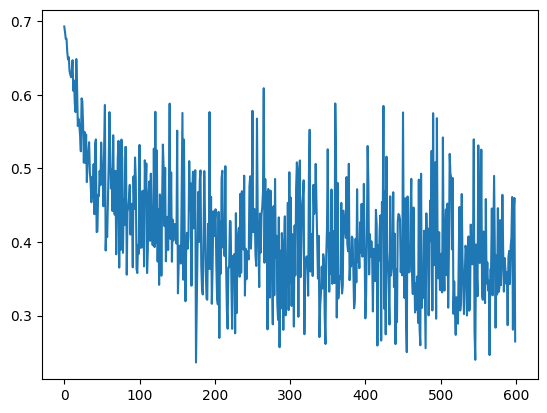

| | | | | | | | | | 

Epoch : 0 # 610
Loss: 0.3829610049724579
Accuracy : 0.84375
F1 Score : 0.761904776096344
AUC-ROC : 0.8970099687576294
Specificity : 0.8837209343910217
Recall : 0.761904776096344
ECE : 0.09991292195627466
--------------------
| | | | | | | | | | 

Epoch : 0 # 620
Loss: 0.3854433000087738
Accuracy : 0.796875
F1 Score : 0.7719298005104065
AUC-ROC : 0.9078431129455566
Specificity : 0.8529411554336548
Recall : 0.7333333492279053
ECE : 0.09332985454238951
--------------------
| | | | | | | | | | 

Epoch : 0 # 630
Loss: 0.39362189173698425
Accuracy : 0.828125
F1 Score : 0.800000011920929
AUC-ROC : 0.9061583280563354
Specificity : 0.939393937587738
Recall : 0.7096773982048035
ECE : 0.13165517919696867
--------------------
| | | | | | | | | | 

Epoch : 0 # 640
Loss: 0.34928393363952637
Accuracy : 0.8125
F1 Score : 0.7272727489471436
AUC-ROC : 0.9242424368858337
Specificity : 0.8571428656578064
Recall : 0.7272727489471436
ECE : 0.12597288226243109
--------------------
| | |

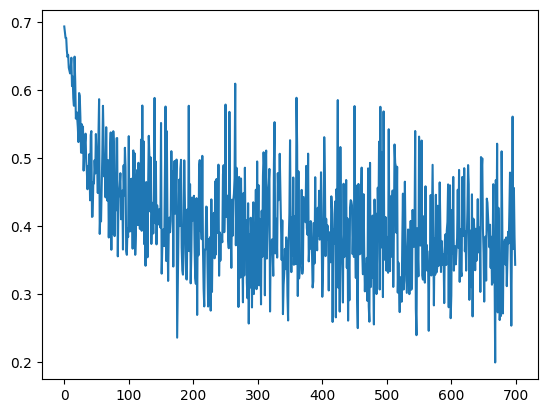

| | | | | | | | | | 

Epoch : 0 # 710
Loss: 0.44667601585388184
Accuracy : 0.765625
F1 Score : 0.6511628031730652
AUC-ROC : 0.8636363744735718
Specificity : 0.7954545617103577
Recall : 0.699999988079071
ECE : 0.10917220707051456
--------------------
| | | | | | | | | | 

Epoch : 0 # 720
Loss: 0.3087131977081299
Accuracy : 0.875
F1 Score : 0.8181818127632141
AUC-ROC : 0.9307359457015991
Specificity : 0.9047619104385376
Recall : 0.8181818127632141
ECE : 0.10317252669483423
--------------------
| | | | | | | | | | 

Epoch : 0 # 730
Loss: 0.4471246302127838
Accuracy : 0.765625
F1 Score : 0.7169811129570007
AUC-ROC : 0.8935960531234741
Specificity : 0.8571428656578064
Recall : 0.6551724076271057
ECE : 0.12241860979702324
--------------------
| | | | | | | | | | 

Epoch : 0 # 740
Loss: 0.3467606008052826
Accuracy : 0.859375
F1 Score : 0.7906976938247681
AUC-ROC : 0.9199134111404419
Specificity : 0.9047619104385376
Recall : 0.7727272510528564
ECE : 0.08353390172123909
--------------------
| |

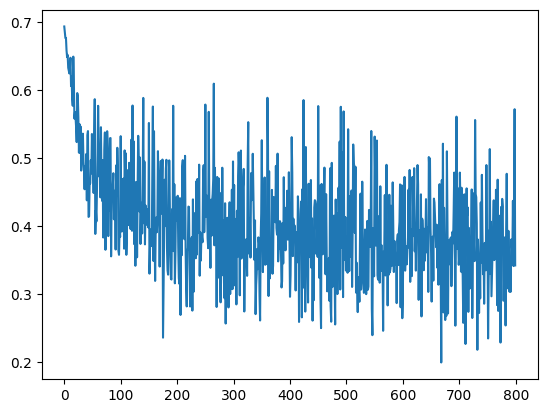

| | | | | | | | | | 

Epoch : 0 # 810
Loss: 0.27640146017074585
Accuracy : 0.859375
F1 Score : 0.8085106611251831
AUC-ROC : 0.9635416269302368
Specificity : 0.8999999761581421
Recall : 0.7916666865348816
ECE : 0.11516746314009652
--------------------
| | | | | | | | | | 

Epoch : 0 # 820
Loss: 0.2910923361778259
Accuracy : 0.875
F1 Score : 0.7894737124443054
AUC-ROC : 0.9333332777023315
Specificity : 0.9111111164093018
Recall : 0.7894737124443054
ECE : 0.08435437269508839
--------------------
| | | | | | | | | | 

Epoch : 0 # 830
Loss: 0.2990511953830719
Accuracy : 0.875
F1 Score : 0.8095238208770752
AUC-ROC : 0.9477273225784302
Specificity : 0.8863636255264282
Recall : 0.8500000238418579
ECE : 0.12864178873132914
--------------------
| | | | | | | | | | 

Epoch : 0 # 840
Loss: 0.3402966856956482
Accuracy : 0.828125
F1 Score : 0.7755101919174194
AUC-ROC : 0.9259259700775146
Specificity : 0.9189189076423645
Recall : 0.7037037014961243
ECE : 0.0819467268884182
--------------------
| | | 

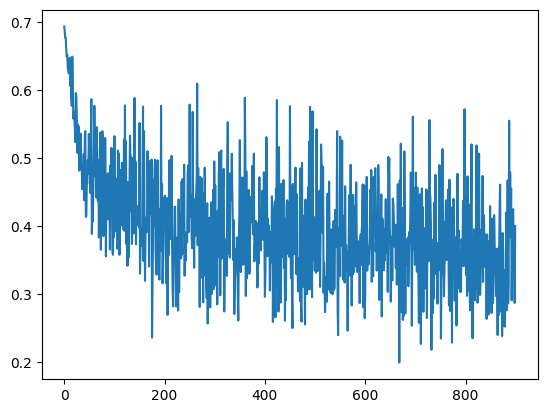

| | | | | | | | | | 

Epoch : 0 # 910
Loss: 0.39012446999549866
Accuracy : 0.8125
F1 Score : 0.8064516186714172
AUC-ROC : 0.9235293865203857
Specificity : 0.8999999761581421
Recall : 0.7352941036224365
ECE : 0.15696434793062508
--------------------
| | | | | | | | | | 

Epoch : 0 # 920
Loss: 0.3332129716873169
Accuracy : 0.828125
F1 Score : 0.7555555701255798
AUC-ROC : 0.9473683834075928
Specificity : 0.9473684430122375
Recall : 0.6538461446762085
ECE : 0.1368173457449302
--------------------
| | | | | | | | | | 

Epoch : 0 # 930
Loss: 0.3799550533294678
Accuracy : 0.84375
F1 Score : 0.8275862336158752
AUC-ROC : 0.9393939971923828
Specificity : 0.9677419066429138
Recall : 0.7272727489471436
ECE : 0.12388340663164854
--------------------
| | | | | | | | | | 

Epoch : 0 # 940
Loss: 0.2725640833377838
Accuracy : 0.921875
F1 Score : 0.8780487775802612
AUC-ROC : 0.968181848526001
Specificity : 0.9318181872367859
Recall : 0.8999999761581421
ECE : 0.09560341446194798
--------------------
| | 

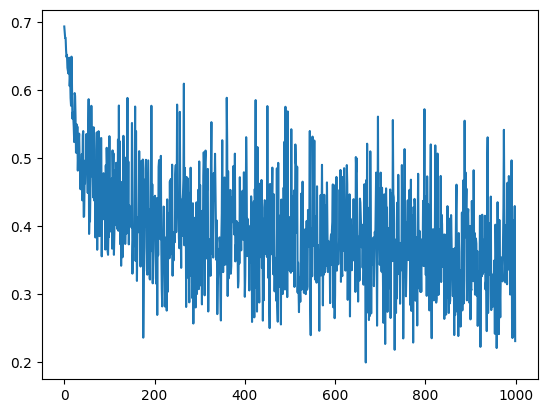

| | | | | | | | | | 

Epoch : 0 # 1010
Loss: 0.3052460849285126
Accuracy : 0.875
F1 Score : 0.8399999737739563
AUC-ROC : 0.9437963962554932
Specificity : 0.8536585569381714
Recall : 0.9130434989929199
ECE : 0.11087418941315264
--------------------
| | | | | | | | | | 

Epoch : 0 # 1020
Loss: 0.2321932315826416
Accuracy : 0.921875
F1 Score : 0.8979591727256775
AUC-ROC : 0.9743589162826538
Specificity : 0.9487179517745972
Recall : 0.8799999952316284
ECE : 0.09919442888349295
--------------------
| | | | | | | | | | 

Epoch : 0 # 1030
Loss: 0.4006449580192566
Accuracy : 0.84375
F1 Score : 0.8275862336158752
AUC-ROC : 0.9237537384033203
Specificity : 0.9677419066429138
Recall : 0.7272727489471436
ECE : 0.14004745753481984
--------------------
| | | | | | | | | | 

Epoch : 0 # 1040
Loss: 0.37120330333709717
Accuracy : 0.796875
F1 Score : 0.7547169923782349
AUC-ROC : 0.9068825840950012
Specificity : 0.8157894611358643
Recall : 0.7692307829856873
ECE : 0.10080328211188316
--------------------

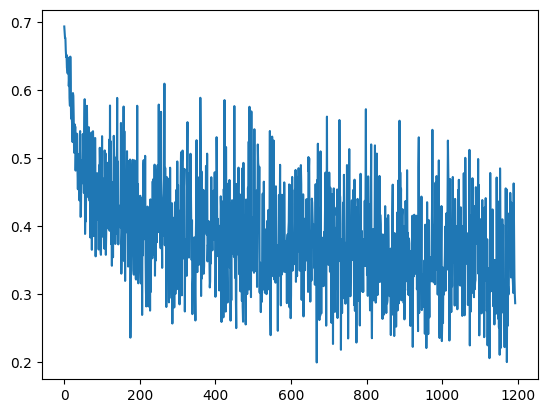

| | | | | | | | | | 

Epoch : 1 # 110
Loss: 0.3684100806713104
Accuracy : 0.8125
F1 Score : 0.7272727489471436
AUC-ROC : 0.9078947305679321
Specificity : 0.9473684430122375
Recall : 0.6153846383094788
ECE : 0.05594382691197097
--------------------
| | | | | | | | | | 

Epoch : 1 # 120
Loss: 0.4933551549911499
Accuracy : 0.796875
F1 Score : 0.7346938848495483
AUC-ROC : 0.8553845882415771
Specificity : 0.8461538553237915
Recall : 0.7200000286102295
ECE : 0.07588173355907202
--------------------
| | | | | | | | | | 

Epoch : 1 # 130
Loss: 0.2653422951698303
Accuracy : 0.890625
F1 Score : 0.8727272748947144
AUC-ROC : 0.9655172824859619
Specificity : 0.9428571462631226
Recall : 0.8275862336158752
ECE : 0.09237086813664064
--------------------
| | | | | | | | | | 

Epoch : 1 # 140
Loss: 0.42755720019340515
Accuracy : 0.78125
F1 Score : 0.7666666507720947
AUC-ROC : 0.8941176533699036
Specificity : 0.7941176295280457
Recall : 0.7666666507720947
ECE : 0.13747857377165928
--------------------
| 

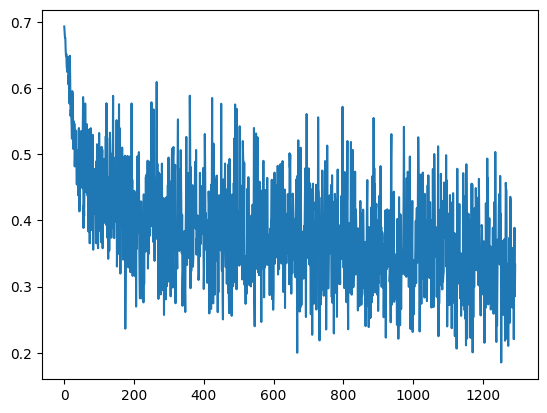

| | | | | | | | | | 

Epoch : 1 # 210
Loss: 0.4369747042655945
Accuracy : 0.78125
F1 Score : 0.7200000286102295
AUC-ROC : 0.8886639475822449
Specificity : 0.8421052694320679
Recall : 0.692307710647583
ECE : 0.11132484581321478
--------------------
| | | | | | | | | | 

Epoch : 1 # 220
Loss: 0.3189360499382019
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9395833611488342
Specificity : 0.925000011920929
Recall : 0.8333333134651184
ECE : 0.07907789910677822
--------------------
| | | | | | | | | | 

Epoch : 1 # 230
Loss: 0.32571011781692505
Accuracy : 0.84375
F1 Score : 0.8148148059844971
AUC-ROC : 0.9352226853370667
Specificity : 0.8421052694320679
Recall : 0.8461538553237915
ECE : 0.06955817033303902
--------------------
| | | | | | | | | | 

Epoch : 1 # 240
Loss: 0.2598210573196411
Accuracy : 0.921875
F1 Score : 0.8936170339584351
AUC-ROC : 0.9630768299102783
Specificity : 0.9743589758872986
Recall : 0.8399999737739563
ECE : 0.07462573680095375
--------------------
| |

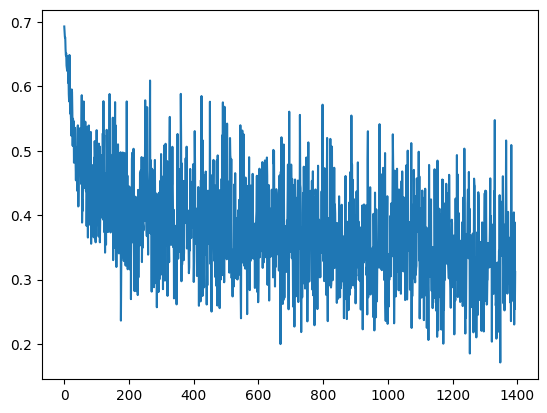

| | | | | | | | | | 

Epoch : 1 # 310
Loss: 0.36624789237976074
Accuracy : 0.875
F1 Score : 0.8399999737739563
AUC-ROC : 0.911794900894165
Specificity : 0.8974359035491943
Recall : 0.8399999737739563
ECE : 0.07717837020754814
--------------------
| | | | | | | | | | 

Epoch : 1 # 320
Loss: 0.2672930955886841
Accuracy : 0.9375
F1 Score : 0.9166666865348816
AUC-ROC : 0.97510826587677
Specificity : 0.9047619104385376
Recall : 1.0
ECE : 0.14894047268899158
--------------------
| | | | | | | | | | 

Epoch : 1 # 330
Loss: 0.3503020405769348
Accuracy : 0.84375
F1 Score : 0.800000011920929
AUC-ROC : 0.9379844665527344
Specificity : 0.7906976938247681
Recall : 0.9523809552192688
ECE : 0.11969156027771533
--------------------
| | | | | | | | | | 

Epoch : 1 # 340
Loss: 0.24021488428115845
Accuracy : 0.90625
F1 Score : 0.8999999761581421
AUC-ROC : 0.974609375
Specificity : 0.96875
Recall : 0.84375
ECE : 0.094613793422468
--------------------
| | | | | | | | | | 

Epoch : 1 # 350
Loss: 0.268734514

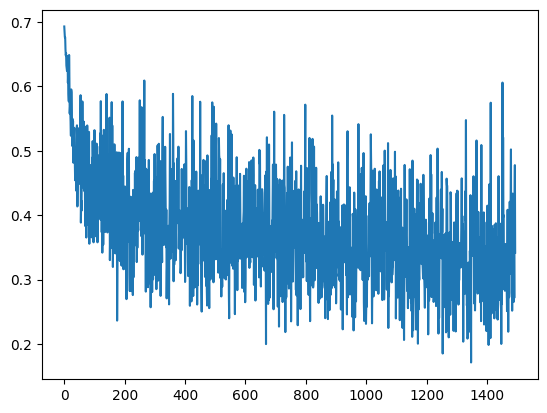

| | | | | | | | | | 

Epoch : 1 # 410
Loss: 0.33789223432540894
Accuracy : 0.859375
F1 Score : 0.8085106611251831
AUC-ROC : 0.922587513923645
Specificity : 0.8780487775802612
Recall : 0.8260869383811951
ECE : 0.1034897654899396
--------------------
| | | | | | | | | | 

Epoch : 1 # 420
Loss: 0.3154529333114624
Accuracy : 0.890625
F1 Score : 0.8771929740905762
AUC-ROC : 0.9384920597076416
Specificity : 0.8888888955116272
Recall : 0.8928571343421936
ECE : 0.05135673051699995
--------------------
| | | | | | | | | | 

Epoch : 1 # 430
Loss: 0.2472691535949707
Accuracy : 0.90625
F1 Score : 0.8846153616905212
AUC-ROC : 0.9753694534301758
Specificity : 1.0
Recall : 0.7931034564971924
ECE : 0.10878993105143309
--------------------
| | | | | | | | | | 

Epoch : 1 # 440
Loss: 0.29580551385879517
Accuracy : 0.875
F1 Score : 0.8260869383811951
AUC-ROC : 0.9437963962554932
Specificity : 0.9024389982223511
Recall : 0.8260869383811951
ECE : 0.07564996252767742
--------------------
| | | | | | | | | |

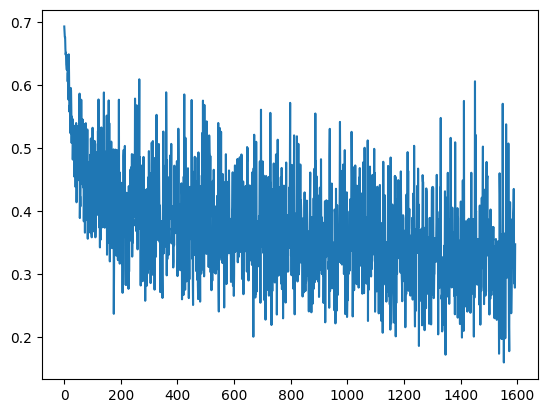

| | | | | | | | | | 

Epoch : 1 # 510
Loss: 0.23252566158771515
Accuracy : 0.921875
F1 Score : 0.8888888955116272
AUC-ROC : 0.9522799849510193
Specificity : 0.9512194991111755
Recall : 0.8695651888847351
ECE : 0.07136585342232138
--------------------
| | | | | | | | | | 

Epoch : 1 # 520
Loss: 0.31651240587234497
Accuracy : 0.875
F1 Score : 0.8461538553237915
AUC-ROC : 0.9311740398406982
Specificity : 0.8947368264198303
Recall : 0.8461538553237915
ECE : 0.0835894366609864
--------------------
| | | | | | | | | | 

Epoch : 1 # 530
Loss: 0.36926376819610596
Accuracy : 0.875
F1 Score : 0.8461538553237915
AUC-ROC : 0.9114583730697632
Specificity : 0.8500000238418579
Recall : 0.9166666865348816
ECE : 0.1303666103631258
--------------------
| | | | | | | | | | 

Epoch : 1 # 540
Loss: 0.21318084001541138
Accuracy : 0.9375
F1 Score : 0.9200000166893005
AUC-ROC : 0.9833333492279053
Specificity : 0.925000011920929
Recall : 0.9583333134651184
ECE : 0.09876917232759297
--------------------
| | | |

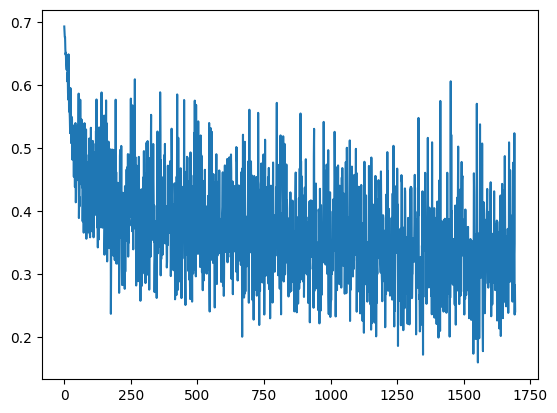

| | | | | | | | | | 

Epoch : 1 # 610
Loss: 0.5967379808425903
Accuracy : 0.796875
F1 Score : 0.7796609997749329
AUC-ROC : 0.8201367855072021
Specificity : 0.8484848737716675
Recall : 0.7419354915618896
ECE : 0.17132033384405077
--------------------
| | | | | | | | | | 

Epoch : 1 # 620
Loss: 0.2879917025566101
Accuracy : 0.859375
F1 Score : 0.8571428656578064
AUC-ROC : 0.9832512140274048
Specificity : 0.9655172228813171
Recall : 0.7714285850524902
ECE : 0.14623728371225297
--------------------
| | | | | | | | | | 

Epoch : 1 # 630
Loss: 0.33017265796661377
Accuracy : 0.859375
F1 Score : 0.8363636136054993
AUC-ROC : 0.9343137145042419
Specificity : 0.9411764740943909
Recall : 0.7666666507720947
ECE : 0.07543461746536195
--------------------
| | | | | | | | | | 

Epoch : 1 # 640
Loss: 0.21519604325294495
Accuracy : 0.921875
F1 Score : 0.9019607901573181
AUC-ROC : 0.9915164709091187
Specificity : 0.8780487775802612
Recall : 1.0
ECE : 0.12483754428103566
--------------------
| | | | | | |

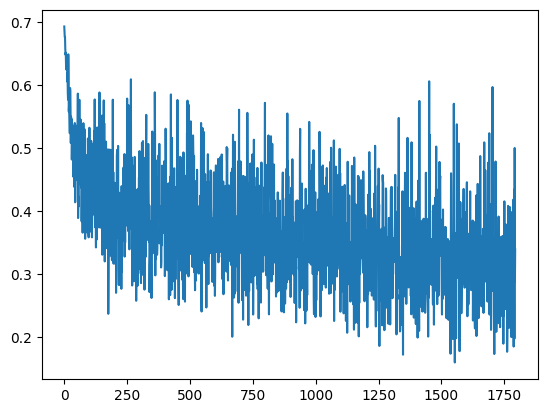

| | | | | | | | | | 

Epoch : 1 # 710
Loss: 0.3169228434562683
Accuracy : 0.890625
F1 Score : 0.8571428656578064
AUC-ROC : 0.945641040802002
Specificity : 0.9230769276618958
Recall : 0.8399999737739563
ECE : 0.14580003474839032
--------------------
| | | | | | | | | | 

Epoch : 1 # 720
Loss: 0.3563684821128845
Accuracy : 0.859375
F1 Score : 0.8163265585899353
AUC-ROC : 0.926406979560852
Specificity : 0.8333333134651184
Recall : 0.9090909361839294
ECE : 0.0964604212786071
--------------------
| | | | | | | | | | 

Epoch : 1 # 730
Loss: 0.23210716247558594
Accuracy : 0.90625
F1 Score : 0.8695651888847351
AUC-ROC : 0.9651282429695129
Specificity : 0.9743589758872986
Recall : 0.800000011920929
ECE : 0.06778845569351688
--------------------
| | | | | | | | | | 

Epoch : 1 # 740
Loss: 0.22169099748134613
Accuracy : 0.90625
F1 Score : 0.8799999952316284
AUC-ROC : 0.9783549308776855
Specificity : 0.8571428656578064
Recall : 1.0
ECE : 0.07043934462126344
--------------------
| | | | | | | | | |

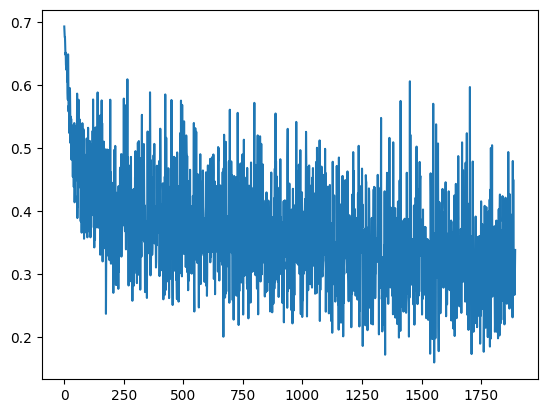

| | | | | | | | | | 

Epoch : 1 # 810
Loss: 0.35093459486961365
Accuracy : 0.859375
F1 Score : 0.7804877758026123
AUC-ROC : 0.9204678535461426
Specificity : 0.8666666746139526
Recall : 0.8421052694320679
ECE : 0.12155744654592127
--------------------
| | | | | | | | | | 

Epoch : 1 # 820
Loss: 0.20673005282878876
Accuracy : 0.921875
F1 Score : 0.9019607901573181
AUC-ROC : 0.9819819927215576
Specificity : 0.9729729890823364
Recall : 0.8518518805503845
ECE : 0.09017906116787344
--------------------
| | | | | | | | | | 

Epoch : 1 # 830
Loss: 0.3177783787250519
Accuracy : 0.828125
F1 Score : 0.7555555701255798
AUC-ROC : 0.9333333373069763
Specificity : 0.9230769276618958
Recall : 0.6800000071525574
ECE : 0.08293456578394398
--------------------
| | | | | | | | | | 

Epoch : 1 # 840
Loss: 0.2377856969833374
Accuracy : 0.9375
F1 Score : 0.9200000166893005
AUC-ROC : 0.9766701459884644
Specificity : 0.9024389982223511
Recall : 1.0
ECE : 0.1046161288395524
--------------------
| | | | | | | | 

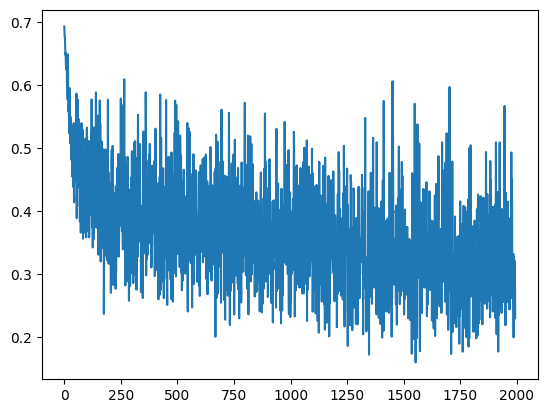

| | | | | | | | | | 

Epoch : 1 # 910
Loss: 0.34029603004455566
Accuracy : 0.84375
F1 Score : 0.800000011920929
AUC-ROC : 0.9315476417541504
Specificity : 0.9444444179534912
Recall : 0.7142857313156128
ECE : 0.10030580242164433
--------------------
| | | | | | | | | | 

Epoch : 1 # 920
Loss: 0.27203264832496643
Accuracy : 0.84375
F1 Score : 0.807692289352417
AUC-ROC : 0.9724137783050537
Specificity : 0.9428571462631226
Recall : 0.7241379022598267
ECE : 0.09093946637585759
--------------------
| | | | | | | | | | 

Epoch : 1 # 930
Loss: 0.25503551959991455
Accuracy : 0.859375
F1 Score : 0.8301886916160583
AUC-ROC : 0.9725490212440491
Specificity : 0.970588207244873
Recall : 0.7333333492279053
ECE : 0.11498914245748892
--------------------
| | | | | | | | | | 

Epoch : 1 # 940
Loss: 0.21128106117248535
Accuracy : 0.921875
F1 Score : 0.9019607901573181
AUC-ROC : 0.9805128574371338
Specificity : 0.9230769276618958
Recall : 0.9200000166893005
ECE : 0.08362281927838922
--------------------
|

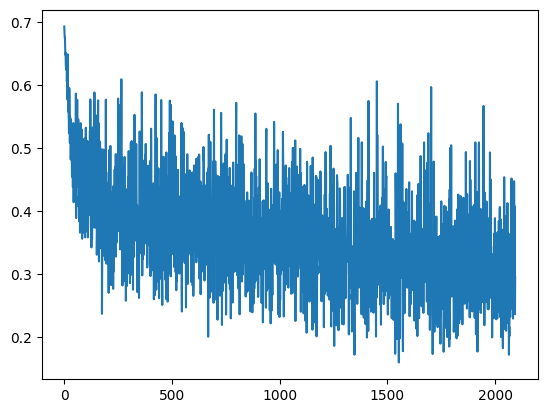

| | | | | | | | | | 

Epoch : 1 # 1010
Loss: 0.20807887613773346
Accuracy : 0.953125
F1 Score : 0.9333333373069763
AUC-ROC : 0.9713680148124695
Specificity : 0.9756097793579102
Recall : 0.9130434989929199
ECE : 0.08349998202174902
--------------------
| | | | | | | | | | 

Epoch : 1 # 1020
Loss: 0.3412506580352783
Accuracy : 0.828125
F1 Score : 0.7755101919174194
AUC-ROC : 0.9355158805847168
Specificity : 0.9444444179534912
Recall : 0.6785714030265808
ECE : 0.10676451888866723
--------------------
| | | | | | | | | | 

Epoch : 1 # 1030
Loss: 0.37888431549072266
Accuracy : 0.796875
F1 Score : 0.7234042286872864
AUC-ROC : 0.922806978225708
Specificity : 0.7555555701255798
Recall : 0.8947368264198303
ECE : 0.15673075942322612
--------------------
| | | | | | | | | | 

Epoch : 1 # 1040
Loss: 0.2154131382703781
Accuracy : 0.9375
F1 Score : 0.9375
AUC-ROC : 0.9755859375
Specificity : 0.9375
Recall : 0.9375
ECE : 0.0857235899893567
--------------------
| | | | | | | | | | 

Epoch : 1 # 1050
L

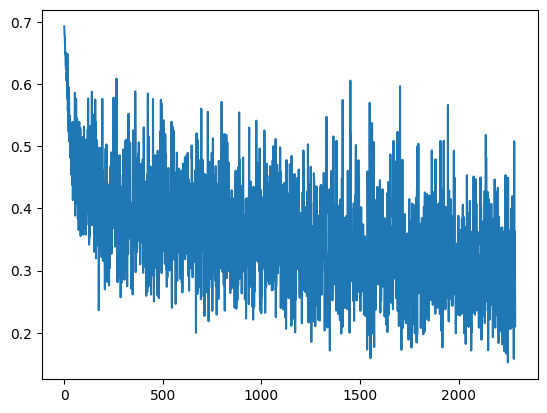

| | | | | | | | | | 

Epoch : 2 # 110
Loss: 0.2967895269393921
Accuracy : 0.890625
F1 Score : 0.8813559412956238
AUC-ROC : 0.95703125
Specificity : 0.96875
Recall : 0.8125
ECE : 0.09353848430328071
--------------------
| | | | | | | | | | 

Epoch : 2 # 120
Loss: 0.24136883020401
Accuracy : 0.890625
F1 Score : 0.8571428656578064
AUC-ROC : 0.962051272392273
Specificity : 0.9230769276618958
Recall : 0.8399999737739563
ECE : 0.11485083075240254
--------------------
| | | | | | | | | | 

Epoch : 2 # 130
Loss: 0.3917907476425171
Accuracy : 0.859375
F1 Score : 0.800000011920929
AUC-ROC : 0.8992248177528381
Specificity : 0.8604651093482971
Recall : 0.8571428656578064
ECE : 0.1030893111601472
--------------------
| | | | | | | | | | 

Epoch : 2 # 140
Loss: 0.335978239774704
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9166666865348816
Specificity : 0.8809523582458496
Recall : 0.9090909361839294
ECE : 0.12503461085725576
--------------------
| | | | | | | | | | 

Epoch : 2 # 150

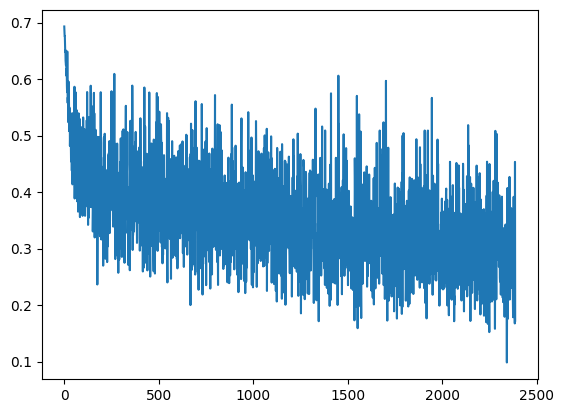

| | | | | | | | | | 

Epoch : 2 # 210
Loss: 0.26418402791023254
Accuracy : 0.859375
F1 Score : 0.8235294222831726
AUC-ROC : 0.9624999761581421
Specificity : 0.8500000238418579
Recall : 0.875
ECE : 0.0834143552929163
--------------------
| | | | | | | | | | 

Epoch : 2 # 220
Loss: 0.3654783368110657
Accuracy : 0.8125
F1 Score : 0.7777777910232544
AUC-ROC : 0.9254902005195618
Specificity : 0.9117646813392639
Recall : 0.699999988079071
ECE : 0.13311904954025522
--------------------
| | | | | | | | | | 

Epoch : 2 # 230
Loss: 0.287354052066803
Accuracy : 0.84375
F1 Score : 0.800000011920929
AUC-ROC : 0.9499499201774597
Specificity : 0.9189189076423645
Recall : 0.7407407164573669
ECE : 0.09736226592212915
--------------------
| | | | | | | | | | 

Epoch : 2 # 240
Loss: 0.2929983139038086
Accuracy : 0.875
F1 Score : 0.8333333134651184
AUC-ROC : 0.9321862459182739
Specificity : 0.9473684430122375
Recall : 0.7692307829856873
ECE : 0.07981827086769044
--------------------
| | | | | | | | | | 



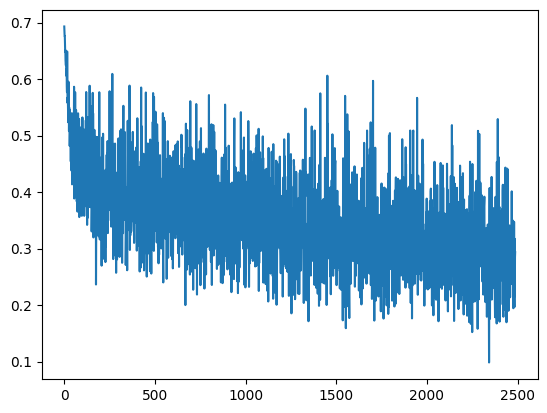

| | | | | | | | | | 

Epoch : 2 # 310
Loss: 0.3195204436779022
Accuracy : 0.859375
F1 Score : 0.8474576473236084
AUC-ROC : 0.9349753260612488
Specificity : 0.8571428656578064
Recall : 0.8620689511299133
ECE : 0.05534095951588825
--------------------
| | | | | | | | | | 

Epoch : 2 # 320
Loss: 0.27889174222946167
Accuracy : 0.875
F1 Score : 0.8333333134651184
AUC-ROC : 0.9490985870361328
Specificity : 0.8780487775802612
Recall : 0.8695651888847351
ECE : 0.08775400277227163
--------------------
| | | | | | | | | | 

Epoch : 2 # 330
Loss: 0.25819167494773865
Accuracy : 0.90625
F1 Score : 0.8799999952316284
AUC-ROC : 0.9604166746139526
Specificity : 0.8999999761581421
Recall : 0.9166666865348816
ECE : 0.10102673654910177
--------------------
| | | | | | | | | | 

Epoch : 2 # 340
Loss: 0.23476465046405792
Accuracy : 0.921875
F1 Score : 0.9122806787490845
AUC-ROC : 0.9754902124404907
Specificity : 0.970588207244873
Recall : 0.8666666746139526
ECE : 0.08654394745826721
--------------------
| 

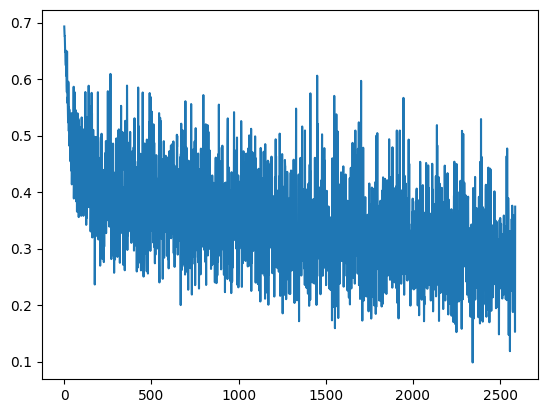

| | | | | | | | | | 

Epoch : 2 # 410
Loss: 0.3863815367221832
Accuracy : 0.828125
F1 Score : 0.8070175647735596
AUC-ROC : 0.9196078777313232
Specificity : 0.8823529481887817
Recall : 0.7666666507720947
ECE : 0.10867603670340031
--------------------
| | | | | | | | | | 

Epoch : 2 # 420
Loss: 0.27851706743240356
Accuracy : 0.875
F1 Score : 0.8333333134651184
AUC-ROC : 0.9519519805908203
Specificity : 0.9729729890823364
Recall : 0.7407407164573669
ECE : 0.06569910096004605
--------------------
| | | | | | | | | | 

Epoch : 2 # 430
Loss: 0.1315397471189499
Accuracy : 0.953125
F1 Score : 0.9387755393981934
AUC-ROC : 0.9947916269302368
Specificity : 0.949999988079071
Recall : 0.9583333134651184
ECE : 0.05535241833422333
--------------------
| | | | | | | | | | 

Epoch : 2 # 440
Loss: 0.30521857738494873
Accuracy : 0.90625
F1 Score : 0.8999999761581421
AUC-ROC : 0.9667644500732422
Specificity : 1.0
Recall : 0.8181818127632141
ECE : 0.1374446009285748
--------------------
| | | | | | | | | |

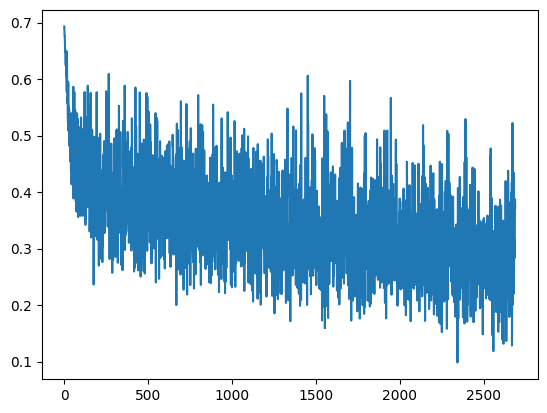

| | | | | | | | | | 

Epoch : 2 # 510
Loss: 0.23503413796424866
Accuracy : 0.875
F1 Score : 0.8095238208770752
AUC-ROC : 0.9806762933731079
Specificity : 0.8478260636329651
Recall : 0.9444444179534912
ECE : 0.14765649335458875
--------------------
| | | | | | | | | | 

Epoch : 2 # 520
Loss: 0.2621229887008667
Accuracy : 0.84375
F1 Score : 0.7916666865348816
AUC-ROC : 0.9497436285018921
Specificity : 0.8974359035491943
Recall : 0.7599999904632568
ECE : 0.10147182922810316
--------------------
| | | | | | | | | | 

Epoch : 2 # 530
Loss: 0.401276558637619
Accuracy : 0.828125
F1 Score : 0.7843137383460999
AUC-ROC : 0.9067460298538208
Specificity : 0.9166666865348816
Recall : 0.7142857313156128
ECE : 0.09600038378266618
--------------------
| | | | | | | | | | 

Epoch : 2 # 540
Loss: 0.2110990583896637
Accuracy : 0.890625
F1 Score : 0.8727272748947144
AUC-ROC : 0.9783251285552979
Specificity : 0.9428571462631226
Recall : 0.8275862336158752
ECE : 0.08275655034231022
--------------------
| | 

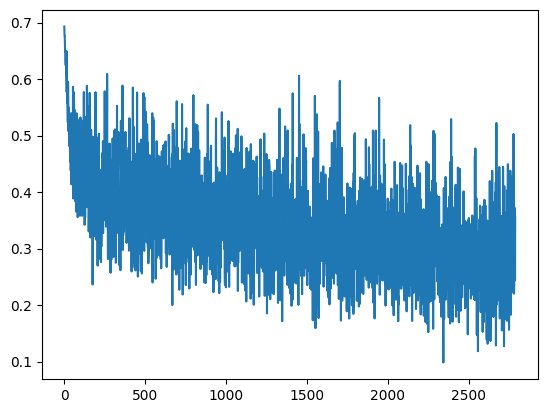

| | | | | | | | | | 

Epoch : 2 # 610
Loss: 0.2547435760498047
Accuracy : 0.859375
F1 Score : 0.8235294222831726
AUC-ROC : 0.9843137264251709
Specificity : 1.0
Recall : 0.699999988079071
ECE : 0.12137300800532103
--------------------
| | | | | | | | | | 

Epoch : 2 # 620
Loss: 0.35142403841018677
Accuracy : 0.828125
F1 Score : 0.7317073345184326
AUC-ROC : 0.931164026260376
Specificity : 0.8085106611251831
Recall : 0.8823529481887817
ECE : 0.1298509126645513
--------------------
| | | | | | | | | | 

Epoch : 2 # 630
Loss: 0.3108174800872803
Accuracy : 0.859375
F1 Score : 0.8421052694320679
AUC-ROC : 0.953125
Specificity : 0.96875
Recall : 0.75
ECE : 0.11340742302127182
--------------------
| | | | | | | | | | 

Epoch : 2 # 640
Loss: 0.326648473739624
Accuracy : 0.90625
F1 Score : 0.8928571343421936
AUC-ROC : 0.9382352828979492
Specificity : 0.970588207244873
Recall : 0.8333333134651184
ECE : 0.11983765650074929
--------------------
| | | | | | | | | | 

Epoch : 2 # 650
Loss: 0.273651093

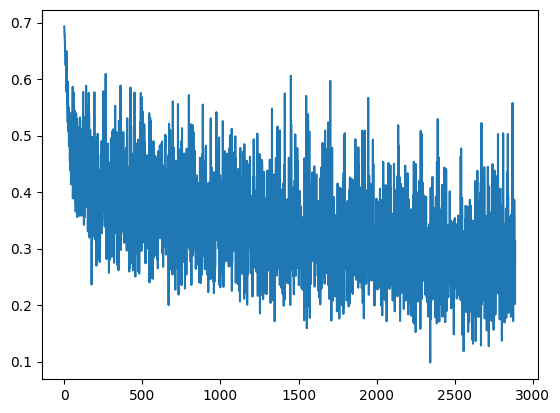

| | | | | | | | | | 

Epoch : 2 # 710
Loss: 0.3228873014450073
Accuracy : 0.875
F1 Score : 0.8518518805503845
AUC-ROC : 0.9331983923912048
Specificity : 0.8684210777282715
Recall : 0.8846153616905212
ECE : 0.09851121995598078
--------------------
| | | | | | | | | | 

Epoch : 2 # 720
Loss: 0.21431270241737366
Accuracy : 0.9375
F1 Score : 0.9230769276618958
AUC-ROC : 0.9696356058120728
Specificity : 0.9473684430122375
Recall : 0.9230769276618958
ECE : 0.06243724963860586
--------------------
| | | | | | | | | | 

Epoch : 2 # 730
Loss: 0.27848151326179504
Accuracy : 0.875
F1 Score : 0.8571428656578064
AUC-ROC : 0.954901933670044
Specificity : 0.9411764740943909
Recall : 0.800000011920929
ECE : 0.06435539352241904
--------------------
| | | | | | | | | | 

Epoch : 2 # 740
Loss: 0.23121458292007446
Accuracy : 0.90625
F1 Score : 0.8799999952316284
AUC-ROC : 0.9676113128662109
Specificity : 0.9473684430122375
Recall : 0.8461538553237915
ECE : 0.03992723789997399
--------------------
| | | | 

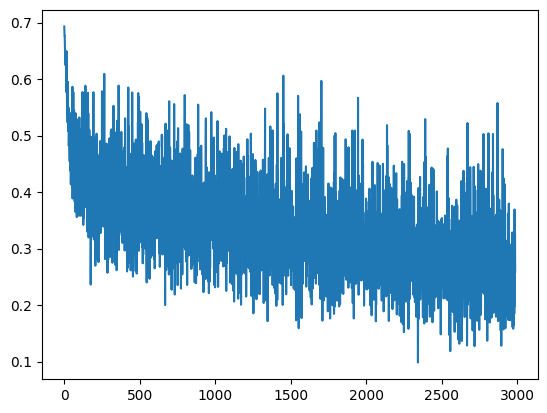

| | | | | | | | | | 

Epoch : 2 # 810
Loss: 0.29226258397102356
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9579180479049683
Specificity : 0.8604651093482971
Recall : 0.9523809552192688
ECE : 0.12403269263450056
--------------------
| | | | | | | | | | 

Epoch : 2 # 820
Loss: 0.24706093966960907
Accuracy : 0.859375
F1 Score : 0.8163265585899353
AUC-ROC : 0.9729729890823364
Specificity : 0.9459459185600281
Recall : 0.7407407164573669
ECE : 0.0961859340313822
--------------------
| | | | | | | | | | 

Epoch : 2 # 830
Loss: 0.28552913665771484
Accuracy : 0.859375
F1 Score : 0.800000011920929
AUC-ROC : 0.9437229633331299
Specificity : 0.8809523582458496
Recall : 0.8181818127632141
ECE : 0.11190704593900591
--------------------
| | | | | | | | | | 

Epoch : 2 # 840
Loss: 0.22092179954051971
Accuracy : 0.90625
F1 Score : 0.8571428656578064
AUC-ROC : 0.9801169633865356
Specificity : 0.8888888955116272
Recall : 0.9473684430122375
ECE : 0.12283861602190882
--------------------

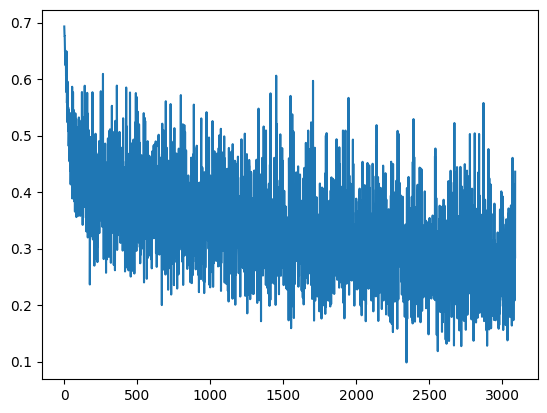

| | | | | | | | | | 

Epoch : 2 # 910
Loss: 0.3866858184337616
Accuracy : 0.859375
F1 Score : 0.800000011920929
AUC-ROC : 0.9220513105392456
Specificity : 0.9487179517745972
Recall : 0.7200000286102295
ECE : 0.08873636310454458
--------------------
| | | | | | | | | | 

Epoch : 2 # 920
Loss: 0.29663902521133423
Accuracy : 0.859375
F1 Score : 0.8474576473236084
AUC-ROC : 0.9521017074584961
Specificity : 0.9090909361839294
Recall : 0.8064516186714172
ECE : 0.06117227009963244
--------------------
| | | | | | | | | | 

Epoch : 2 # 930
Loss: 0.21982021629810333
Accuracy : 0.890625
F1 Score : 0.8571428656578064
AUC-ROC : 0.9830329418182373
Specificity : 0.8780487775802612
Recall : 0.9130434989929199
ECE : 0.09741829917766154
--------------------
| | | | | | | | | | 

Epoch : 2 # 940
Loss: 0.3186097741127014
Accuracy : 0.875
F1 Score : 0.8399999737739563
AUC-ROC : 0.9384615421295166
Specificity : 0.8974359035491943
Recall : 0.8399999737739563
ECE : 0.08994797460036352
--------------------
| 

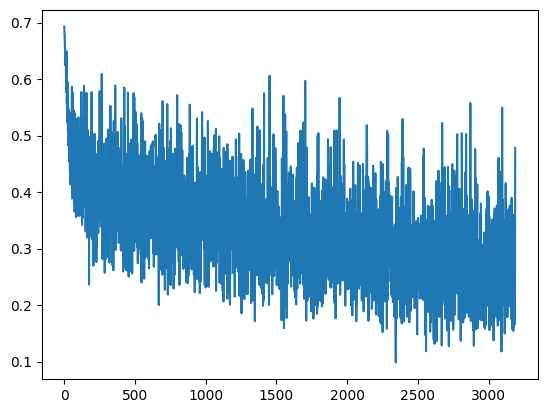

| | | | | | | | | | 

Epoch : 2 # 1010
Loss: 0.16949491202831268
Accuracy : 0.953125
F1 Score : 0.9473684430122375
AUC-ROC : 0.991176426410675
Specificity : 1.0
Recall : 0.8999999761581421
ECE : 0.07621835952159017
--------------------
| | | | | | | | | | 

Epoch : 2 # 1020
Loss: 0.15722516179084778
Accuracy : 0.9375
F1 Score : 0.9259259104728699
AUC-ROC : 0.9898785352706909
Specificity : 0.9210526347160339
Recall : 0.9615384340286255
ECE : 0.06874751066789031
--------------------
| | | | | | | | | | 

Epoch : 2 # 1030
Loss: 0.29428648948669434
Accuracy : 0.875
F1 Score : 0.8461538553237915
AUC-ROC : 0.9463562369346619
Specificity : 0.8947368264198303
Recall : 0.8461538553237915
ECE : 0.06934900651685894
--------------------
| | | | | | | | | | 

Epoch : 2 # 1040
Loss: 0.33372852206230164
Accuracy : 0.859375
F1 Score : 0.8421052694320679
AUC-ROC : 0.9411764144897461
Specificity : 0.9117646813392639
Recall : 0.800000011920929
ECE : 0.08248041721526533
--------------------
| | | | | | | 

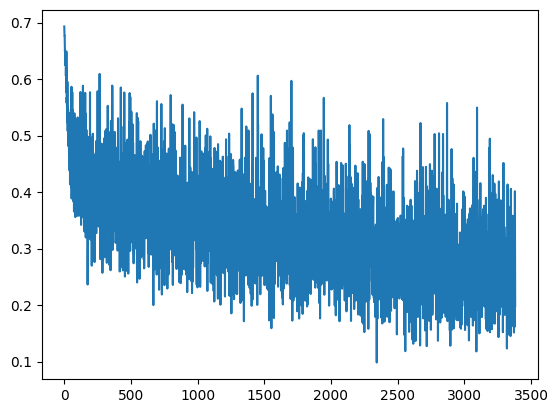

| | | | | | | | | | 

Epoch : 3 # 110
Loss: 0.22807428240776062
Accuracy : 0.953125
F1 Score : 0.9230769276618958
AUC-ROC : 0.9488636255264282
Specificity : 0.9772727489471436
Recall : 0.8999999761581421
ECE : 0.0859408131800592
--------------------
| | | | | | | | | | 

Epoch : 3 # 120
Loss: 0.1616961658000946
Accuracy : 0.96875
F1 Score : 0.95652174949646
AUC-ROC : 0.9885416030883789
Specificity : 1.0
Recall : 0.9166666865348816
ECE : 0.07875401381170377
--------------------
| | | | | | | | | | 

Epoch : 3 # 130
Loss: 0.3060652017593384
Accuracy : 0.796875
F1 Score : 0.6976743936538696
AUC-ROC : 0.9473684430122375
Specificity : 0.800000011920929
Recall : 0.7894737124443054
ECE : 0.15495006693527102
--------------------
| | | | | | | | | | 

Epoch : 3 # 140
Loss: 0.401949405670166
Accuracy : 0.8125
F1 Score : 0.7777777910232544
AUC-ROC : 0.9039039015769958
Specificity : 0.837837815284729
Recall : 0.7777777910232544
ECE : 0.106161294010235
--------------------
| | | | | | | | | | 

Epo

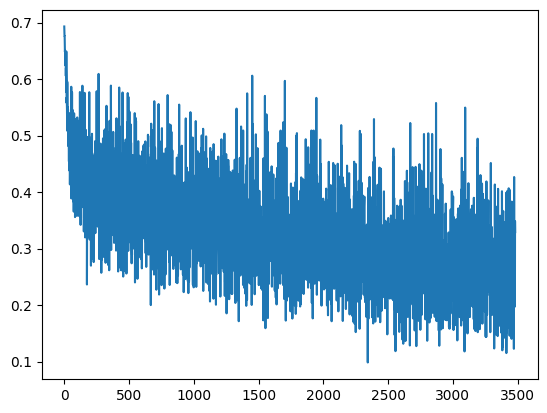

| | | | | | | | | | 

Epoch : 3 # 210
Loss: 0.2253446727991104
Accuracy : 0.9375
F1 Score : 0.9200000166893005
AUC-ROC : 0.9661538600921631
Specificity : 0.9487179517745972
Recall : 0.9200000166893005
ECE : 0.07845754933077842
--------------------
| | | | | | | | | | 

Epoch : 3 # 220
Loss: 0.2542712688446045
Accuracy : 0.875
F1 Score : 0.8571428656578064
AUC-ROC : 0.9596059322357178
Specificity : 0.9142857193946838
Recall : 0.8275862336158752
ECE : 0.0715985563583672
--------------------
| | | | | | | | | | 

Epoch : 3 # 230
Loss: 0.1471923291683197
Accuracy : 0.9375
F1 Score : 0.9259259104728699
AUC-ROC : 0.9919919967651367
Specificity : 0.9459459185600281
Recall : 0.9259259104728699
ECE : 0.09094592952169478
--------------------
| | | | | | | | | | 

Epoch : 3 # 240
Loss: 0.18685133755207062
Accuracy : 0.953125
F1 Score : 0.936170220375061
AUC-ROC : 0.9893955588340759
Specificity : 0.9512194991111755
Recall : 0.95652174949646
ECE : 0.10059492479194887
--------------------
| | | | | 

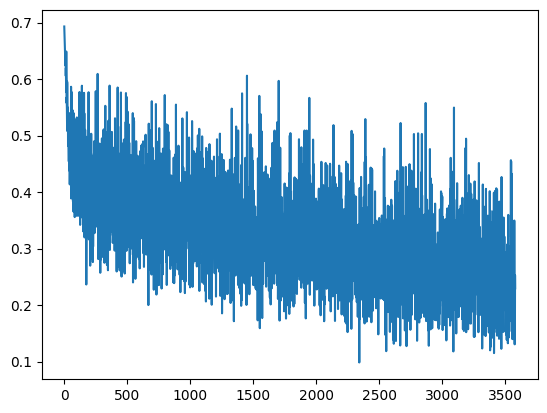

| | | | | | | | | | 

Epoch : 3 # 310
Loss: 0.2092720866203308
Accuracy : 0.9375
F1 Score : 0.9285714030265808
AUC-ROC : 0.9745098352432251
Specificity : 1.0
Recall : 0.8666666746139526
ECE : 0.07392745776451193
--------------------
| | | | | | | | | | 

Epoch : 3 # 320
Loss: 0.1999729871749878
Accuracy : 0.9375
F1 Score : 0.9230769276618958
AUC-ROC : 0.9809809923171997
Specificity : 0.9729729890823364
Recall : 0.8888888955116272
ECE : 0.08094362908741459
--------------------
| | | | | | | | | | 

Epoch : 3 # 330
Loss: 0.2265745997428894
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9661538600921631
Specificity : 0.9487179517745972
Recall : 0.800000011920929
ECE : 0.07318539568223059
--------------------
| | | | | | | | | | 

Epoch : 3 # 340
Loss: 0.3774784803390503
Accuracy : 0.859375
F1 Score : 0.8163265585899353
AUC-ROC : 0.895384669303894
Specificity : 0.8974359035491943
Recall : 0.800000011920929
ECE : 0.0906306414399296
--------------------
| | | | | | | | | | 

E

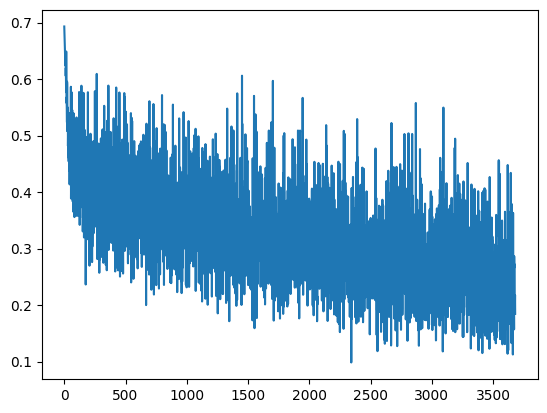

| | | | | | | | | | 

Epoch : 3 # 410
Loss: 0.2502382695674896
Accuracy : 0.921875
F1 Score : 0.8780487775802612
AUC-ROC : 0.9523809552192688
Specificity : 0.976190447807312
Recall : 0.8181818127632141
ECE : 0.07867137197172269
--------------------
| | | | | | | | | | 

Epoch : 3 # 420
Loss: 0.3293049931526184
Accuracy : 0.875
F1 Score : 0.8518518805503845
AUC-ROC : 0.9353846311569214
Specificity : 0.8461538553237915
Recall : 0.9200000166893005
ECE : 0.08414797091973016
--------------------
| | | | | | | | | | 

Epoch : 3 # 430
Loss: 0.3904719948768616
Accuracy : 0.890625
F1 Score : 0.8571428656578064
AUC-ROC : 0.8974359631538391
Specificity : 0.9230769276618958
Recall : 0.8399999737739563
ECE : 0.10009855800308286
--------------------
| | | | | | | | | | 

Epoch : 3 # 440
Loss: 0.4227825105190277
Accuracy : 0.84375
F1 Score : 0.8148148059844971
AUC-ROC : 0.8990195989608765
Specificity : 0.9411764740943909
Recall : 0.7333333492279053
ECE : 0.10352214751765132
--------------------
| | |

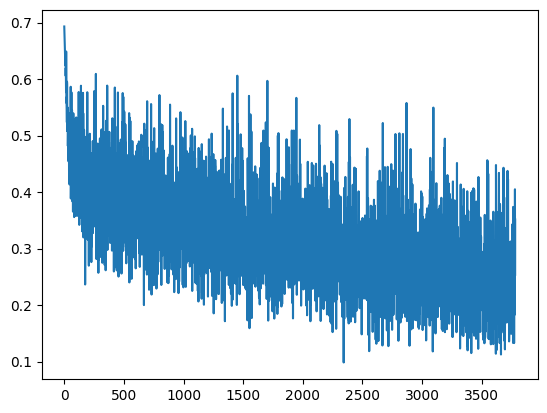

| | | | | | | | | | 

Epoch : 3 # 510
Loss: 0.18641559779644012
Accuracy : 0.9375
F1 Score : 0.9130434989929199
AUC-ROC : 0.9830328822135925
Specificity : 0.9512194991111755
Recall : 0.9130434989929199
ECE : 0.0873116897419095
--------------------
| | | | | | | | | | 

Epoch : 3 # 520
Loss: 0.14361447095870972
Accuracy : 0.96875
F1 Score : 0.9642857313156128
AUC-ROC : 0.9890872836112976
Specificity : 0.9722222089767456
Recall : 0.9642857313156128
ECE : 0.06704064283985645
--------------------
| | | | | | | | | | 

Epoch : 3 # 530
Loss: 0.18599897623062134
Accuracy : 0.921875
F1 Score : 0.9090909361839294
AUC-ROC : 0.9970587491989136
Specificity : 1.0
Recall : 0.8333333134651184
ECE : 0.10237335506826639
--------------------
| | | | | | | | | | 

Epoch : 3 # 540
Loss: 0.22626297175884247
Accuracy : 0.90625
F1 Score : 0.8928571343421936
AUC-ROC : 0.9732142686843872
Specificity : 0.9166666865348816
Recall : 0.8928571343421936
ECE : 0.05563956260448322
--------------------
| | | | | | | | 

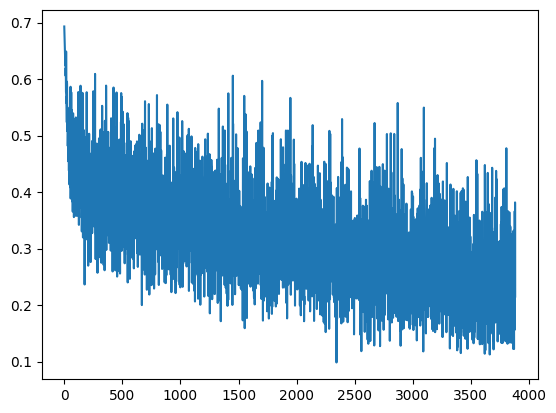

| | | | | | | | | | 

Epoch : 3 # 610
Loss: 0.14945769309997559
Accuracy : 0.953125
F1 Score : 0.9189189076423645
AUC-ROC : 0.9927536249160767
Specificity : 0.95652174949646
Recall : 0.9444444179534912
ECE : 0.07912906887941062
--------------------
| | | | | | | | | | 

Epoch : 3 # 620
Loss: 0.24845105409622192
Accuracy : 0.890625
F1 Score : 0.8444444537162781
AUC-ROC : 0.9642857313156128
Specificity : 0.9047619104385376
Recall : 0.8636363744735718
ECE : 0.08061416377313435
--------------------
| | | | | | | | | | 

Epoch : 3 # 630
Loss: 0.19693247973918915
Accuracy : 0.921875
F1 Score : 0.9152542352676392
AUC-ROC : 0.9803921580314636
Specificity : 0.9411764740943909
Recall : 0.8999999761581421
ECE : 0.096430316218175
--------------------
| | | | | | | | | | 

Epoch : 3 # 640
Loss: 0.2576543390750885
Accuracy : 0.90625
F1 Score : 0.8999999761581421
AUC-ROC : 0.9677419662475586
Specificity : 0.939393937587738
Recall : 0.8709677457809448
ECE : 0.09492715616943315
--------------------
| |

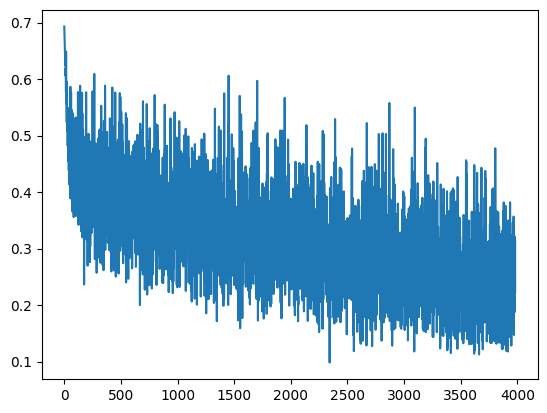

| | | | | | | | | | 

Epoch : 3 # 710
Loss: 0.256660133600235
Accuracy : 0.859375
F1 Score : 0.8301886916160583
AUC-ROC : 0.9609609246253967
Specificity : 0.8918918967247009
Recall : 0.8148148059844971
ECE : 0.08252712825196797
--------------------
| | | | | | | | | | 

Epoch : 3 # 720
Loss: 0.23735061287879944
Accuracy : 0.890625
F1 Score : 0.8372092843055725
AUC-ROC : 0.963203489780426
Specificity : 0.9285714030265808
Recall : 0.8181818127632141
ECE : 0.07338235195493326
--------------------
| | | | | | | | | | 

Epoch : 3 # 730
Loss: 0.20359964668750763
Accuracy : 0.921875
F1 Score : 0.9122806787490845
AUC-ROC : 0.9742063879966736
Specificity : 0.9166666865348816
Recall : 0.9285714030265808
ECE : 0.05815103961504066
--------------------
| | | | | | | | | | 

Epoch : 3 # 740
Loss: 0.13232941925525665
Accuracy : 0.953125
F1 Score : 0.9454545378684998
AUC-ROC : 0.990079402923584
Specificity : 0.9722222089767456
Recall : 0.9285714030265808
ECE : 0.057363355794223025
--------------------

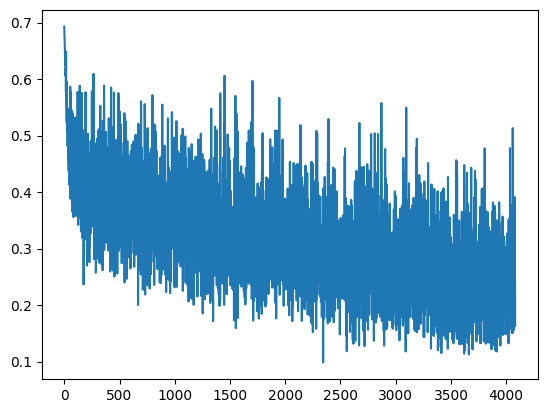

| | | | | | | | | | 

Epoch : 3 # 810
Loss: 0.3006860315799713
Accuracy : 0.875
F1 Score : 0.8518518805503845
AUC-ROC : 0.9484127163887024
Specificity : 0.9166666865348816
Recall : 0.8214285969734192
ECE : 0.0853114859201014
--------------------
| | | | | | | | | | 

Epoch : 3 # 820
Loss: 0.3246418237686157
Accuracy : 0.875
F1 Score : 0.8260869383811951
AUC-ROC : 0.9200000166893005
Specificity : 0.9487179517745972
Recall : 0.7599999904632568
ECE : 0.08394159818999469
--------------------
| | | | | | | | | | 

Epoch : 3 # 830
Loss: 0.3511273264884949
Accuracy : 0.859375
F1 Score : 0.8163265585899353
AUC-ROC : 0.9241025447845459
Specificity : 0.8974359035491943
Recall : 0.800000011920929
ECE : 0.06338537079864182
--------------------
| | | | | | | | | | 

Epoch : 3 # 840
Loss: 0.2716059982776642
Accuracy : 0.859375
F1 Score : 0.8301886916160583
AUC-ROC : 0.9694581031799316
Specificity : 0.9428571462631226
Recall : 0.7586206793785095
ECE : 0.12264046084601432
--------------------
| | | | 

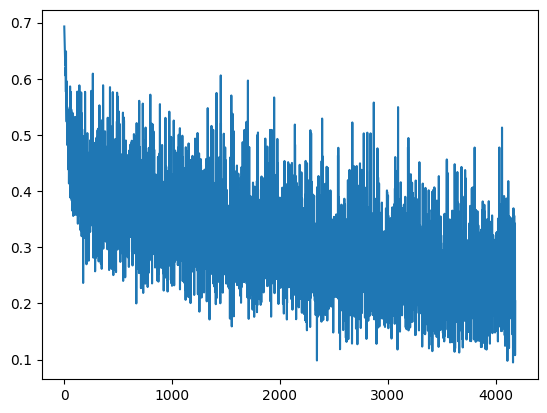

| | | | | | | | | | 

Epoch : 3 # 910
Loss: 0.13219940662384033
Accuracy : 0.96875
F1 Score : 0.9545454382896423
AUC-ROC : 0.9956710338592529
Specificity : 0.976190447807312
Recall : 0.9545454382896423
ECE : 0.09658657072577626
--------------------
| | | | | | | | | | 

Epoch : 3 # 920
Loss: 0.4138748049736023
Accuracy : 0.828125
F1 Score : 0.8307692408561707
AUC-ROC : 0.9769769906997681
Specificity : 0.9629629850387573
Recall : 0.7297297120094299
ECE : 0.17775701347272843
--------------------
| | | | | | | | | | 

Epoch : 3 # 930
Loss: 0.24836532771587372
Accuracy : 0.90625
F1 Score : 0.8571428656578064
AUC-ROC : 0.9624999761581421
Specificity : 0.9090909361839294
Recall : 0.8999999761581421
ECE : 0.08668278955155984
--------------------
| | | | | | | | | | 

Epoch : 3 # 940
Loss: 0.2405414581298828
Accuracy : 0.890625
F1 Score : 0.8727272748947144
AUC-ROC : 0.9666666984558105
Specificity : 0.970588207244873
Recall : 0.800000011920929
ECE : 0.07072473899461329
--------------------
| |

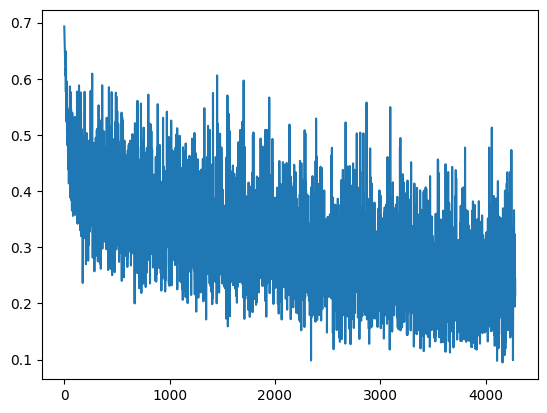

| | | | | | | | | | 

Epoch : 3 # 1010
Loss: 0.2677110433578491
Accuracy : 0.90625
F1 Score : 0.8846153616905212
AUC-ROC : 0.955955982208252
Specificity : 0.9459459185600281
Recall : 0.8518518805503845
ECE : 0.07552033351385035
--------------------
| | | | | | | | | | 

Epoch : 3 # 1020
Loss: 0.24759651720523834
Accuracy : 0.875
F1 Score : 0.8666666746139526
AUC-ROC : 0.9686234593391418
Specificity : 0.7894737124443054
Recall : 1.0
ECE : 0.07581200427375734
--------------------
| | | | | | | | | | 

Epoch : 3 # 1030
Loss: 0.23016342520713806
Accuracy : 0.875
F1 Score : 0.8399999737739563
AUC-ROC : 0.971875011920929
Specificity : 0.875
Recall : 0.875
ECE : 0.10288097709417343
--------------------
| | | | | | | | | | 

Epoch : 3 # 1040
Loss: 0.2657727897167206
Accuracy : 0.890625
F1 Score : 0.8727272748947144
AUC-ROC : 0.9596059322357178
Specificity : 0.9428571462631226
Recall : 0.8275862336158752
ECE : 0.06125026324298233
--------------------
| | | | | | | | | | 

Epoch : 3 # 1050
Loss:

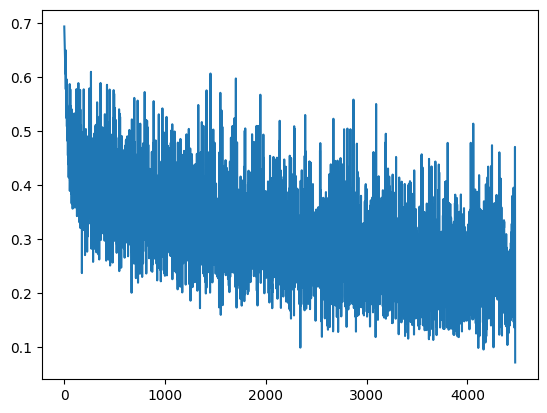

| | | | | | | | | | 

Epoch : 4 # 110
Loss: 0.12454897165298462
Accuracy : 0.953125
F1 Score : 0.936170220375061
AUC-ROC : 0.9947916865348816
Specificity : 0.9750000238418579
Recall : 0.9166666865348816
ECE : 0.07841650967020541
--------------------
| | | | | | | | | | 

Epoch : 4 # 120
Loss: 0.26677021384239197
Accuracy : 0.859375
F1 Score : 0.8363636136054993
AUC-ROC : 0.9686274528503418
Specificity : 0.9411764740943909
Recall : 0.7666666507720947
ECE : 0.08120717538986355
--------------------
| | | | | | | | | | 

Epoch : 4 # 130
Loss: 0.21955548226833344
Accuracy : 0.90625
F1 Score : 0.8928571343421936
AUC-ROC : 0.9812808036804199
Specificity : 0.9428571462631226
Recall : 0.8620689511299133
ECE : 0.10316926660016179
--------------------
| | | | | | | | | | 

Epoch : 4 # 140
Loss: 0.1959221512079239
Accuracy : 0.921875
F1 Score : 0.9019607901573181
AUC-ROC : 0.9819819927215576
Specificity : 0.9729729890823364
Recall : 0.8518518805503845
ECE : 0.06674474474857561
--------------------

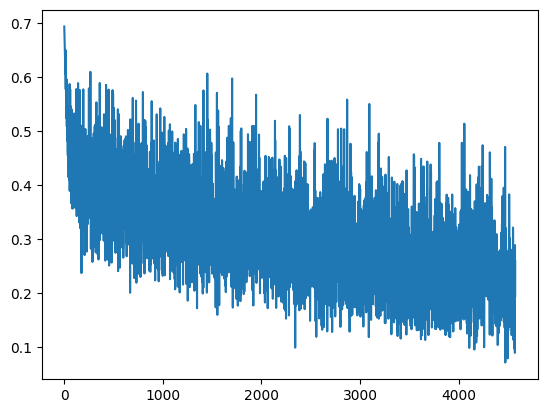

| | | | | | | | | | 

Epoch : 4 # 210
Loss: 0.2765994668006897
Accuracy : 0.890625
F1 Score : 0.8571428656578064
AUC-ROC : 0.9548717737197876
Specificity : 0.9230769276618958
Recall : 0.8399999737739563
ECE : 0.08009937638416886
--------------------
| | | | | | | | | | 

Epoch : 4 # 220
Loss: 0.28584617376327515
Accuracy : 0.875
F1 Score : 0.8399999737739563
AUC-ROC : 0.9425641298294067
Specificity : 0.8974359035491943
Recall : 0.8399999737739563
ECE : 0.08650229033082724
--------------------
| | | | | | | | | | 

Epoch : 4 # 230
Loss: 0.15024513006210327
Accuracy : 0.953125
F1 Score : 0.930232584476471
AUC-ROC : 0.9954545497894287
Specificity : 0.9318181872367859
Recall : 1.0
ECE : 0.07646126806503162
--------------------
| | | | | | | | | | 

Epoch : 4 # 240
Loss: 0.1457904577255249
Accuracy : 0.9375
F1 Score : 0.9259259104728699
AUC-ROC : 0.9909909963607788
Specificity : 0.9459459185600281
Recall : 0.9259259104728699
ECE : 0.0664938249392435
--------------------
| | | | | | | | | | 

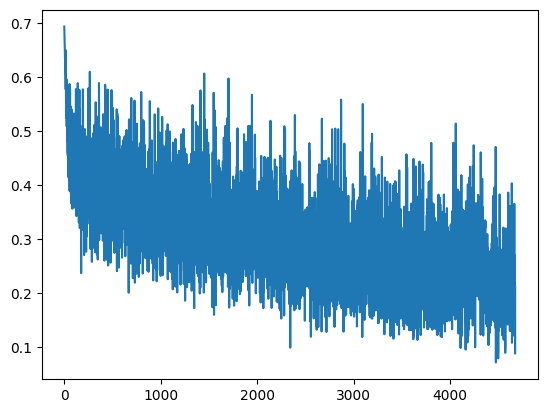

| | | | | | | | | | 

Epoch : 4 # 310
Loss: 0.2476537525653839
Accuracy : 0.875
F1 Score : 0.8260869383811951
AUC-ROC : 0.9818181991577148
Specificity : 0.8409090638160706
Recall : 0.949999988079071
ECE : 0.11217218765523285
--------------------
| | | | | | | | | | 

Epoch : 4 # 320
Loss: 0.2661243975162506
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9572917222976685
Specificity : 0.925000011920929
Recall : 0.8333333134651184
ECE : 0.10573895508423446
--------------------
| | | | | | | | | | 

Epoch : 4 # 330
Loss: 0.3762178421020508
Accuracy : 0.890625
F1 Score : 0.8444444537162781
AUC-ROC : 0.9390919208526611
Specificity : 0.8837209343910217
Recall : 0.9047619104385376
ECE : 0.10064353561028838
--------------------
| | | | | | | | | | 

Epoch : 4 # 340
Loss: 0.1180577352643013
Accuracy : 0.953125
F1 Score : 0.9523809552192688
AUC-ROC : 0.9980449676513672
Specificity : 1.0
Recall : 0.9090909361839294
ECE : 0.08110820391448215
--------------------
| | | | | | | | | | 

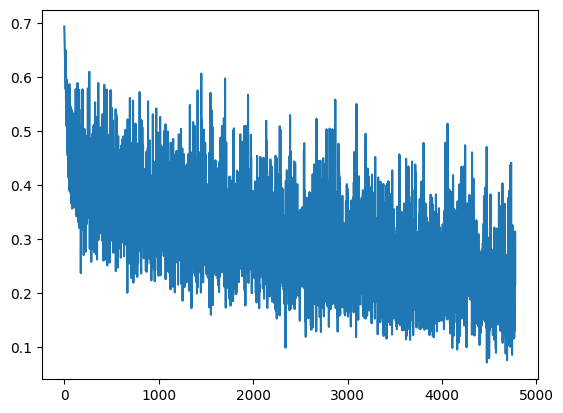

| | | | | | | | | | 

Epoch : 4 # 410
Loss: 0.146022766828537
Accuracy : 0.9375
F1 Score : 0.9130434989929199
AUC-ROC : 0.9916666746139526
Specificity : 0.9750000238418579
Recall : 0.875
ECE : 0.0825381359027233
--------------------
| | | | | | | | | | 

Epoch : 4 # 420
Loss: 0.15077868103981018
Accuracy : 0.9375
F1 Score : 0.9375
AUC-ROC : 0.9882698059082031
Specificity : 0.9677419066429138
Recall : 0.9090909361839294
ECE : 0.08746823441470042
--------------------
| | | | | | | | | | 

Epoch : 4 # 430
Loss: 0.12486709654331207
Accuracy : 0.96875
F1 Score : 0.9642857313156128
AUC-ROC : 0.9910714030265808
Specificity : 0.9722222089767456
Recall : 0.9642857313156128
ECE : 0.054371126927435384
--------------------
| | | | | | | | | | 

Epoch : 4 # 440
Loss: 0.23776645958423615
Accuracy : 0.890625
F1 Score : 0.8888888955116272
AUC-ROC : 0.9803922176361084
Specificity : 0.9666666388511658
Recall : 0.8235294222831726
ECE : 0.14240461180452257
--------------------
| | | | | | | | | | 

Epoch 

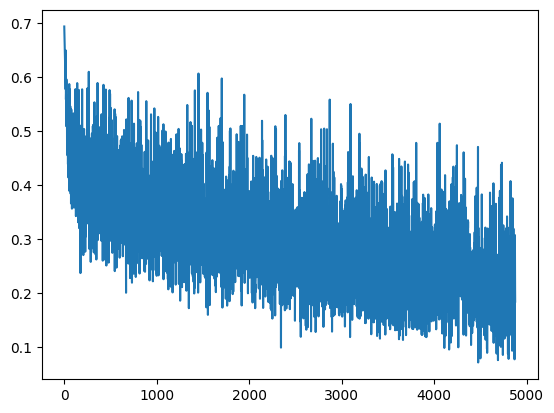

| | | | | | | | | | 

Epoch : 4 # 510
Loss: 0.36995816230773926
Accuracy : 0.828125
F1 Score : 0.8358209133148193
AUC-ROC : 0.9629629850387573
Specificity : 0.9259259104728699
Recall : 0.7567567825317383
ECE : 0.1238139986526221
--------------------
| | | | | | | | | | 

Epoch : 4 # 520
Loss: 0.19418130815029144
Accuracy : 0.9375
F1 Score : 0.9285714030265808
AUC-ROC : 0.9743842482566833
Specificity : 0.9714285731315613
Recall : 0.8965517282485962
ECE : 0.04268781444989145
--------------------
| | | | | | | | | | 

Epoch : 4 # 530
Loss: 0.12536951899528503
Accuracy : 0.9375
F1 Score : 0.9354838728904724
AUC-ROC : 0.9921798706054688
Specificity : 0.939393937587738
Recall : 0.9354838728904724
ECE : 0.06983719766139984
--------------------
| | | | | | | | | | 

Epoch : 4 # 540
Loss: 0.42816150188446045
Accuracy : 0.84375
F1 Score : 0.7727272510528564
AUC-ROC : 0.8914728760719299
Specificity : 0.8604651093482971
Recall : 0.8095238208770752
ECE : 0.12134533218340948
--------------------
| |

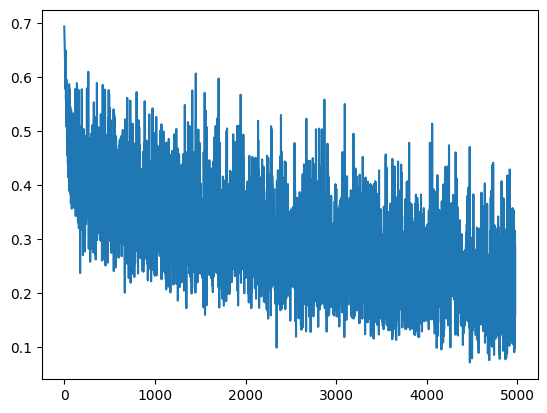

| | | | | | | | | | 

Epoch : 4 # 610
Loss: 0.18308493494987488
Accuracy : 0.953125
F1 Score : 0.936170220375061
AUC-ROC : 0.9750000238418579
Specificity : 0.9750000238418579
Recall : 0.9166666865348816
ECE : 0.06170754510094413
--------------------
| | | | | | | | | | 

Epoch : 4 # 620
Loss: 0.14776799082756042
Accuracy : 0.9375
F1 Score : 0.9166666865348816
AUC-ROC : 0.9915164709091187
Specificity : 0.9268292784690857
Recall : 0.95652174949646
ECE : 0.06490144299459644
--------------------
| | | | | | | | | | 

Epoch : 4 # 630
Loss: 0.3194739520549774
Accuracy : 0.875
F1 Score : 0.8666666746139526
AUC-ROC : 0.9589443206787109
Specificity : 0.9677419066429138
Recall : 0.7878788113594055
ECE : 0.10892022744519637
--------------------
| | | | | | | | | | 

Epoch : 4 # 640
Loss: 0.25896310806274414
Accuracy : 0.890625
F1 Score : 0.8510638475418091
AUC-ROC : 0.9558974504470825
Specificity : 0.9487179517745972
Recall : 0.800000011920929
ECE : 0.0743431153241545
--------------------
| | | |

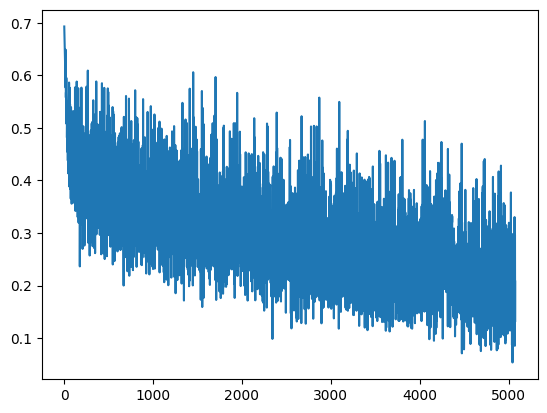

| | | | | | | | | | 

Epoch : 4 # 710
Loss: 0.1236695796251297
Accuracy : 0.953125
F1 Score : 0.9433962106704712
AUC-ROC : 0.9949392676353455
Specificity : 0.9473684430122375
Recall : 0.9615384340286255
ECE : 0.07803957618307322
--------------------
| | | | | | | | | | 

Epoch : 4 # 720
Loss: 0.33037644624710083
Accuracy : 0.921875
F1 Score : 0.8936170339584351
AUC-ROC : 0.9268293380737305
Specificity : 0.9268292784690857
Recall : 0.9130434989929199
ECE : 0.07104080321732908
--------------------
| | | | | | | | | | 

Epoch : 4 # 730
Loss: 0.13652896881103516
Accuracy : 0.921875
F1 Score : 0.9056603908538818
AUC-ROC : 0.9888663291931152
Specificity : 0.9210526347160339
Recall : 0.9230769276618958
ECE : 0.07454215141478926
--------------------
| | | | | | | | | | 

Epoch : 4 # 740
Loss: 0.2008989453315735
Accuracy : 0.9375
F1 Score : 0.9130434989929199
AUC-ROC : 0.97510826587677
Specificity : 0.9285714030265808
Recall : 0.9545454382896423
ECE : 0.11722061806358397
--------------------
| 

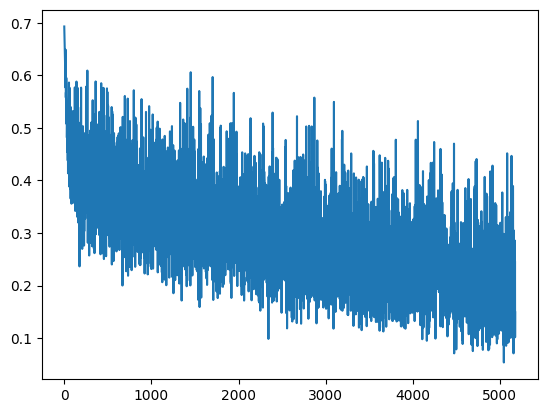

| | | | | | | | | | 

Epoch : 4 # 810
Loss: 0.16546368598937988
Accuracy : 0.9375
F1 Score : 0.9166666865348816
AUC-ROC : 0.984375
Specificity : 0.949999988079071
Recall : 0.9166666865348816
ECE : 0.06427475687814876
--------------------
| | | | | | | | | | 

Epoch : 4 # 820
Loss: 0.11933556944131851
Accuracy : 0.984375
F1 Score : 0.9803921580314636
AUC-ROC : 0.9979486465454102
Specificity : 0.9743589758872986
Recall : 1.0
ECE : 0.07943939429242164
--------------------
| | | | | | | | | | 

Epoch : 4 # 830
Loss: 0.2675442695617676
Accuracy : 0.921875
F1 Score : 0.9019607901573181
AUC-ROC : 0.950769305229187
Specificity : 0.9230769276618958
Recall : 0.9200000166893005
ECE : 0.08352682142867707
--------------------
| | | | | | | | | | 

Epoch : 4 # 840
Loss: 0.18705789744853973
Accuracy : 0.921875
F1 Score : 0.8888888955116272
AUC-ROC : 0.9848484992980957
Specificity : 0.9285714030265808
Recall : 0.9090909361839294
ECE : 0.07021677089505829
--------------------
| | | | | | | | | | 

Epoc

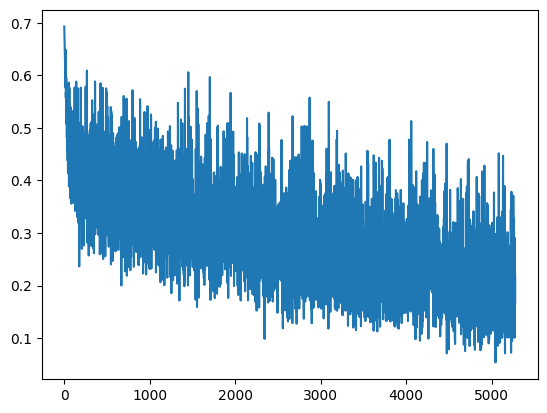

| | | | | | | | | | 

Epoch : 4 # 910
Loss: 0.193490132689476
Accuracy : 0.953125
F1 Score : 0.9411764740943909
AUC-ROC : 0.9769769310951233
Specificity : 1.0
Recall : 0.8888888955116272
ECE : 0.07574950630078092
--------------------
| | | | | | | | | | 

Epoch : 4 # 920
Loss: 0.19388607144355774
Accuracy : 0.921875
F1 Score : 0.9122806787490845
AUC-ROC : 0.9970674514770508
Specificity : 1.0
Recall : 0.8387096524238586
ECE : 0.10709840001072735
--------------------
| | | | | | | | | | 

Epoch : 4 # 930
Loss: 0.09805424511432648
Accuracy : 0.96875
F1 Score : 0.9599999785423279
AUC-ROC : 0.9989582896232605
Specificity : 0.949999988079071
Recall : 1.0
ECE : 0.06063500908203423
--------------------
| | | | | | | | | | 

Epoch : 4 # 940
Loss: 0.25150078535079956
Accuracy : 0.875
F1 Score : 0.8181818127632141
AUC-ROC : 0.9754385948181152
Specificity : 0.8444444537162781
Recall : 0.9473684430122375
ECE : 0.09919596731197089
--------------------
| | | | | | | | | | 

Epoch : 4 # 950
Loss: 0.17

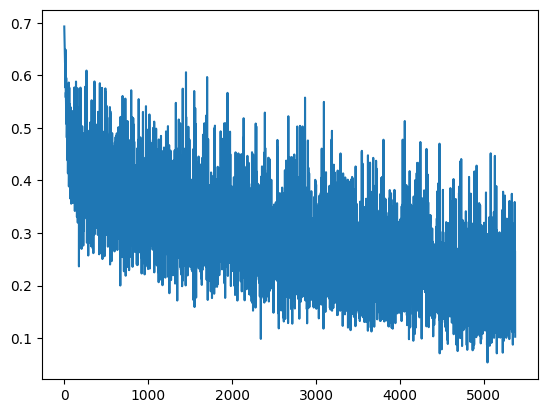

| | | | | | | | | | 

Epoch : 4 # 1010
Loss: 0.1829899549484253
Accuracy : 0.921875
F1 Score : 0.9056603908538818
AUC-ROC : 0.9797570705413818
Specificity : 0.9210526347160339
Recall : 0.9230769276618958
ECE : 0.07687764579895884
--------------------
| | | | | | | | | | 

Epoch : 4 # 1020
Loss: 0.15804193913936615
Accuracy : 0.9375
F1 Score : 0.9166666865348816
AUC-ROC : 0.9906250238418579
Specificity : 0.949999988079071
Recall : 0.9166666865348816
ECE : 0.04960620537167415
--------------------
| | | | | | | | | | 

Epoch : 4 # 1030
Loss: 0.25593897700309753
Accuracy : 0.875
F1 Score : 0.8461538553237915
AUC-ROC : 0.9630769491195679
Specificity : 0.8717948794364929
Recall : 0.8799999952316284
ECE : 0.06950710417004302
--------------------
| | | | | | | | | | 

Epoch : 4 # 1040
Loss: 0.16661903262138367
Accuracy : 0.9375
F1 Score : 0.9047619104385376
AUC-ROC : 0.987500011920929
Specificity : 0.9318181872367859
Recall : 0.949999988079071
ECE : 0.072135462454753
--------------------
| | |

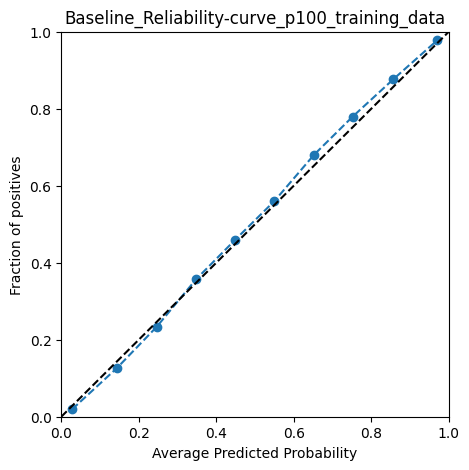

In [ ]:
epochs=5
loss_dict_FL={}
lossFn=nn.BCEWithLogitsLoss()

linear_DS=DT(layer_list,True,labels,p=100)
DL=DataLoader(
    dataset=linear_DS,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=False,
    persistent_workers=True
  )

    # optimizer_FL=torch.optim.AdamW(Final_Layer.parameters(),lr=1e-5,weight_decay=1e-4)
    # d={}
min_loss=None
l=[]
for epoch in range(epochs):
    c=0
    y_result_accumulated=torch.tensor([]).to(device)
    y_real_accumulated=torch.tensor([]).to(device)
    for x,y in DL:
        x,y=x.to(device),y.to(device)
        optimizer_BL.zero_grad()

        h,_=BLEncoder(x)
        y_result=BLFinal_Layer(h).squeeze(1)
        loss=lossFn(y_result,y.float())
        loss.backward()
        optimizer_BL.step()
        c+=1
        l.append(loss.item())
        y_result=torch.sigmoid(y_result)
        y_result_accumulated=torch.cat([y_result_accumulated,y_result])
        y_real_accumulated=torch.cat([y_real_accumulated,y])
        print("|",end=" ")
        if(c%10==0):
            print("\n")
            print(f"Epoch : {epoch} # {c}")
            print(f"Loss: {loss.item()}")
            metrics_display(y_real=y,y_result=y_result)
            print("-"*20)
            if(min_loss is None or loss.item()<=min_loss):
                min_loss=loss.item()
                addr="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLFinal_Layer.pth"
                torch.save(BLFinal_Layer.state_dict(),addr)
                addr="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLEncoder.pth"
                torch.save(BLEncoder.state_dict(),addr)
            if c%100==0:
                plt.plot(l)
                plt.show()
        # d[epoch]=l
    print("-"*20)
    print(f"Epoch#{epoch}")
    metrics_display(y_real=y_real_accumulated.long(),y_result=y_result_accumulated)
    print("-"*20)
reliability_plot(y_real=y_real_accumulated.long(),y_result=y_result_accumulated,save_img=True,title="Baseline_Reliability-curve_p100_training_data")
loss_dict_BL=l


## Evaluation of Baseline and the Model on Eval dataset

### Baseline evaluation


70026 images loaded successfully
Accuracy : 0.8053151965141296
F1 Score : 0.6910648345947266
AUC-ROC : 0.9333192706108093
Specificity : 0.9883022904396057
Recall : 0.5370148420333862
ECE : 0.1762230546363095


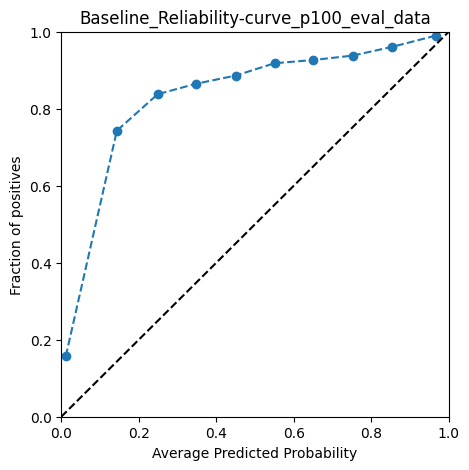

In [ ]:
gc.collect()
torch.cuda.empty_cache()

BLEncoder = Encoder().to(device)
BLFinal_Layer = Linear_Layer().to(device)
BLEncoder.load_state_dict(torch.load(
    '/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLEncoder.pth',
    weights_only=True, map_location=device))
BLFinal_Layer.load_state_dict(torch.load(
    '/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BLFinal_Layer.pth',
    weights_only=True, map_location=device))
BLEncoder.eval()
BLFinal_Layer.eval()

eval_DS = DT(test_list, True, labels, p=100)
DL = DataLoader(
    dataset=eval_DS,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

preds, reals = [], []
with torch.inference_mode():
    for i, (x, y) in enumerate(DL):
        x = x.to(device, non_blocking=True)
        h, _ = BLEncoder(x)
        p = torch.sigmoid(BLFinal_Layer(h).squeeze(1))
        preds.append(p.cpu())
        reals.append(y.cpu())
        if i % 50 == 0:
            print(f"batch {i}/{len(DL)}", end="\r")

y_result_accumulated = torch.cat(preds)
y_real_accumulated = torch.cat(reals)
del preds, reals
gc.collect()

metrics_display(y_real=y_real_accumulated.long(), y_result=y_result_accumulated)
BL_metrics = metrics_dict_creator(y_real=y_real_accumulated.long(), y_result=y_result_accumulated)
BL_mmetrics={k: float(v) for k, v in BL_metrics.items()}
BL_metrics_df = pd.DataFrame(BL_metrics, index=[0])
reliability_plot(y_real=y_real_accumulated, y_result=y_result_accumulated,
                 save_img=True, title="Baseline_Reliability-curve_p100_eval_data")

In [ ]:
BL_metrics_df

,Accuracy,F1 Score,AUC-ROC,Specificity,Recall,ECE
0,tensor(0.8053),tensor(0.6911),tensor(0.9333),tensor(0.9883),tensor(0.5370),0.176223


In [ ]:
BL_metrics_df.to_csv("/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/BL_metrics.csv")

### Model


700 images loaded successfully


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


| | | | | | | | | | | 
Accuracy : 0.6857143044471741
F1 Score : 0.375
AUC-ROC : 0.8386716842651367
Specificity : 0.978723406791687
Recall : 0.23826715350151062
ECE : 0.19851841926574706


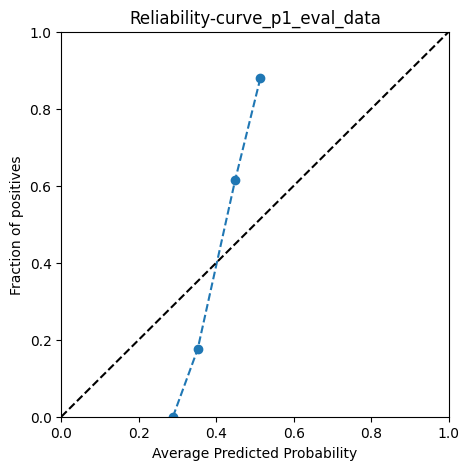

3500 images loaded successfully
| | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | 
Accuracy : 0.7934285998344421
F1 Score : 0.7174677848815918
AUC-ROC : 0.8558952212333679
Specificity : 0.8911792635917664
Recall : 0.6492220759391785
ECE : 0.12717603259427207


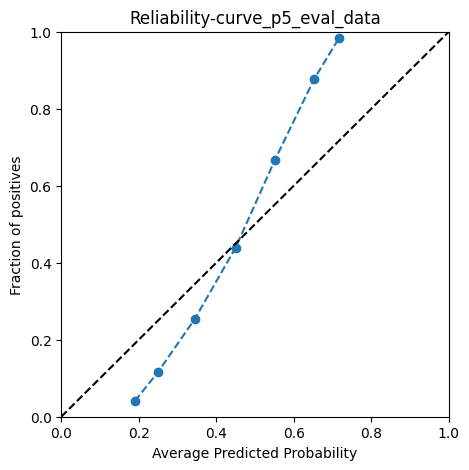

7000 images loaded successfully
| | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | 
Accuracy : 0.7885714173316956
F1 Score : 0.7176650166511536
AUC-ROC : 0.8517862558364868
Specificity : 0.8838960528373718
Recall : 0.652445375919342
ECE : 0.09896717021507877


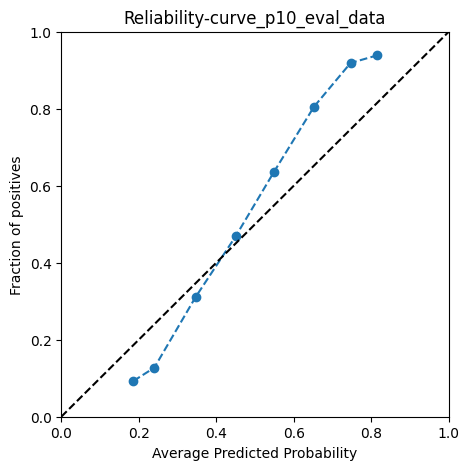

70026 images loaded successfully
| | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | |

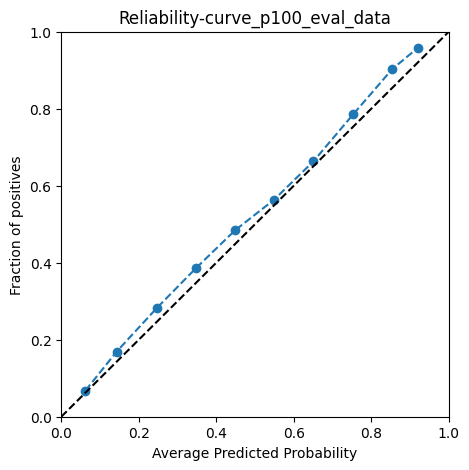

                                         1                                5    \
Accuracy     tensor(0.6857, device='cuda:0')  tensor(0.7934, device='cuda:0')   
F1 Score     tensor(0.3750, device='cuda:0')  tensor(0.7175, device='cuda:0')   
AUC-ROC      tensor(0.8387, device='cuda:0')  tensor(0.8559, device='cuda:0')   
Specificity  tensor(0.9787, device='cuda:0')  tensor(0.8912, device='cuda:0')   
Recall       tensor(0.2383, device='cuda:0')  tensor(0.6492, device='cuda:0')   
ECE                                 0.198518                         0.127176   

                                         10                               100  
Accuracy     tensor(0.7886, device='cuda:0')  tensor(0.7986, device='cuda:0')  
F1 Score     tensor(0.7177, device='cuda:0')  tensor(0.7317, device='cuda:0')  
AUC-ROC      tensor(0.8518, device='cuda:0')  tensor(0.8693, device='cuda:0')  
Specificity  tensor(0.8839, device='cuda:0')  tensor(0.8816, device='cuda:0')  
Recall       tensor(0.6524, devi

In [ ]:

for lp in label_percent:
    addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Final_Layer_p{lp}.pth"
    Final_Layer=Linear_Layer().to(device)
    Final_Layer.load_state_dict(torch.load(addr,weights_only=True))
    addr=f"/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth"
    SSLEncoder=Encoder().to(device)
    SSLEncoder.load_state_dict(torch.load(addr,weights_only=True))
    SSLEncoder.eval()
    Final_Layer.eval()
    eval_DS=DT(test_list,True,labels,p=lp)
    DL=DataLoader(
        dataset=eval_DS,
        batch_size=64,
        shuffle=True,
        num_workers=4,
        pin_memory=False,
        persistent_workers=True
    )
    y_result_accumulated=torch.tensor([]).to(device)
    y_real_accumulated=torch.tensor([]).to(device)
    for x,y in DL:
        x,y=x.to(device),y.to(device)
        with torch.no_grad():
            h,_=SSLEncoder(x)
            y_result=Final_Layer(h).squeeze(1)
            y_result=torch.sigmoid(y_result)
        y_result_accumulated=torch.cat([y_result_accumulated,y_result])
        y_real_accumulated=torch.cat([y_real_accumulated,y]).long()
        print("|",end=" ")
    print()
    metrics_display(y_real=y_real_accumulated,y_result=y_result_accumulated)
    label_percentwise_metrics[lp]=metrics_dict_creator(y_real=y_real_accumulated,y_result=y_result_accumulated)
    reliability_plot(y_real=y_real_accumulated,y_result=y_result_accumulated,save_img=True,title=f"Reliability-curve_p{lp}_eval_data")

label_percentwise_metrics_df=pd.DataFrame(label_percentwise_metrics)
print(label_percentwise_metrics_df)

In [ ]:
label_percentwise_metrics_df.to_csv("/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Model_metrics.csv")

## Grad - CAM
- used for model interpretability
- creates a heatmap of feature space based on gradient-weighted sum of features maps

In [92]:
class GradCam():
  def __init__(self,encoder,final_layer,target_layer):
    self.encoder=encoder
    self.final_layer=final_layer
    self.device = next(encoder.parameters()).device
    self.target_layer=target_layer
    self.gradients=None
    self.activations=None

    self.encoder.zero_grad()
    self.final_layer.zero_grad()
    self.encoder.requires_grad_(True)
    self.final_layer.requires_grad_(True)
    self.target_layer.register_forward_hook(self.save_activations)
    self.target_layer.register_backward_hook(self.save_grad)
  def forward(self,x):
    x1,_=self.encoder(x)
    x2=self.final_layer(x1)
    return x2


  def save_grad(self,module,grad_input,grad_output):
    self.gradients=grad_output[0]


  def save_activations(self,module,input,output):
    self.activations=output

  def generate(self,image,class_idx=None):

    image=image.to(self.device)
    self.encoder.zero_grad()
    self.final_layer.zero_grad()
    output=self.forward(image)
    logit = output[:, 0]

    if class_idx is None:
        class_idx = (logit >= 0).long().item()


    score = logit if class_idx == 1 else -logit

    score.sum().backward()
    actv=self.activations
    grad=self.gradients

    weights=grad.mean(dim=(2,3),keepdim=True)

    cam=(weights*actv).sum(dim=1)
    cam=F.relu(cam)
    cam=cam-cam.min()
    cam=cam/(cam.max()+1e-8)
    cam=F.interpolate(cam.unsqueeze(0),size=image.shape[2:],mode='bilinear',align_corners=False)
    return cam.squeeze().detach(),class_idx


In [93]:
Encoder_dir="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/SSLEncoder.pth"
LLayer_dir="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect/Final_Layer_p100.pth"
SSLEncoder.load_state_dict(torch.load(Encoder_dir,weights_only=True))
Final_Layer.load_state_dict(torch.load(LLayer_dir,weights_only=True))
SSLEncoder.eval()
Final_Layer.eval()
SSLEncoder.to(device)
Final_Layer.to(device)

Linear_Layer(
  (ll): Sequential(
    (0): Linear(in_features=512, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [94]:
target_layer=[l for l in SSLEncoder.modules() if isinstance(l,nn.Conv2d)][-1]
print(target_layer)

Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


In [95]:
gradcam=GradCam(SSLEncoder,Final_Layer,target_layer)
eval_DS=DT(test_list,True,labels,p=5)
DL=DataLoader(
        dataset=eval_DS,
        batch_size=1,
        shuffle=True,
        num_workers=1,
        pin_memory=False,
        persistent_workers=True
    )

3500 images loaded successfully


In [96]:
def show_gradcam(x,y,alpha=0.3,save=False,dir=None,title=None):



  cam,class_idx=gradcam.generate(x,class_idx=y.item())
  image=denorm(x.cpu().squeeze()).permute(1,2,0)
  cam=cam.cpu().numpy()
  cam_colored=plt.cm.jet(cam)[...,:3]
  image_norm=(image/255.0)
  image_with_cam=image*alpha+cam_colored*(1-alpha)
  plt.subplot(1,2,1)
  plt.imshow(image)
  plt.title(f"Image y={class_idx}")
  plt.subplot(1,2,2)
  plt.imshow(image_with_cam)
  plt.title("Grad-CAM")
  plt.show()
  if save:
    if dir is not None:
      dir=os.path.join(dir,f"{title}.png")
      plt.imsave(dir,image_with_cam)
      print("image saved")
    else:
      print("dir is not specified")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1874: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
/tmp/ipykernel_1592/597447975.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  image_with_cam=image*alpha+cam_colored*(1-alpha)


----------------------------------------


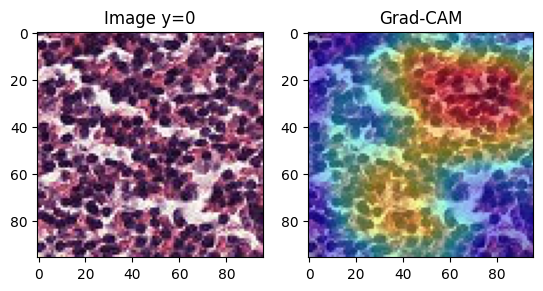

image saved
----------------------------------------


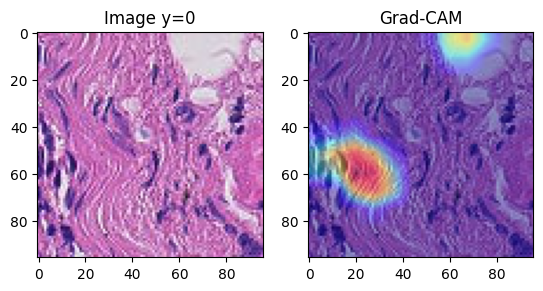

image saved
----------------------------------------


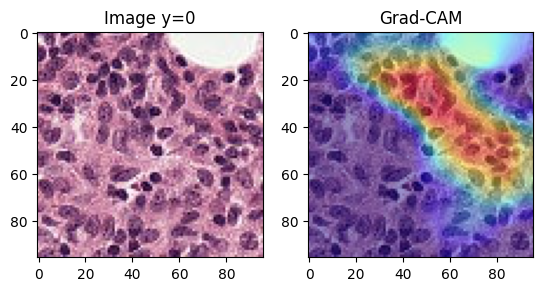

image saved
----------------------------------------


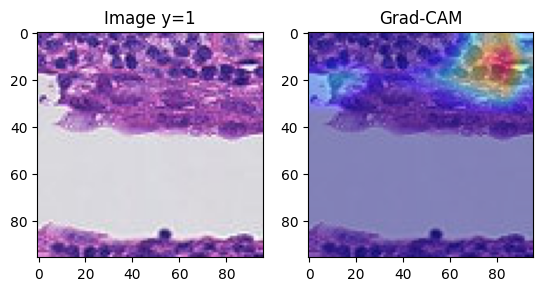

image saved
----------------------------------------


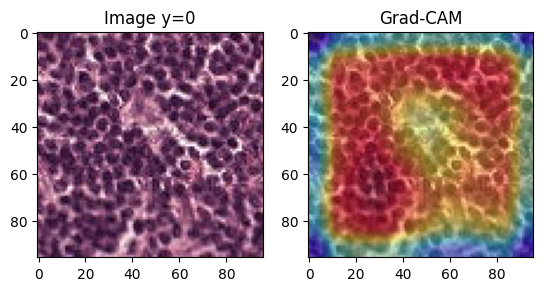

image saved


In [97]:
c=0
alpha=0.6
dir="/content/drive/MyDrive/Colab Notebooks/SSL_histo_cancer_detect"
for c in range(5):
  x,y=next(iter(DL))
  print("--"*20)
  show_gradcam(x,y,alpha=alpha,save=True,dir=dir,title=f"Grad-CAM_{c}")


